# **INF4248 TP FINAL :** ANALYSE DU D4D POUR AMÉLIORER LA MOBILITÉ AU SÉNÉGAL


## I -  Analyse Exploratoire Approfondie (EDA) — D4D Sénégal


### Objectif de cette première partie du Notebook

Ce notebook constitue la **première étape obligatoire** avant tout prétraitement. Son rôle est de :

1. **Comprendre** la structure, la qualité et les distributions de nos 3 jeux de données principaux (SET1, SET2, SET3).
2. **Visualiser** les flux de communication et de mobilité pour détecter les patterns spatiaux et temporels.
3. **Détecter** les anomalies, valeurs manquantes et biais de captation (déséquilibre des antennes).
4. **Explorer** les corrélations entre les variables et entre les datasets.
5. **Définir** ce que signifie une « zone critique » et justifier mathématiquement le filtrage géographique.
6. **Classer** les régions, départements et arrondissements par volume de trafic et mobilité.

**À l'issue de cette EDA, nous saurons exactement quelles zones conserver pour nos algorithmes de ML/DL.**

---

### Rappel des Données

| Dataset | Contenu | Granularité | Fichiers | Période |
|---------|---------|-------------|----------|--------|
| **SET1** | Appels (V) et SMS (S) entre antennes, agrégés par heure | Site → Site (1666 antennes) | 24 fichiers .gz (~9 Go compressés) | Jan–Déc 2013 |
| **SET2** | Trajectoires individuelles (positions successives d'utilisateurs anonymisés) | Site (1666 antennes) | 25 périodes de 2 semaines (.gz) | Toute l'année 2013 |
| **SET3** | Trajectoires individuelles (positions successives) | Arrondissement (123 zones) | 12 fichiers mensuels (.gz) | Jan–Déc 2013 |
| **INDICATORS SET2/SET3** | 37 indicateurs comportementaux par utilisateur (Bandicoot) | Utilisateur | 25+12 fichiers | Toute l'année 2013 |
| **ContextData** | Mapping sites→arrondissements, coordonnées GPS, shapefile | — | Fichiers de référence | — |

#### Format brut de chaque SET

- **SET1V** (Voix) : `timestamp(YYYY-MM-DD HH)`, `origin_site`, `dest_site`, `nb_appels`, `duree_totale_sec`
- **SET1S** (SMS) : `timestamp(YYYY-MM-DD HH)`, `origin_site`, `dest_site`, `nb_sms`
- **SET2** (Trajectoires) : `userid`, `timestamp(YYYY-MM-DD HH:MM:SS)`, `site_id`
- **SET3** (Trajectoires) : `userid`, `timestamp(YYYY-MM-DD HH:MM:SS)`, `arr_id`

---
## PARTIE 1 — PREMIÈRE ÉTUDE DU DATASET SET1 ET SET 3 SUR LA PÉRIODE DE JANVIER 2013

### A - Chargement des Données de Référence et Infrastructure

Avant d'explorer les flux, nous devons d'abord comprendre l'infrastructure elle-même : combien d'antennes, où sont-elles, comment sont-elles réparties ?

In [25]:
# ============================================================
# A.1 — Imports et Configuration
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import geopandas as gpd
from pathlib import Path
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Style visuel professionnel
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.family': 'sans-serif'
})

# Chemins
DATA_DIR = Path('../..')
SET1_DIR = DATA_DIR / 'SET1'
SET2_DIR = DATA_DIR / 'SET2'
SET3_DIR = DATA_DIR / 'SET3'
CTX_DIR  = DATA_DIR / 'ContextData'

print('Chemins configurés :')
for name, p in [('SET1', SET1_DIR), ('SET2', SET2_DIR), ('SET3', SET3_DIR), ('Context', CTX_DIR)]:
    print(f'  {name}: {p.resolve()} — existe: {p.exists()}')

Chemins configurés :
  SET1: C:\Users\REGI GROUP\Desktop\DATA\Data\SET1 — existe: True
  SET2: C:\Users\REGI GROUP\Desktop\DATA\Data\SET2 — existe: True
  SET3: C:\Users\REGI GROUP\Desktop\DATA\Data\SET3 — existe: True
  Context: C:\Users\REGI GROUP\Desktop\DATA\Data\ContextData — existe: True


In [26]:
# ============================================================
# A.2 — Chargement de la hiérarchie géographique
#        Sénégal : 14 Régions → 45 Départements → 123 Arrondissements → 1666 Antennes
# ============================================================
df_arr = pd.read_csv(CTX_DIR / 'SENEGAL_ARR_V2.csv')
df_arr.columns = ['arr_id', 'region', 'department', 'arrondissement']

df_sites = pd.read_csv(CTX_DIR / 'SITE_ARR_LONLAT.CSV')
# Jointure pour enrichir chaque site avec sa hiérarchie géographique
df_sites = df_sites.merge(df_arr, on='arr_id', how='left')

print(f"Nombre total d'antennes (sites) : {df_sites['site_id'].nunique()}")
print(f"Nombre d'arrondissements        : {df_arr.shape[0]}")
print(f"Nombre de départements           : {df_arr['department'].nunique()}")
print(f"Nombre de régions                : {df_arr['region'].nunique()}")
print()
print('Aperçu de la table des arrondissements :')
display(df_arr.head(10))

Nombre total d'antennes (sites) : 1666
Nombre d'arrondissements        : 123
Nombre de départements           : 45
Nombre de régions                : 14

Aperçu de la table des arrondissements :


,arr_id,region,department,arrondissement
0,1,DAKAR,DAKAR,PARCELLES ASSAINIES
1,2,DAKAR,DAKAR,ALMADIES
2,3,DAKAR,DAKAR,GRAND DAKAR
3,4,DAKAR,DAKAR,DAKAR PLATEAU
4,5,DAKAR,GUEDIAWAYE,GUEDIAWAYE
5,6,DAKAR,PIKINE,PIKINE DAGOUDANE
6,7,DAKAR,PIKINE,THIAROYE
7,8,DAKAR,PIKINE,NIAYES
8,9,DAKAR,RUFISQUE,RUFISQUE
9,10,DAKAR,RUFISQUE,BAMBILOR


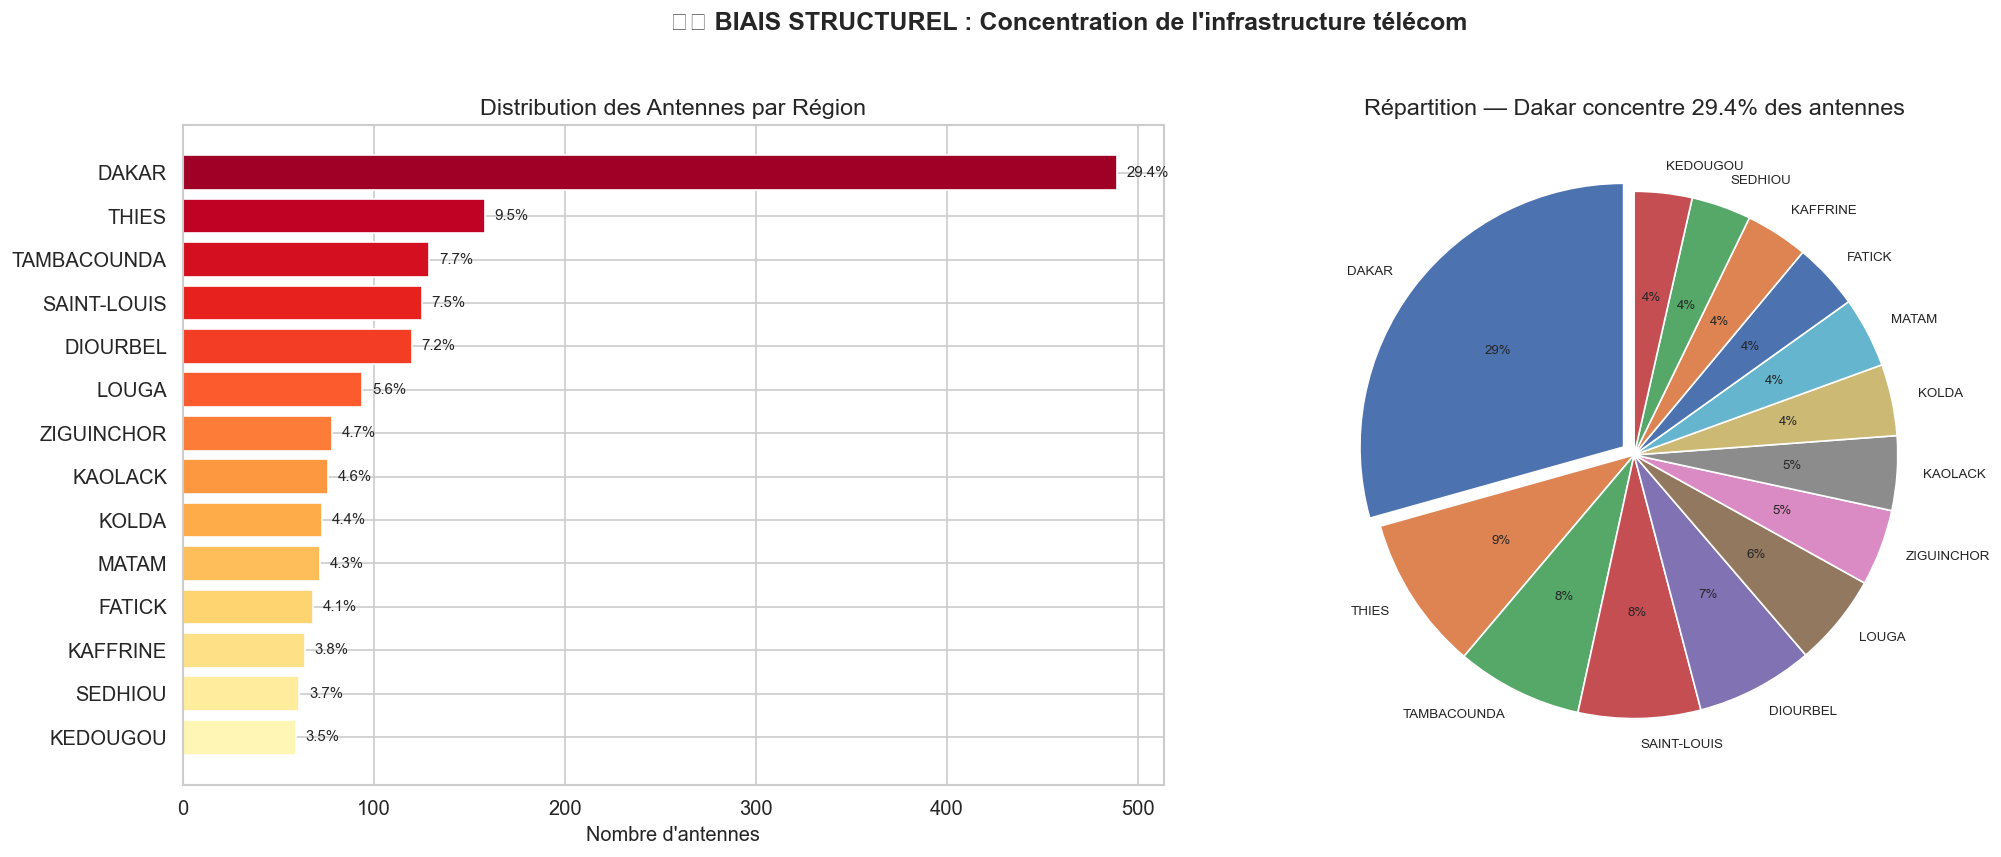


📋 Tableau récapitulatif :


,region,nb_antennes,pourcentage
0,DAKAR,489,29.4
1,THIES,158,9.5
2,TAMBACOUNDA,129,7.7
3,SAINT-LOUIS,125,7.5
4,DIOURBEL,120,7.2
5,LOUGA,94,5.6
6,ZIGUINCHOR,78,4.7
7,KAOLACK,76,4.6
8,KOLDA,73,4.4
9,MATAM,72,4.3


In [27]:
# ============================================================
# A.3 — Distribution des antennes par Région, Département, Arrondissement
#
# POURQUOI : Le nombre d'antennes dans une zone est un proxy de la 
# densité de population et de l'activité économique. Une zone avec 
# beaucoup d'antennes captera mécaniquement plus de trafic.
# Il est CRITIQUE de comprendre ce biais avant d'interpréter les flux.
# ============================================================
sites_per_region = df_sites.groupby('region')['site_id'].count().sort_values(ascending=False).reset_index()
sites_per_region.columns = ['region', 'nb_antennes']
sites_per_region['pourcentage'] = (sites_per_region['nb_antennes'] / sites_per_region['nb_antennes'].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Barplot
colors = sns.color_palette('YlOrRd_r', n_colors=len(sites_per_region))
ax1 = axes[0]
bars = ax1.barh(sites_per_region['region'], sites_per_region['nb_antennes'], color=colors)
ax1.set_xlabel('Nombre d\'antennes')
ax1.set_title('Distribution des Antennes par Région')
ax1.invert_yaxis()
for bar, pct in zip(bars, sites_per_region['pourcentage']):
    ax1.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, f'{pct}%', va='center', fontsize=9)

# Camembert
ax2 = axes[1]
dakar_pct = sites_per_region.loc[sites_per_region['region'] == 'DAKAR', 'pourcentage'].values[0]
explode = [0.05 if r == 'DAKAR' else 0 for r in sites_per_region['region']]
ax2.pie(sites_per_region['nb_antennes'], labels=sites_per_region['region'], 
        autopct='%1.0f%%', startangle=90, explode=explode, textprops={'fontsize': 8})
ax2.set_title(f'Répartition — Dakar concentre {dakar_pct}% des antennes')

plt.suptitle('⚠️ BIAIS STRUCTUREL : Concentration de l\'infrastructure télécom', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n📋 Tableau récapitulatif :')
display(sites_per_region)

Shapefile chargé : 123 polygones
Colonnes : ['arr_id', 'reg', 'dept', 'cav', 'arr', 'geometry']


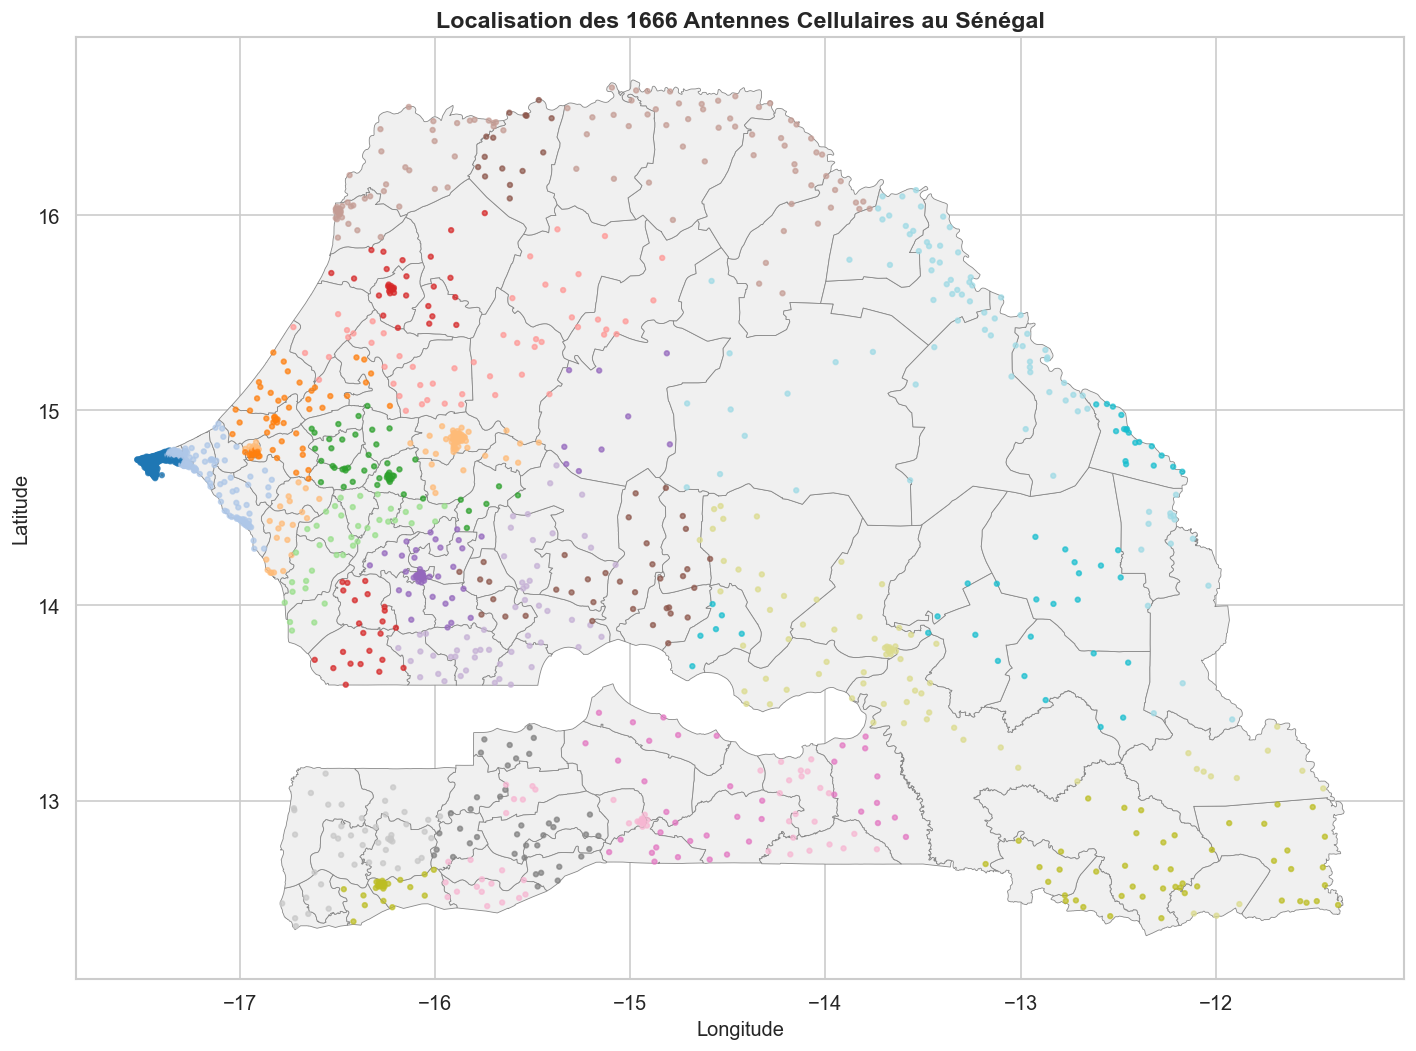

In [28]:
# ============================================================
# A.4 — Carte géographique des antennes (localisation GPS)
#
# POURQUOI : Visualiser la couverture spatiale réelle des antennes.
# Cela montre le maillage serré de Dakar vs la faible couverture
# des zones rurales (Kédougou, Tambacounda, Sédhiou).
# ============================================================
try:
    gdf_arr = gpd.read_file(CTX_DIR / 'Shapefile_Senegal_V2' / 'senegal_arr_2014_wgs.shp')
    has_shapefile = True
    print(f'Shapefile chargé : {len(gdf_arr)} polygones')
    print(f'Colonnes : {gdf_arr.columns.tolist()}')
except Exception as e:
    has_shapefile = False
    print(f'Shapefile non chargé ({e}). Carte basée sur les coordonnées GPS uniquement.')

fig, ax = plt.subplots(figsize=(12, 14))
if has_shapefile:
    gdf_arr.plot(ax=ax, color='#f0f0f0', edgecolor='#888888', linewidth=0.5)

scatter = ax.scatter(df_sites['lon'], df_sites['lat'], 
                     c=df_sites['arr_id'], cmap='tab20', s=8, alpha=0.7, zorder=5)
ax.set_title('Localisation des 1666 Antennes Cellulaires au Sénégal', fontsize=14, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

---
### B — Exploration du SET1 : Flux de Communication Antenne-à-Antenne

Le SET1 est le jeu de données principal. Il contient les **volumes horaires d'appels et de SMS** échangés entre chaque paire d'antennes (sites). C'est notre proxy le plus fort pour la mobilité, car une communication entre deux antennes éloignées traduit un lien humain (social ou économique) entre deux zones géographiques.

### Approche
Nous chargeons un échantillon représentatif (1 mois) pour l'exploration. Les patterns identifiés seront ensuite validés sur les 12 mois lors du prétraitement.

In [29]:
# ============================================================
# B.1 — Chargement d'un échantillon SET1 Voice (Mois de Janvier)
#
# ============================================================
site_to_arr = dict(zip(df_sites['site_id'], df_sites['arr_id']))
site_to_region = dict(zip(df_sites['site_id'], df_sites['region']))

# Chargement du SET1 Voice — Janvier 2013
voice_cols = ['timestamp', 'origin_site', 'dest_site', 'nb_calls', 'total_duration_sec']
print('Chargement de SET1V_01 (Voix Janvier 2013)...')
df_v = pd.read_csv(SET1_DIR / 'SET1V_01.CSV.gz', compression='gzip', 
                    header=None, names=voice_cols)
print(f'  → {len(df_v):,} lignes chargées')

# Enrichissement géographique
df_v['origin_arr'] = df_v['origin_site'].map(site_to_arr)
df_v['dest_arr'] = df_v['dest_site'].map(site_to_arr)
df_v['origin_region'] = df_v['origin_site'].map(site_to_region)
df_v['dest_region'] = df_v['dest_site'].map(site_to_region)
df_v['hour'] = df_v['timestamp'].str.slice(11, 13).astype(int)
df_v['date'] = df_v['timestamp'].str.slice(0, 10)
df_v['day_of_week'] = pd.to_datetime(df_v['date']).dt.dayofweek  # 0=Lundi, 6=Dimanche

# Suppression des lignes sans correspondance géographique
n_before = len(df_v)
df_v = df_v.dropna(subset=['origin_arr', 'dest_arr'])
print(f'  → {len(df_v):,} lignes après mapping géographique ({n_before - len(df_v)} lignes orphelines supprimées)')
print()
print('Aperçu des 5 premières lignes :')
display(df_v.head())

Chargement de SET1V_01 (Voix Janvier 2013)...
  → 105,818,106 lignes chargées
  → 105,818,106 lignes après mapping géographique (0 lignes orphelines supprimées)

Aperçu des 5 premières lignes :


,timestamp,origin_site,dest_site,nb_calls,total_duration_sec,origin_arr,dest_arr,origin_region,dest_region,hour,date,day_of_week
0,2013-01-01 00,1,1,1,54,2,2,DAKAR,DAKAR,0,2013-01-01,1
1,2013-01-01 00,1,2,1,39,2,2,DAKAR,DAKAR,0,2013-01-01,1
2,2013-01-01 00,1,24,1,2957,2,2,DAKAR,DAKAR,0,2013-01-01,1
3,2013-01-01 00,1,186,1,56,2,1,DAKAR,DAKAR,0,2013-01-01,1
4,2013-01-01 00,2,2,22,418,2,2,DAKAR,DAKAR,0,2013-01-01,1


In [30]:
# ============================================================
# B.2 — Chargement d'un échantillon SET1 SMS (Mois de Janvier)
# ============================================================
sms_cols = ['timestamp', 'origin_site', 'dest_site', 'nb_sms']
print('Chargement de SET1S_01 (SMS Janvier 2013)...')
df_s = pd.read_csv(SET1_DIR / 'SET1S_01.CSV.gz', compression='gzip',
                    header=None, names=sms_cols)
print(f'  → {len(df_s):,} lignes chargées')

df_s['origin_arr'] = df_s['origin_site'].map(site_to_arr)
df_s['dest_arr'] = df_s['dest_site'].map(site_to_arr)
df_s['origin_region'] = df_s['origin_site'].map(site_to_region)
df_s['dest_region'] = df_s['dest_site'].map(site_to_region)
df_s['hour'] = df_s['timestamp'].str.slice(11, 13).astype(int)
df_s['date'] = df_s['timestamp'].str.slice(0, 10)

n_before = len(df_s)
df_s = df_s.dropna(subset=['origin_arr', 'dest_arr'])
print(f'  → {len(df_s):,} lignes après mapping ({n_before - len(df_s)} orphelines)')
display(df_s.head())

Chargement de SET1S_01 (SMS Janvier 2013)...
  → 50,230,476 lignes chargées
  → 50,230,476 lignes après mapping (0 orphelines)


,timestamp,origin_site,dest_site,nb_sms,origin_arr,dest_arr,origin_region,dest_region,hour,date
0,2013-01-01 00,1,61,1,2,4,DAKAR,DAKAR,0,2013-01-01
1,2013-01-01 00,1,340,1,2,6,DAKAR,DAKAR,0,2013-01-01
2,2013-01-01 00,1,419,1,2,7,DAKAR,DAKAR,0,2013-01-01
3,2013-01-01 00,1,420,1,2,8,DAKAR,DAKAR,0,2013-01-01
4,2013-01-01 00,1,447,2,2,10,DAKAR,DAKAR,0,2013-01-01


In [31]:
# ============================================================
# B.3 — Statistiques Descriptives des Variables SET1
#
# POURQUOI : Comprendre les ordres de grandeur, détecter les
# valeurs aberrantes (ex: durée d'appel > 24h impossible),
# les zéros, les distributions asymétriques.
# ============================================================
print('=== STATISTIQUES DESCRIPTIVES — SET1 VOICE (Janvier 2013) ===')
print()
stats_v = df_v[['nb_calls', 'total_duration_sec']].describe().round(2)
stats_v.loc['total'] = df_v[['nb_calls', 'total_duration_sec']].sum()
display(stats_v)

print(f"\nNombre de paires site-à-site uniques (Voix) : {df_v.groupby(['origin_site', 'dest_site']).ngroups:,}")
print(f"Nombre de paires arrondissement-à-arrondissement uniques : {df_v.groupby(['origin_arr', 'dest_arr']).ngroups:,}")
print(f"Nombre de jours couverts : {df_v['date'].nunique()}")
print()

print('=== STATISTIQUES DESCRIPTIVES — SET1 SMS (Janvier 2013) ===')
print()
stats_s = df_s[['nb_sms']].describe().round(2)
stats_s.loc['total'] = df_s[['nb_sms']].sum()
display(stats_s)
print(f"\nNombre de paires site-à-site uniques (SMS) : {df_s.groupby(['origin_site', 'dest_site']).ngroups:,}")

=== STATISTIQUES DESCRIPTIVES — SET1 VOICE (Janvier 2013) ===



,nb_calls,total_duration_sec
count,1.058181e+08,1.058181e+08
mean,2.820000e+00,1.746800e+02
std,1.175000e+01,4.923200e+02
min,1.000000e+00,1.000000e+00
25%,1.000000e+00,3.400000e+01
50%,1.000000e+00,7.600000e+01
75%,2.000000e+00,1.680000e+02
max,1.093700e+04,3.543610e+05
total,2.979650e+08,1.848473e+10



Nombre de paires site-à-site uniques (Voix) : 1,902,496
Nombre de paires arrondissement-à-arrondissement uniques : 15,052
Nombre de jours couverts : 31

=== STATISTIQUES DESCRIPTIVES — SET1 SMS (Janvier 2013) ===



,nb_sms
count,5.023048e+07
mean,5.290000e+00
std,2.167000e+01
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,4.000000e+00
max,2.865500e+04
total,2.655638e+08



Nombre de paires site-à-site uniques (SMS) : 1,365,414


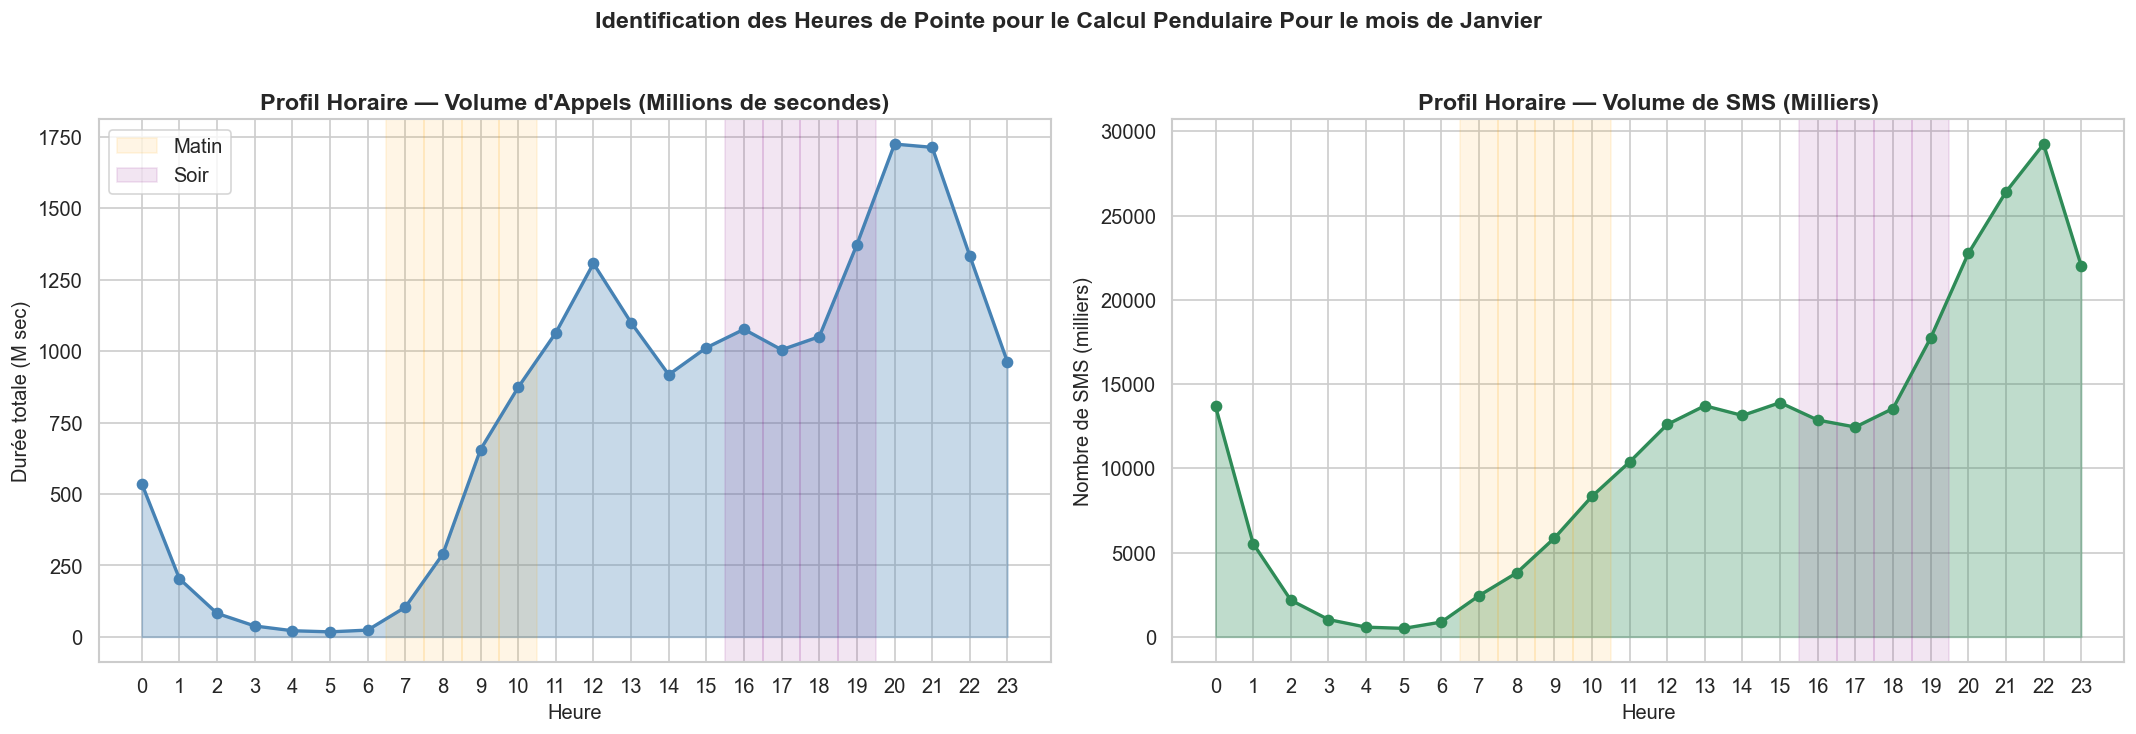


📌 Observation : Les pics visibles permettent de fixer les plages pendulaires.
   → Matin (aller travail)  : 07h-10h
   → Soir  (retour domicile): 16h-19h


In [32]:
# ============================================================
# B.5 — Profil Horaire Moyen des Communications Pour le Mois de Janvier
#
# ============================================================
hourly_voice = df_v.groupby('hour').agg(
    total_calls=('nb_calls', 'sum'),
    total_duration=('total_duration_sec', 'sum'),
    nb_records=('nb_calls', 'count')
).reset_index()

hourly_sms = df_s.groupby('hour').agg(
    total_sms=('nb_sms', 'sum'),
    nb_records=('nb_sms', 'count')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Voix
ax = axes[0]
ax.fill_between(hourly_voice['hour'], hourly_voice['total_duration'] / 1e6, alpha=0.3, color='steelblue')
ax.plot(hourly_voice['hour'], hourly_voice['total_duration'] / 1e6, 'o-', color='steelblue', linewidth=2)
# Mise en évidence des heures de pointe
for h in [7, 8, 9, 10]:
    ax.axvspan(h-0.5, h+0.5, alpha=0.1, color='orange', label='Matin' if h == 7 else '')
for h in [16, 17, 18, 19]:
    ax.axvspan(h-0.5, h+0.5, alpha=0.1, color='purple', label='Soir' if h == 16 else '')
ax.set_title('Profil Horaire — Volume d\'Appels (Millions de secondes)', fontweight='bold')
ax.set_xlabel('Heure')
ax.set_ylabel('Durée totale (M sec)')
ax.set_xticks(range(24))
ax.legend()

# SMS
ax = axes[1]
ax.fill_between(hourly_sms['hour'], hourly_sms['total_sms'] / 1e3, alpha=0.3, color='seagreen')
ax.plot(hourly_sms['hour'], hourly_sms['total_sms'] / 1e3, 'o-', color='seagreen', linewidth=2)
for h in [7, 8, 9, 10]:
    ax.axvspan(h-0.5, h+0.5, alpha=0.1, color='orange')
for h in [16, 17, 18, 19]:
    ax.axvspan(h-0.5, h+0.5, alpha=0.1, color='purple')
ax.set_title('Profil Horaire — Volume de SMS (Milliers)', fontweight='bold')
ax.set_xlabel('Heure')
ax.set_ylabel('Nombre de SMS (milliers)')
ax.set_xticks(range(24))

plt.suptitle('Identification des Heures de Pointe pour le Calcul Pendulaire Pour le mois de Janvier',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n📌 Observation : Les pics visibles permettent de fixer les plages pendulaires.')
print('   → Matin (aller travail)  : 07h-10h')
print('   → Soir  (retour domicile): 16h-19h')

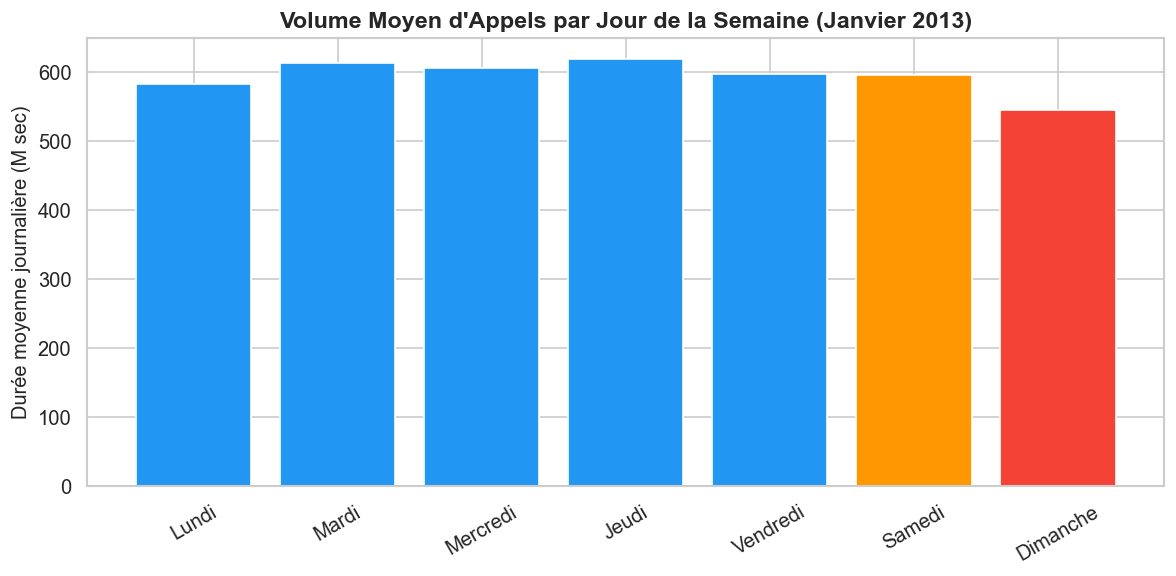

In [33]:
# ============================================================
# B.6 — Profil Journalier (Lundi→Dimanche)
#
# POURQUOI : Vérifier si le week-end a un pattern différent
# de la semaine (moins de trafic pendulaire mais plus de trafic
# social/religieux, notamment le vendredi = jour de prière).
# ============================================================
daily_voice = df_v.groupby(['date', 'day_of_week']).agg(
    total_duration=('total_duration_sec', 'sum'),
    total_calls=('nb_calls', 'sum')
).reset_index()

days_labels = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
dow_agg = daily_voice.groupby('day_of_week')['total_duration'].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
colors_dow = ['#2196F3']*5 + ['#FF9800', '#F44336']  # Bleu semaine, Orange samedi, Rouge dimanche
ax.bar(dow_agg['day_of_week'], dow_agg['total_duration'] / 1e6, color=colors_dow)
ax.set_xticks(range(7))
ax.set_xticklabels(days_labels, rotation=30)
ax.set_title('Volume Moyen d\'Appels par Jour de la Semaine (Janvier 2013)', fontweight='bold')
ax.set_ylabel('Durée moyenne journalière (M sec)')
plt.tight_layout()
plt.show()

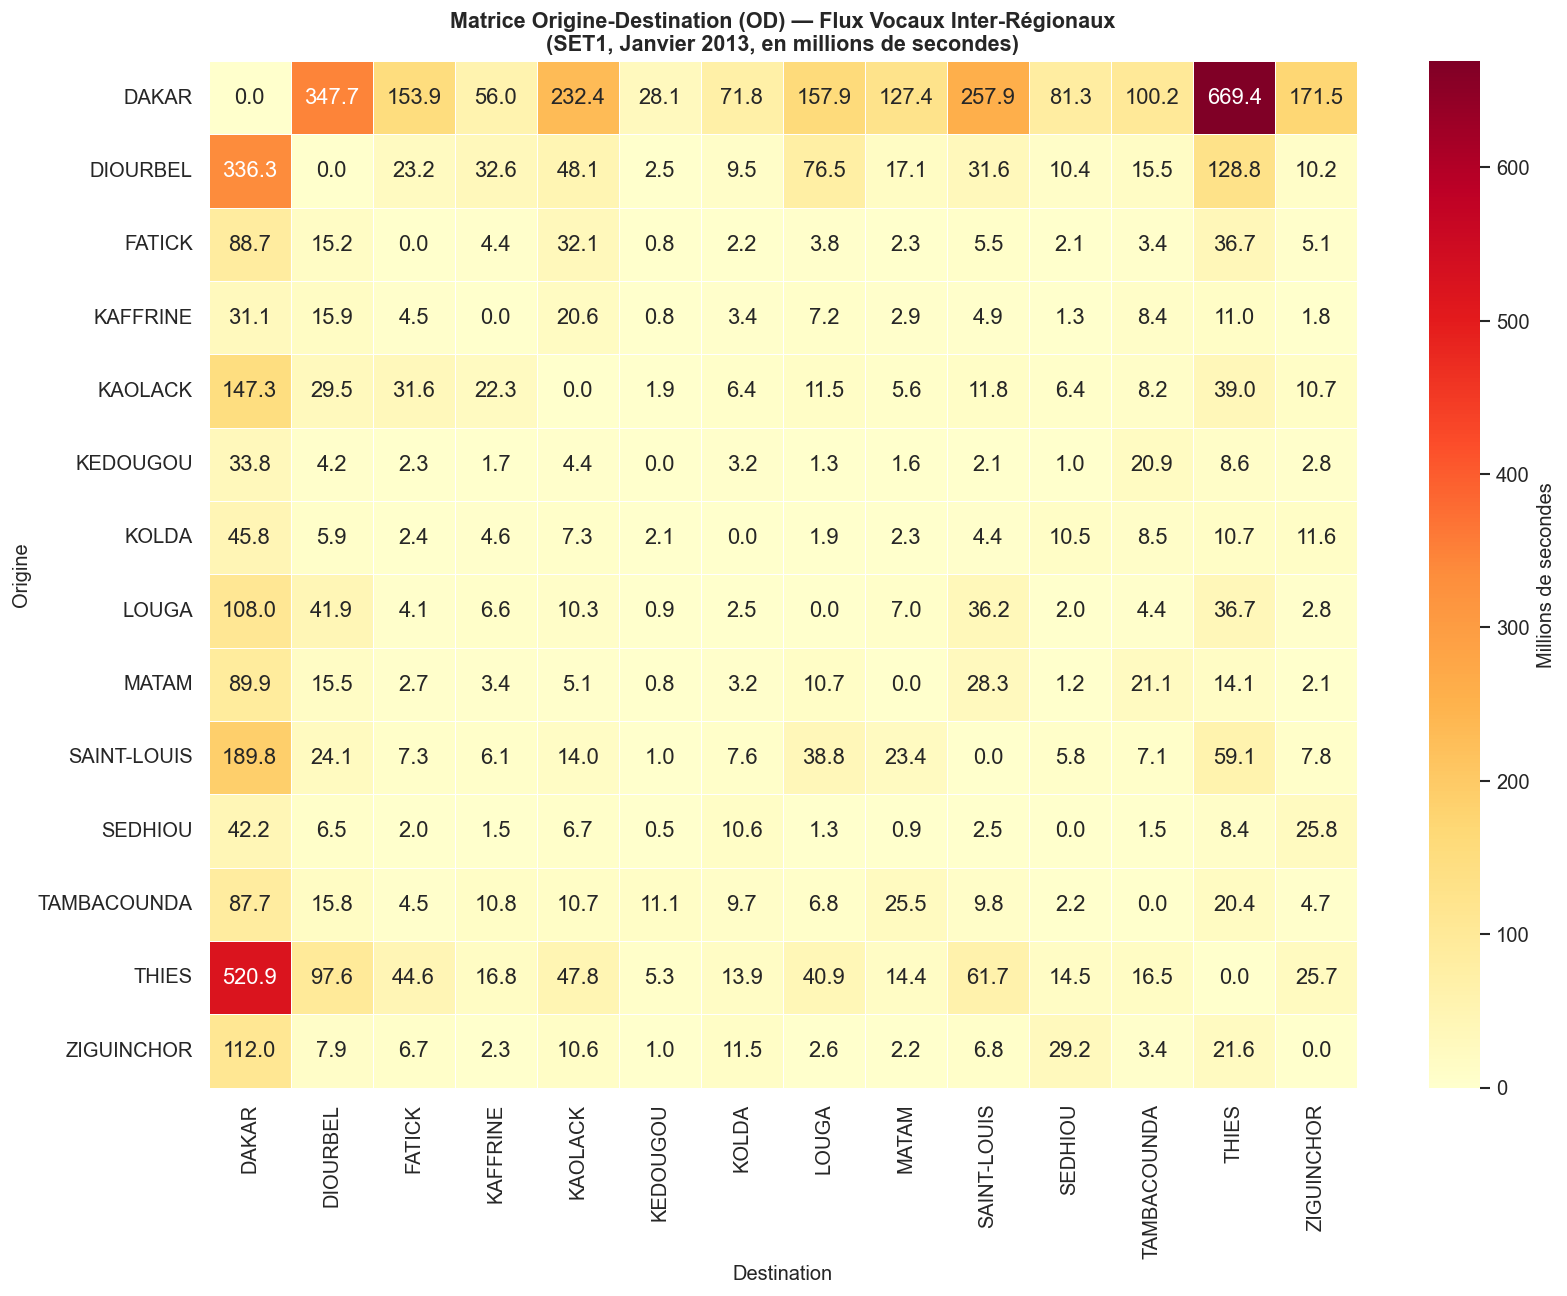


📌 Lecture : La valeur en cellule (i,j) indique le volume total de communication
   émis depuis la région i vers la région j pendant tout le mois de Janvier 2013.


In [34]:
# ============================================================
# B.7 — Matrice Origine-Destination (OD) du SET1 — Agrégation Régionale
#
# POURQUOI : La matrice OD est LA représentation fondamentale
# des flux de mobilité. Elle montre d'où viennent les communications
# et où elles vont. Au niveau régional, elle révèle les corridors
# inter-régionaux les plus chargés.
# ============================================================

# Agrégation : flux INTER-RÉGIONAUX uniquement
df_v_inter = df_v[df_v['origin_region'] != df_v['dest_region']].copy()

od_region_voice = df_v_inter.groupby(['origin_region', 'dest_region'])['total_duration_sec'].sum().reset_index()
od_pivot_voice = od_region_voice.pivot_table(index='origin_region', columns='dest_region', 
                                              values='total_duration_sec', fill_value=0)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(od_pivot_voice / 1e6, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Millions de secondes'})
ax.set_title('Matrice Origine-Destination (OD) — Flux Vocaux Inter-Régionaux\n(SET1, Janvier 2013, en millions de secondes)', 
             fontsize=13, fontweight='bold')
ax.set_xlabel('Destination')
ax.set_ylabel('Origine')
plt.tight_layout()
plt.show()

print('\n📌 Lecture : La valeur en cellule (i,j) indique le volume total de communication')
print('   émis depuis la région i vers la région j pendant tout le mois de Janvier 2013.')

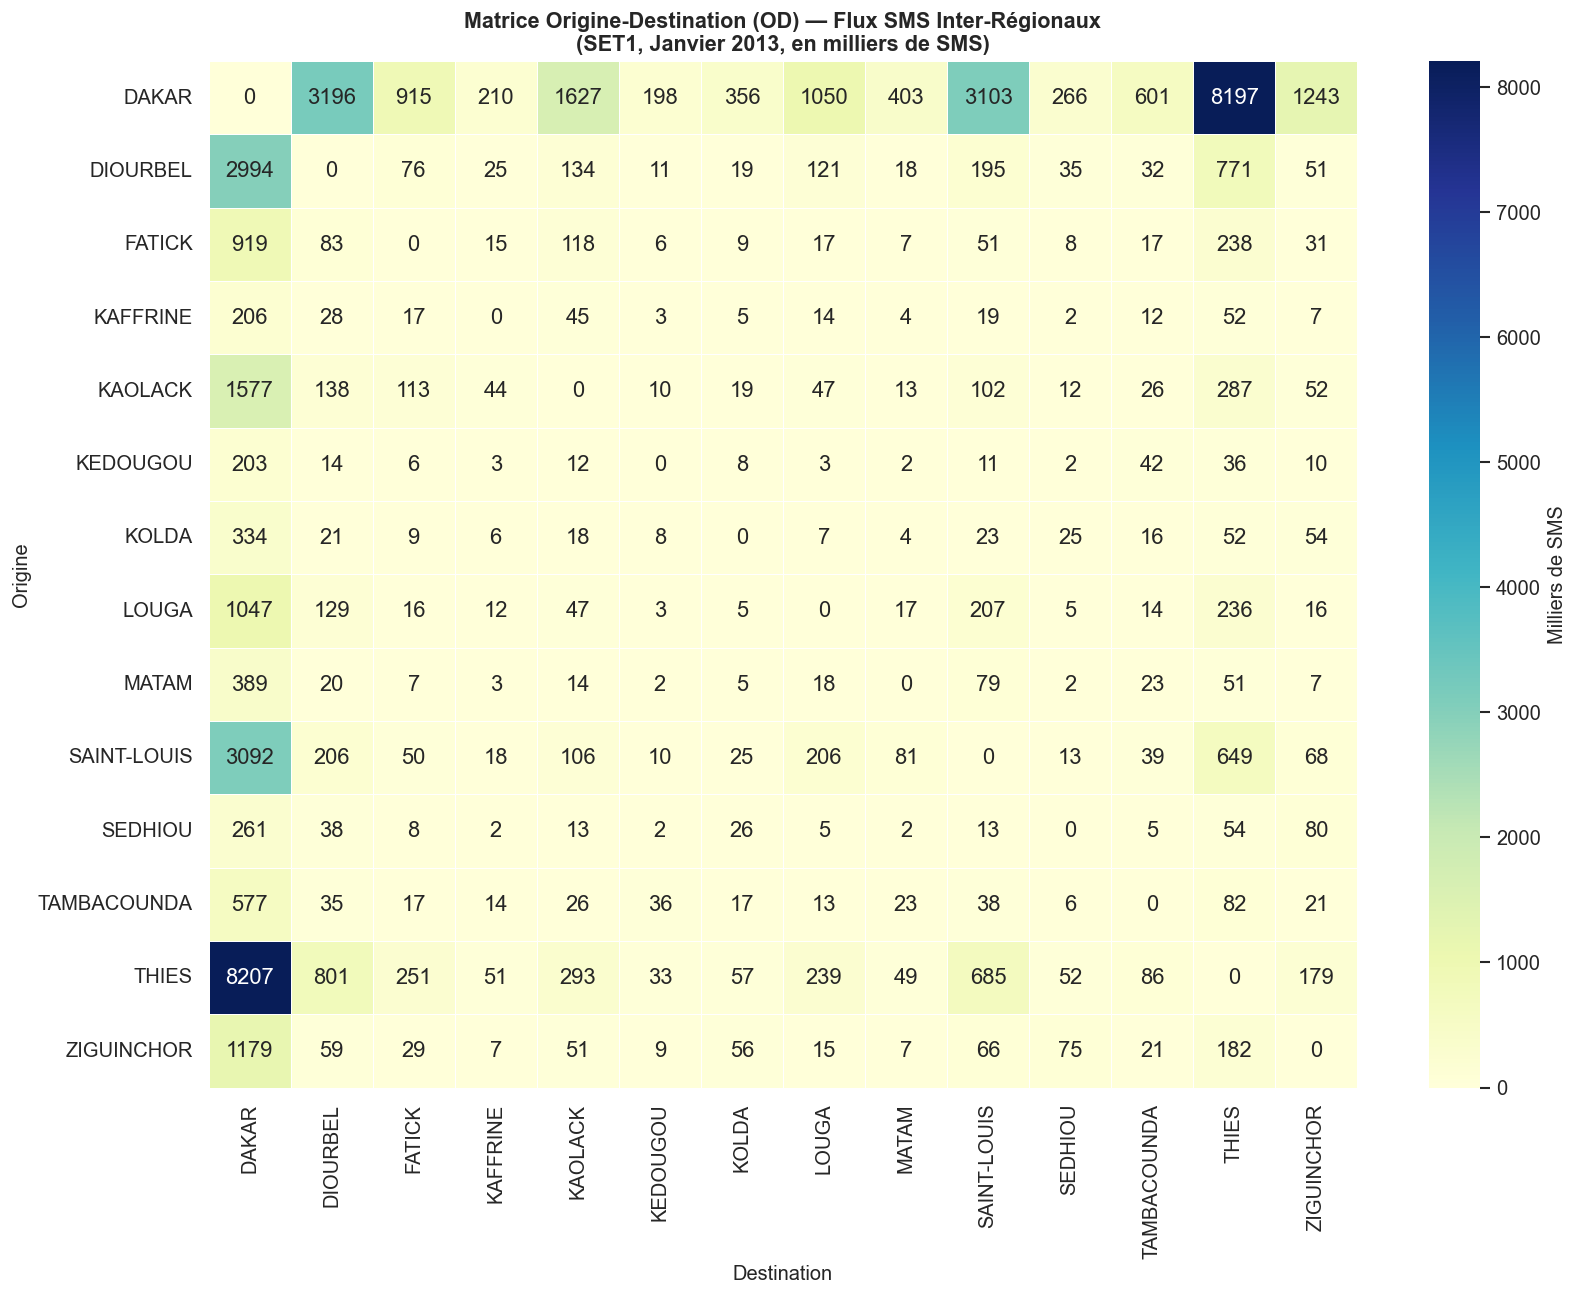

In [35]:
# ============================================================
# B.8 — Matrice OD SET1 SMS (Régionale)
# ============================================================
df_s_inter = df_s[df_s['origin_region'] != df_s['dest_region']].copy()

od_region_sms = df_s_inter.groupby(['origin_region', 'dest_region'])['nb_sms'].sum().reset_index()
od_pivot_sms = od_region_sms.pivot_table(index='origin_region', columns='dest_region',
                                          values='nb_sms', fill_value=0)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(od_pivot_sms / 1e3, annot=True, fmt='.0f', cmap='YlGnBu', ax=ax,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Milliers de SMS'})
ax.set_title('Matrice Origine-Destination (OD) — Flux SMS Inter-Régionaux\n(SET1, Janvier 2013, en milliers de SMS)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Destination')
ax.set_ylabel('Origine')
plt.tight_layout()
plt.show()

📊 CLASSEMENT DES RÉGIONS PAR VOLUME DE TRAFIC (Janvier 2013)


,outgoing_sec,incoming_sec,total_sec,part_nationale_%,cumul_%,total_sms
region,,,,,,
DAKAR,"10,046,897,875","9,424,819,768","19,471,717,643",52.7,52.7,"396,314,446"
THIES,"2,075,162,858","2,219,067,586","4,294,230,444",11.6,64.3,"51,927,551"
DIOURBEL,"1,300,232,812","1,185,502,114","2,485,734,926",6.7,71.0,"14,698,361"
SAINT-LOUIS,"1,026,767,532","1,098,438,136","2,125,205,668",5.7,76.7,"25,355,637"
KAOLACK,"703,762,734","821,656,948","1,525,419,682",4.1,80.8,"9,085,384"
ZIGUINCHOR,"579,459,624","644,278,885","1,223,738,509",3.3,84.1,"8,877,919"
LOUGA,"507,937,283","605,750,386","1,113,687,669",3.0,87.1,"6,307,297"
MATAM,"494,406,236","529,016,797","1,023,423,033",2.8,89.9,"2,841,595"
TAMBACOUNDA,"489,558,810","488,987,952","978,546,762",2.6,92.5,"3,653,329"


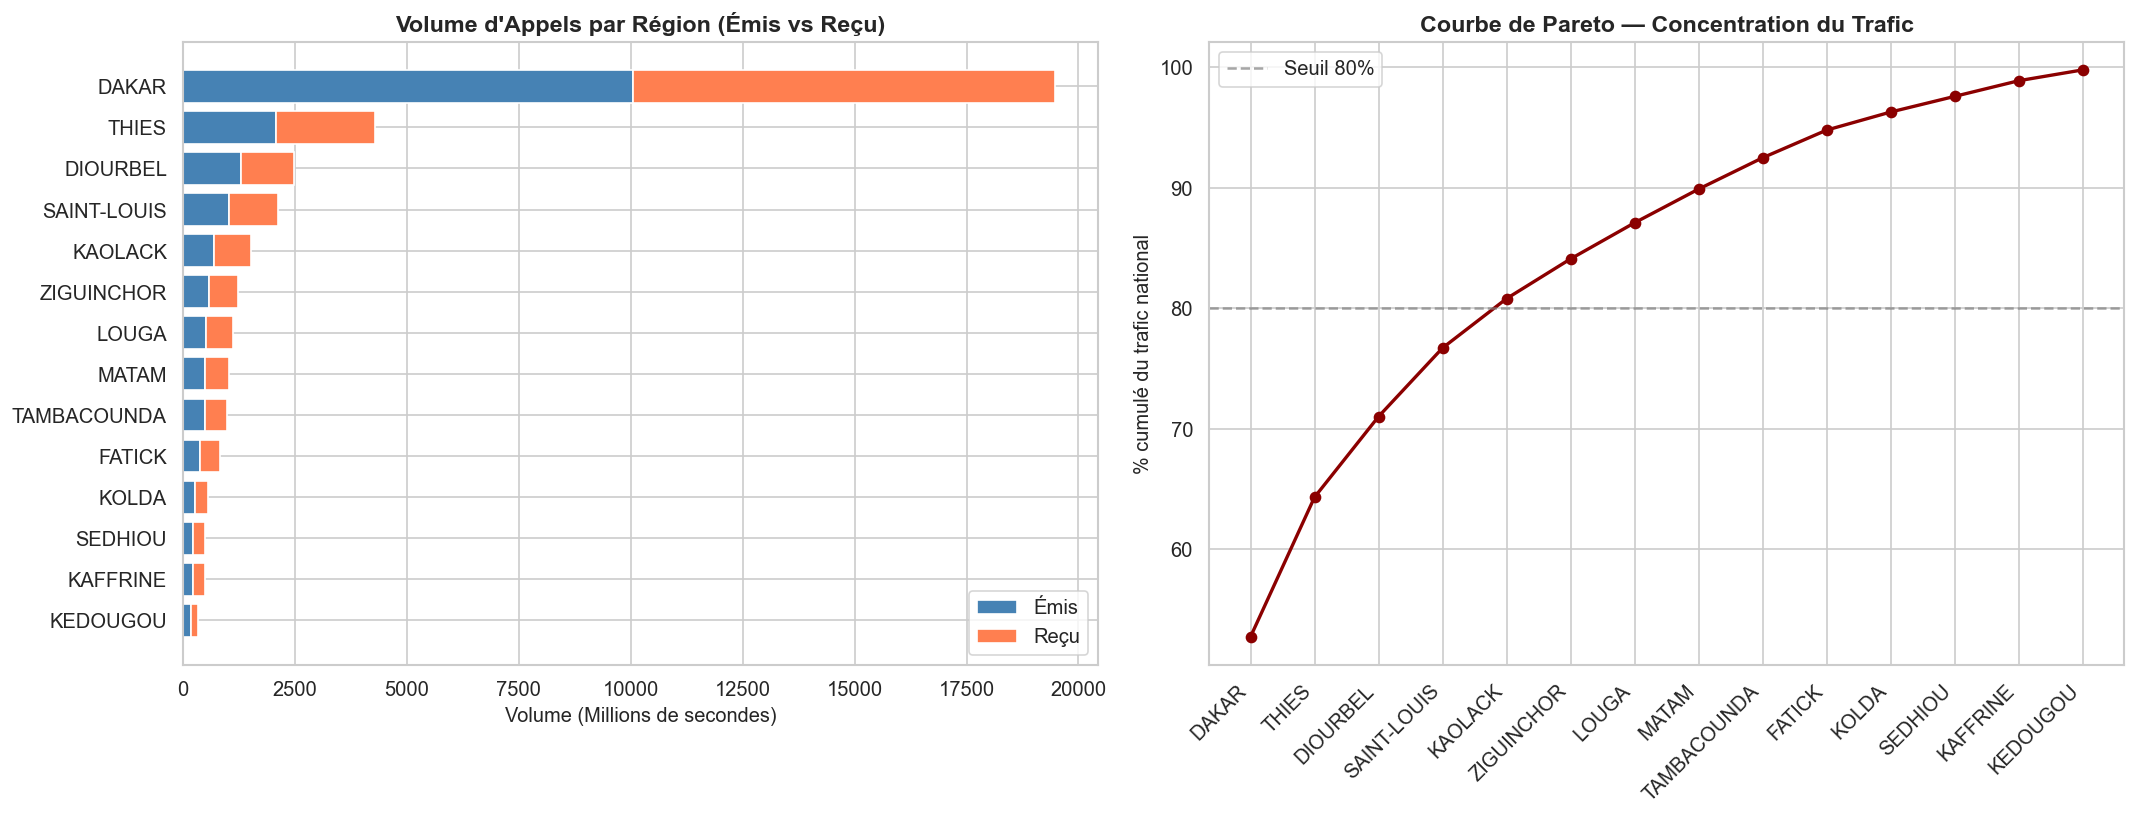


📌 Règle de Pareto : 6 régions concentrent ~80% du trafic national :
   → ['DAKAR', 'THIES', 'DIOURBEL', 'SAINT-LOUIS', 'KAOLACK', 'ZIGUINCHOR']


In [36]:
# ============================================================
# B.9 — Classement des Régions par Volume de Trafic
#
#Identifions les régions qui génèrent et attirent le
# plus de trafic. C'est le premier critère pour définir une « zone
# critique ». On distingue les flux émis (outgoing) et reçus (incoming).
# ============================================================

# Voix — par région (tout trafic, intra + inter)
out_voice = df_v.groupby('origin_region')['total_duration_sec'].sum().rename('outgoing_sec')
in_voice  = df_v.groupby('dest_region')['total_duration_sec'].sum().rename('incoming_sec')
region_voice = pd.concat([out_voice, in_voice], axis=1).fillna(0)
region_voice['total_sec'] = region_voice['outgoing_sec'] + region_voice['incoming_sec']
region_voice = region_voice.sort_values('total_sec', ascending=False)
region_voice['part_nationale_%'] = (region_voice['total_sec'] / region_voice['total_sec'].sum() * 100).round(1)
region_voice['cumul_%'] = region_voice['part_nationale_%'].cumsum()

# SMS — par région
out_sms = df_s.groupby('origin_region')['nb_sms'].sum().rename('outgoing_sms')
in_sms  = df_s.groupby('dest_region')['nb_sms'].sum().rename('incoming_sms')
region_sms = pd.concat([out_sms, in_sms], axis=1).fillna(0)
region_sms['total_sms'] = region_sms['outgoing_sms'] + region_sms['incoming_sms']
region_sms = region_sms.sort_values('total_sms', ascending=False)

# Fusion
region_ranking = region_voice.join(region_sms[['total_sms']])
region_ranking.index.name = 'region'

print('📊 CLASSEMENT DES RÉGIONS PAR VOLUME DE TRAFIC (Janvier 2013)')
print('=' * 80)
display(region_ranking.style.format({
    'outgoing_sec': '{:,.0f}',
    'incoming_sec': '{:,.0f}',
    'total_sec': '{:,.0f}',
    'total_sms': '{:,.0f}',
    'part_nationale_%': '{:.1f}',
    'cumul_%': '{:.1f}'
}).background_gradient(cmap='YlOrRd', subset=['total_sec', 'part_nationale_%']))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ax = axes[0]
ax.barh(region_ranking.index, region_ranking['outgoing_sec'] / 1e6, color='steelblue', label='Émis')
ax.barh(region_ranking.index, region_ranking['incoming_sec'] / 1e6, left=region_ranking['outgoing_sec'] / 1e6,
        color='coral', label='Reçu')
ax.set_xlabel('Volume (Millions de secondes)')
ax.set_title('Volume d\'Appels par Région (Émis vs Reçu)', fontweight='bold')
ax.legend()
ax.invert_yaxis()

ax = axes[1]
ax.plot(range(len(region_ranking)), region_ranking['cumul_%'].values, 'o-', color='darkred', linewidth=2)
ax.axhline(y=80, color='gray', linestyle='--', alpha=0.7, label='Seuil 80%')
ax.set_xticks(range(len(region_ranking)))
ax.set_xticklabels(region_ranking.index, rotation=45, ha='right')
ax.set_ylabel('% cumulé du trafic national')
ax.set_title('Courbe de Pareto — Concentration du Trafic', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.show()

# Identifier les régions couvrant 80% du trafic
pareto_regions = region_ranking[region_ranking['cumul_%'] <= 85].index.tolist()
print(f'\n📌 Règle de Pareto : {len(pareto_regions)} régions concentrent ~80% du trafic national :')
print(f'   → {pareto_regions}')

📊 TOP 25 DES ARRONDISSEMENTS PAR VOLUME DE TRAFIC (Appels + SMS)


,region,department,arrondissement,total_sec,total_sms,nb_antennes,part_nationale_%,cumul_%
4,DAKAR,DAKAR,DAKAR PLATEAU,3418851690,76380962,74,9.25,9.25
1,DAKAR,DAKAR,PARCELLES ASSAINIES,3211142165,73966768,68,8.69,17.94
3,DAKAR,DAKAR,GRAND DAKAR,3200959568,76609770,73,8.66,26.60
2,DAKAR,DAKAR,ALMADIES,2531272750,67427621,74,6.85,33.45
25,DIOURBEL,MBACKE,NDAME,1903364836,10172105,65,5.15,38.60
5,DAKAR,GUEDIAWAYE,GUEDIAWAYE,1513104957,29270302,44,4.09,42.69
7,DAKAR,PIKINE,THIAROYE,1457131505,21007185,39,3.94,46.63
12,THIES,MBOUR,SINDIA,1435471054,15665838,39,3.88,50.51
6,DAKAR,PIKINE,PIKINE DAGOUDANE,1428624458,16676480,30,3.86,54.37
8,DAKAR,PIKINE,NIAYES,1213765327,15715426,32,3.28,57.65


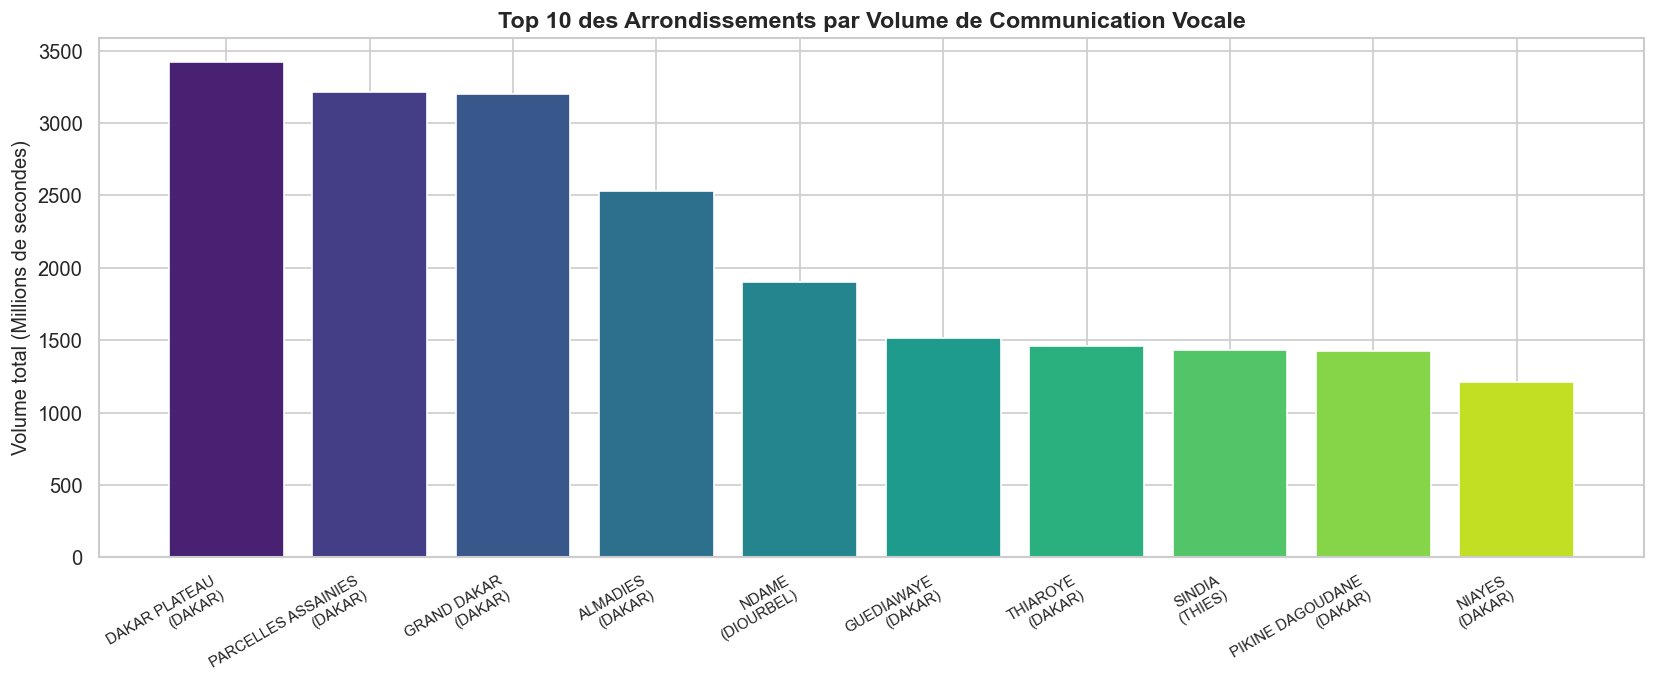

In [37]:
# ============================================================
# B.10 — Classement des Arrondissements par Volume
#        (Détail à l'intérieur de chaque région)
#
# Ici nous Mesurer l'apport de chaque arrondissement au trafic
# de sa région. Certains arrondissements (ex: Dakar Plateau)
# génèrent la quasi-totalité du trafic de leur région.
# ============================================================
arr_to_meta = dict(zip(df_arr['arr_id'], df_arr.to_dict('records')))

out_arr = df_v.groupby('origin_arr')['total_duration_sec'].sum().rename('outgoing_sec')
in_arr  = df_v.groupby('dest_arr')['total_duration_sec'].sum().rename('incoming_sec')
arr_ranking = pd.concat([out_arr, in_arr], axis=1).fillna(0)
arr_ranking['total_sec'] = arr_ranking['outgoing_sec'] + arr_ranking['incoming_sec']

# SMS
out_arr_sms = df_s.groupby('origin_arr')['nb_sms'].sum().rename('outgoing_sms')
in_arr_sms  = df_s.groupby('dest_arr')['nb_sms'].sum().rename('incoming_sms')
arr_ranking_sms = pd.concat([out_arr_sms, in_arr_sms], axis=1).fillna(0)
arr_ranking_sms['total_sms'] = arr_ranking_sms['outgoing_sms'] + arr_ranking_sms['incoming_sms']

arr_ranking = arr_ranking.join(arr_ranking_sms[['total_sms']])
arr_ranking.index = arr_ranking.index.astype(int)

# Enrichissement
arr_ranking['region'] = arr_ranking.index.map(lambda x: arr_to_meta.get(x, {}).get('region', 'UNKNOWN'))
arr_ranking['department'] = arr_ranking.index.map(lambda x: arr_to_meta.get(x, {}).get('department', 'UNKNOWN'))
arr_ranking['arrondissement'] = arr_ranking.index.map(lambda x: arr_to_meta.get(x, {}).get('arrondissement', 'UNKNOWN'))
arr_ranking = arr_ranking.sort_values('total_sec', ascending=False)
arr_ranking['part_nationale_%'] = (arr_ranking['total_sec'] / arr_ranking['total_sec'].sum() * 100).round(2)
arr_ranking['cumul_%'] = arr_ranking['part_nationale_%'].cumsum().round(2)

# Nb antennes par arrondissement
sites_per_arr = df_sites.groupby('arr_id')['site_id'].count().rename('nb_antennes')
arr_ranking = arr_ranking.join(sites_per_arr)

print('📊 TOP 25 DES ARRONDISSEMENTS PAR VOLUME DE TRAFIC (Appels + SMS)')
print('=' * 100)
display(arr_ranking[['region', 'department', 'arrondissement', 'total_sec', 'total_sms', 'nb_antennes', 'part_nationale_%', 'cumul_%']].head(25))

# Top 10 visualisation
top10 = arr_ranking.head(10)
fig, ax = plt.subplots(figsize=(14, 6))
labels = top10['arrondissement'] + '\n(' + top10['region'] + ')'
ax.bar(range(len(top10)), top10['total_sec'] / 1e6, color=sns.color_palette('viridis', 10))
ax.set_xticks(range(len(top10)))
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Volume total (Millions de secondes)')
ax.set_title('Top 10 des Arrondissements par Volume de Communication Vocale', fontweight='bold')
plt.tight_layout()
plt.show()

---
### C — Exploration du SET3 : Mobilité Physique par Arrondissement

Le SET3 contient les **trajectoires réelles des utilisateurs** : à chaque instant, on sait dans quel arrondissement se trouve un utilisateur donné. C'est le proxy le plus direct du **déplacement physique**, contrairement au SET1 qui mesure la communication.

### Approche
On charge un mois, on détecte les transitions (quand un utilisateur change d'arrondissement), et on construit la matrice OD physique.

In [38]:
# ============================================================
# C.1 — Chargement SET3 (Janvier 2013)
# ============================================================
set3_cols = ['userid', 'timestamp', 'arr_id']
print('Chargement de SET3_M01 (Trajectoires Janvier 2013)...')
df_t3 = pd.read_csv(SET3_DIR / 'SET3_M01.CSV.gz', compression='gzip',
                     header=None, names=set3_cols)
print(f'  → {len(df_t3):,} lignes chargées')
print(f'  → {df_t3["userid"].nunique():,} utilisateurs uniques')
print(f'  → {df_t3["arr_id"].nunique()} arrondissements visités')

df_t3['timestamp'] = pd.to_datetime(df_t3['timestamp'])
df_t3['date'] = df_t3['timestamp'].dt.date
df_t3['hour'] = df_t3['timestamp'].dt.hour
df_t3['day_of_week'] = df_t3['timestamp'].dt.dayofweek

# Enrichissement géographique
df_t3 = df_t3.merge(df_arr, on='arr_id', how='left')

display(df_t3.head(10))

Chargement de SET3_M01 (Trajectoires Janvier 2013)...
  → 43,034,439 lignes chargées
  → 146,352 utilisateurs uniques
  → 123 arrondissements visités


,userid,timestamp,arr_id,date,hour,day_of_week,region,department,arrondissement
0,37509,2013-01-29 15:00:00,3,2013-01-29,15,1,DAKAR,DAKAR,GRAND DAKAR
1,84009,2013-01-14 07:00:00,3,2013-01-14,7,0,DAKAR,DAKAR,GRAND DAKAR
2,84009,2013-01-14 07:00:00,3,2013-01-14,7,0,DAKAR,DAKAR,GRAND DAKAR
3,84009,2013-01-14 07:00:00,3,2013-01-14,7,0,DAKAR,DAKAR,GRAND DAKAR
4,80150,2013-01-27 16:50:00,3,2013-01-27,16,6,DAKAR,DAKAR,GRAND DAKAR
5,122080,2013-01-25 12:20:00,3,2013-01-25,12,4,DAKAR,DAKAR,GRAND DAKAR
6,67258,2013-01-08 10:50:00,3,2013-01-08,10,1,DAKAR,DAKAR,GRAND DAKAR
7,67258,2013-01-08 10:50:00,3,2013-01-08,10,1,DAKAR,DAKAR,GRAND DAKAR
8,67258,2013-01-08 11:00:00,3,2013-01-08,11,1,DAKAR,DAKAR,GRAND DAKAR
9,135892,2013-01-08 15:40:00,3,2013-01-08,15,1,DAKAR,DAKAR,GRAND DAKAR


In [39]:
# ============================================================
# C.2 — Détection des Transitions (Déplacements Physiques)
#
# Un enregistrement dans SET3 est un signal: « l'utilisateur X est
# dans l'arrondissement Y à l'instant T ». Si l'enregistrement
# suivant du même utilisateur est dans un arrondissement Z ≠ Y,
# alors il s'est DÉPLACÉ de Y vers Z. C'est un déplacement réel.
# ============================================================
print('Détection des transitions physiques (changements d\'arrondissement)...')
df_t3_sorted = df_t3.sort_values(['userid', 'timestamp'])
df_t3_sorted['prev_arr'] = df_t3_sorted.groupby('userid')['arr_id'].shift(1)
df_t3_sorted['prev_region'] = df_t3_sorted.groupby('userid')['region'].shift(1)

# Transitions = quand l'arrondissement change
transitions = df_t3_sorted[
    (df_t3_sorted['arr_id'] != df_t3_sorted['prev_arr']) &
    df_t3_sorted['prev_arr'].notna()
].copy()
transitions['prev_arr'] = transitions['prev_arr'].astype(int)

print(f'  → {len(transitions):,} transitions détectées')
print(f'  → {transitions["userid"].nunique():,} utilisateurs ayant bougé')

# Enrichir avec les noms de l'arrondissement d'origine
transitions = transitions.merge(df_arr.rename(columns={
    'arr_id': 'prev_arr', 'region': 'origin_region', 
    'department': 'origin_department', 'arrondissement': 'origin_arrondissement'
}), on='prev_arr', how='left')

transitions.rename(columns={'region': 'dest_region', 'department': 'dest_department', 
                             'arrondissement': 'dest_arrondissement'}, inplace=True)

print('\nAperçu des transitions détectées :')
display(transitions[['userid', 'timestamp', 'prev_arr', 'origin_arrondissement', 'origin_region',
                      'arr_id', 'dest_arrondissement', 'dest_region']].head(10))

Détection des transitions physiques (changements d'arrondissement)...
  → 3,873,851 transitions détectées
  → 124,427 utilisateurs ayant bougé

Aperçu des transitions détectées :


,userid,timestamp,prev_arr,origin_arrondissement,origin_region,arr_id,dest_arrondissement,dest_region
0,1,2013-01-01 12:30:00,4,DAKAR PLATEAU,DAKAR,1,PARCELLES ASSAINIES,DAKAR
1,1,2013-01-02 16:30:00,1,PARCELLES ASSAINIES,DAKAR,4,DAKAR PLATEAU,DAKAR
2,1,2013-01-03 17:30:00,4,DAKAR PLATEAU,DAKAR,1,PARCELLES ASSAINIES,DAKAR
3,1,2013-01-04 12:20:00,1,PARCELLES ASSAINIES,DAKAR,4,DAKAR PLATEAU,DAKAR
4,1,2013-01-05 12:20:00,4,DAKAR PLATEAU,DAKAR,1,PARCELLES ASSAINIES,DAKAR
5,1,2013-01-08 08:30:00,1,PARCELLES ASSAINIES,DAKAR,4,DAKAR PLATEAU,DAKAR
6,1,2013-01-09 11:50:00,4,DAKAR PLATEAU,DAKAR,1,PARCELLES ASSAINIES,DAKAR
7,1,2013-01-10 18:10:00,1,PARCELLES ASSAINIES,DAKAR,4,DAKAR PLATEAU,DAKAR
8,1,2013-01-11 18:00:00,4,DAKAR PLATEAU,DAKAR,1,PARCELLES ASSAINIES,DAKAR
9,1,2013-01-12 17:00:00,1,PARCELLES ASSAINIES,DAKAR,4,DAKAR PLATEAU,DAKAR


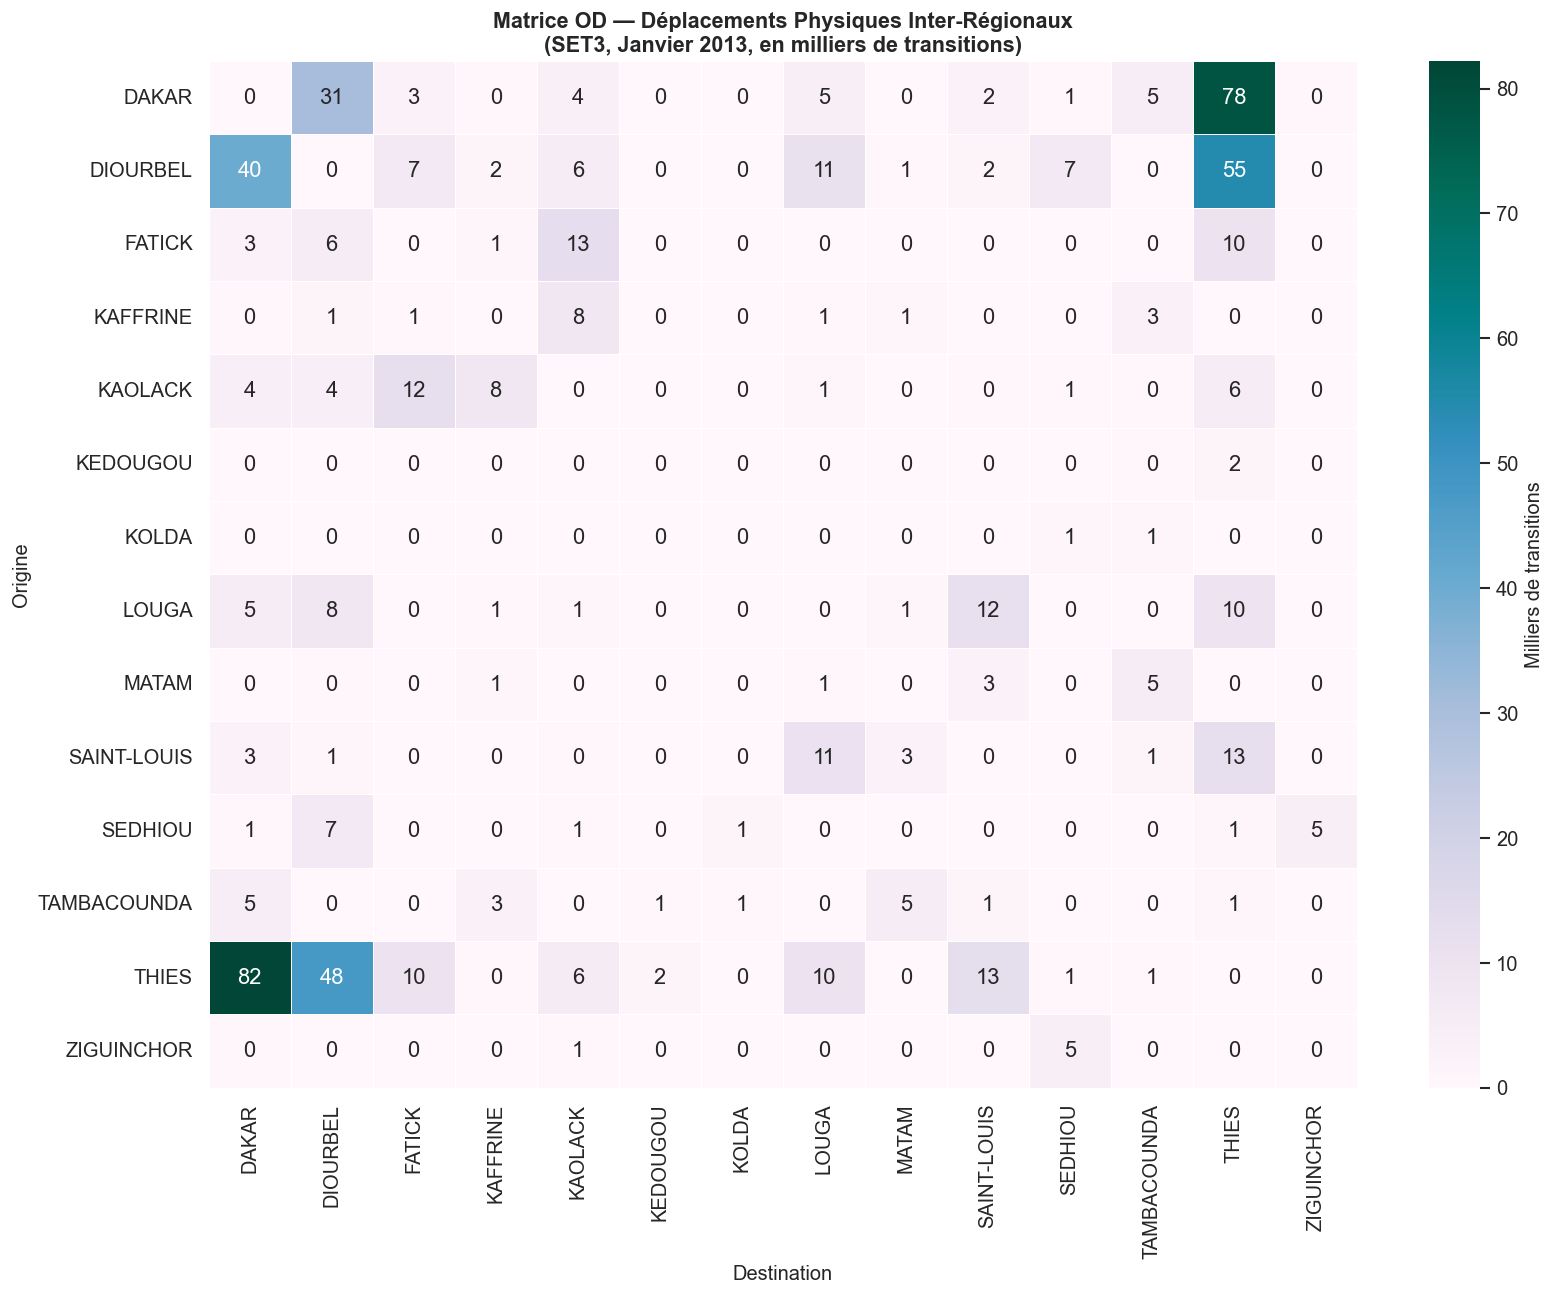

In [40]:
# ============================================================
# C.3 — Matrice OD Physique SET3 (Régionale)
# ============================================================
od_physical = transitions.groupby(['origin_region', 'dest_region']).size().reset_index(name='nb_transitions')
od_physical_inter = od_physical[od_physical['origin_region'] != od_physical['dest_region']]

od_pivot_phys = od_physical_inter.pivot_table(index='origin_region', columns='dest_region',
                                               values='nb_transitions', fill_value=0)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(od_pivot_phys / 1e3, annot=True, fmt='.0f', cmap='PuBuGn', ax=ax,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Milliers de transitions'})
ax.set_title('Matrice OD — Déplacements Physiques Inter-Régionaux\n(SET3, Janvier 2013, en milliers de transitions)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Destination')
ax.set_ylabel('Origine')
plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# C.4 — Classement des Régions par Mobilité Physique (SET3)
# ============================================================
out_phys = transitions.groupby('origin_region').size().rename('departs')
in_phys  = transitions.groupby('dest_region').size().rename('arrivees')
region_mobility = pd.concat([out_phys, in_phys], axis=1).fillna(0).astype(int)
region_mobility['total_mouvements'] = region_mobility['departs'] + region_mobility['arrivees']
region_mobility = region_mobility.sort_values('total_mouvements', ascending=False)
region_mobility['part_%'] = (region_mobility['total_mouvements'] / region_mobility['total_mouvements'].sum() * 100).round(1)

print('📊 CLASSEMENT DES RÉGIONS PAR MOBILITÉ PHYSIQUE (SET3, Janvier 2013)')
display(region_mobility)

📊 CLASSEMENT DES RÉGIONS PAR MOBILITÉ PHYSIQUE (SET3, Janvier 2013)


,departs,arrivees,total_mouvements,part_%
DAKAR,2770077,2784926,5555003,71.7
THIES,413674,416692,830366,10.7
DIOURBEL,173974,150332,324306,4.2
SAINT-LOUIS,87909,89243,177152,2.3
KAOLACK,86146,87810,173956,2.2
LOUGA,82023,83689,165712,2.1
FATICK,57630,57918,115548,1.5
SEDHIOU,43247,42772,86019,1.1
KAFFRINE,40893,41460,82353,1.1
ZIGUINCHOR,36763,36703,73466,0.9


---
### D — Corrélations entre Datasets et Variables

### Question clé : Est-ce que les flux de communication (SET1) sont un bon proxy des flux de mobilité physique (SET3) ?

Si la corrélation est forte, cela signifie que le volume d'appels entre deux zones reflète fidèlement le volume de déplacements réels. Si elle est faible, alors les deux datasets capturent des phénomènes différents.

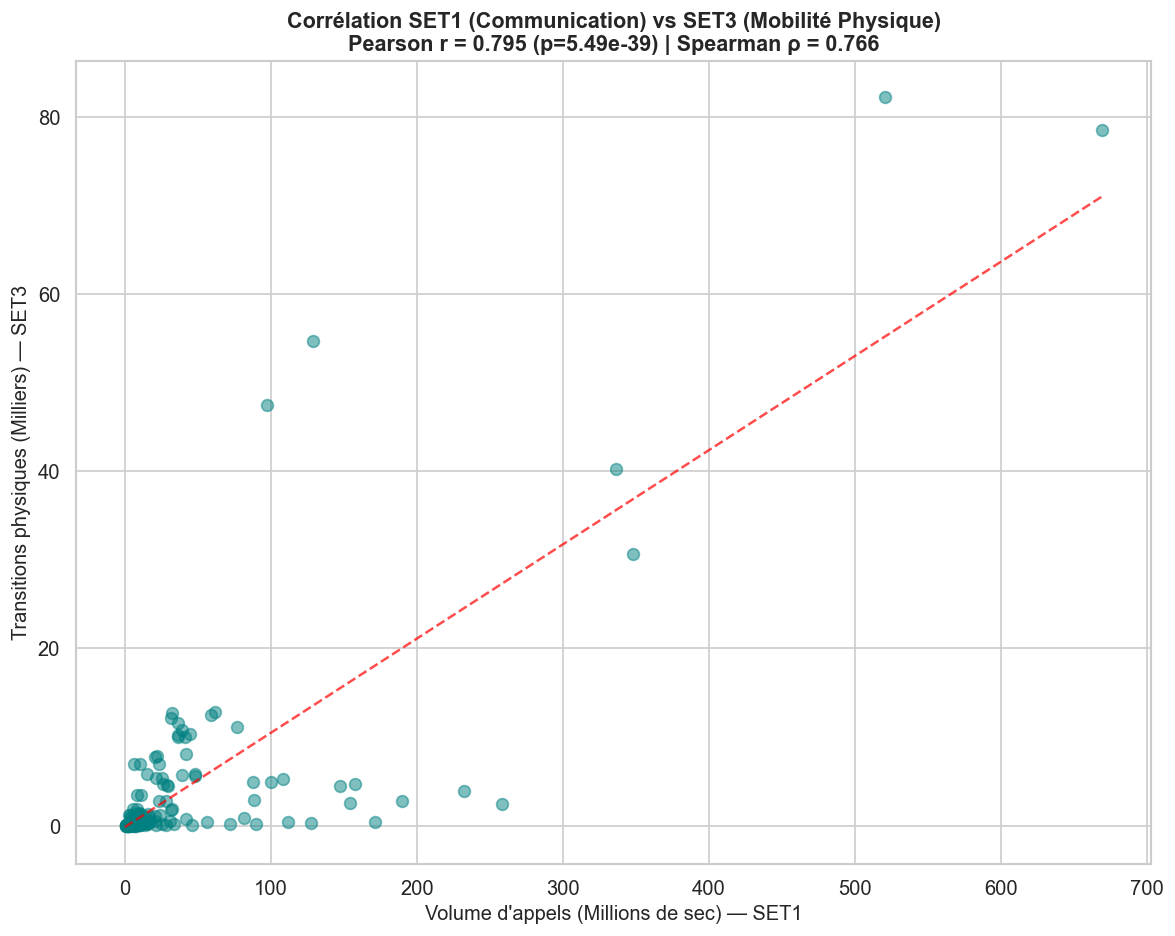


📌 Interprétation :
   → Corrélation FORTE (ρ = 0.766). Les flux de communication sont un bon proxy de la mobilité.


In [42]:
# ============================================================
# D.1 — Corrélation SET1 (Voix) vs SET3 (Mobilité Physique)
#        au niveau des corridors régionaux
# ============================================================

# Préparer les corridors communs
voice_corridors = od_region_voice.copy()
voice_corridors['corridor'] = voice_corridors['origin_region'] + ' → ' + voice_corridors['dest_region']
voice_corridors = voice_corridors.rename(columns={'total_duration_sec': 'voice_sec'})

phys_corridors = od_physical_inter.copy()
phys_corridors['corridor'] = phys_corridors['origin_region'] + ' → ' + phys_corridors['dest_region']

merged = voice_corridors.merge(phys_corridors, on='corridor', how='inner', suffixes=('_v', '_p'))

# Corrélations
from scipy import stats
r_pearson, p_pearson = stats.pearsonr(merged['voice_sec'], merged['nb_transitions'])
r_spearman, p_spearman = stats.spearmanr(merged['voice_sec'], merged['nb_transitions'])

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(merged['voice_sec'] / 1e6, merged['nb_transitions'] / 1e3, 
           alpha=0.5, s=50, color='teal')

# Ligne de tendance
z = np.polyfit(merged['voice_sec'] / 1e6, merged['nb_transitions'] / 1e3, 1)
p = np.poly1d(z)
x_line = np.linspace(0, merged['voice_sec'].max() / 1e6, 100)
ax.plot(x_line, p(x_line), '--', color='red', alpha=0.7)

ax.set_xlabel('Volume d\'appels (Millions de sec) — SET1', fontsize=12)
ax.set_ylabel('Transitions physiques (Milliers) — SET3', fontsize=12)
ax.set_title(f'Corrélation SET1 (Communication) vs SET3 (Mobilité Physique)\n'
             f'Pearson r = {r_pearson:.3f} (p={p_pearson:.2e}) | Spearman ρ = {r_spearman:.3f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'\n📌 Interprétation :')
if r_spearman > 0.7:
    print(f'   → Corrélation FORTE (ρ = {r_spearman:.3f}). Les flux de communication sont un bon proxy de la mobilité.')
elif r_spearman > 0.4:
    print(f'   → Corrélation MODÉRÉE (ρ = {r_spearman:.3f}). Les datasets captent des phénomènes partiellement liés.')
else:
    print(f'   → Corrélation FAIBLE (ρ = {r_spearman:.3f}). Les deux datasets captent des phénomènes différents.')

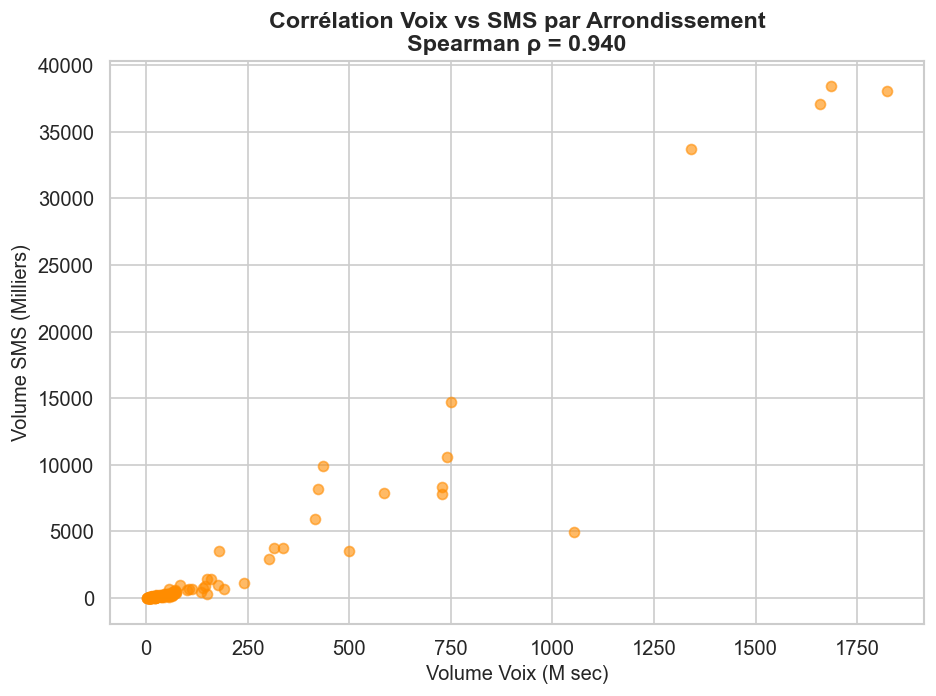

📌 Spearman ρ = 0.940
   → Très corrélés : les deux métriques captent le même signal.
   → On peut les traiter comme deux facettes d'un même phénomène, mais les garder séparés pour la rigueur.


In [43]:
# ============================================================
# D.2 — Corrélation entre Voix et SMS (SET1 interne)
#
# Si les Voix et SMS sont très corrélés, l'un est
# redondant. S'ils sont faiblement corrélés, ils captent des
# comportements différents et nous devons les garder séparés.
# ============================================================

# Agrégation par arrondissement pour comparaison
voice_by_arr = df_v.groupby('origin_arr')['total_duration_sec'].sum().rename('voice_total')
sms_by_arr = df_s.groupby('origin_arr')['nb_sms'].sum().rename('sms_total')
vs_compare = pd.concat([voice_by_arr, sms_by_arr], axis=1).dropna()

r_vs, p_vs = stats.spearmanr(vs_compare['voice_total'], vs_compare['sms_total'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(vs_compare['voice_total'] / 1e6, vs_compare['sms_total'] / 1e3, alpha=0.6, color='darkorange')
ax.set_xlabel('Volume Voix (M sec)')
ax.set_ylabel('Volume SMS (Milliers)')
ax.set_title(f'Corrélation Voix vs SMS par Arrondissement\nSpearman ρ = {r_vs:.3f}', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'📌 Spearman ρ = {r_vs:.3f}')
if r_vs > 0.85:
    print('   → Très corrélés : les deux métriques captent le même signal.')
    print('   → On peut les traiter comme deux facettes d\'un même phénomène, mais les garder séparés pour la rigueur.')
else:
    print('   → Corrélation modérée : traitement SÉPARÉ justifié.')

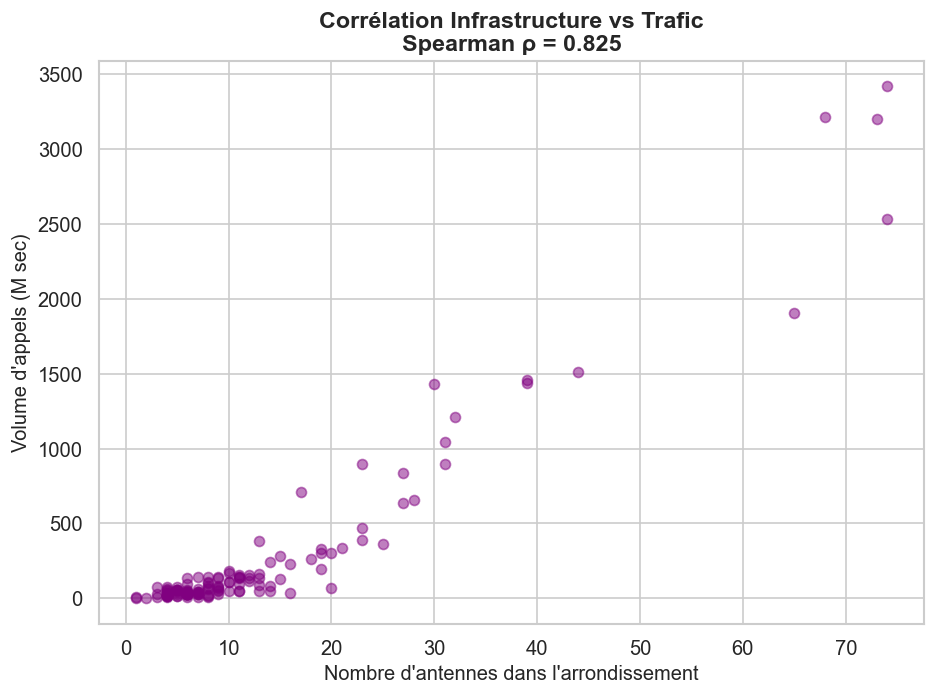

📌 ρ = 0.825
   → ⚠️ BIAIS confirmé : le volume dépend fortement du nombre d'antennes.
   → Recommandation : NORMALISER le trafic par le nombre d'antennes dans le prétraitement.


In [44]:
# ============================================================
# D.3 — Corrélation Nombre d'antennes vs Volume de trafic
#
# POURQUOI : Si cette corrélation est trop forte, cela signifie
# que le trafic mesuré est un artefact du nombre d'antennes,
# pas un reflet de la population réelle. Il faudrait alors
# NORMALISER par le nombre d'antennes.
# ============================================================
corr_data = arr_ranking[['total_sec', 'nb_antennes']].dropna()
r_ant, p_ant = stats.spearmanr(corr_data['total_sec'], corr_data['nb_antennes'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(corr_data['nb_antennes'], corr_data['total_sec'] / 1e6, alpha=0.5, color='purple')
ax.set_xlabel('Nombre d\'antennes dans l\'arrondissement')
ax.set_ylabel('Volume d\'appels (M sec)')
ax.set_title(f'Corrélation Infrastructure vs Trafic\nSpearman ρ = {r_ant:.3f}', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'📌 ρ = {r_ant:.3f}')
if r_ant > 0.8:
    print('   → ⚠️ BIAIS confirmé : le volume dépend fortement du nombre d\'antennes.')
    print('   → Recommandation : NORMALISER le trafic par le nombre d\'antennes dans le prétraitement.')

---
###  E — Détection d'Anomalies et Validation de la Qualité

Avant le prétraitement, il est impératif de détecter les données aberrantes. Une antenne défectueuse ou un pic artificiel peut biaiser tous nos modèles.

Jours dans SET1V_01 : 31 / 31 attendus
  ✅ Aucun jour manquant


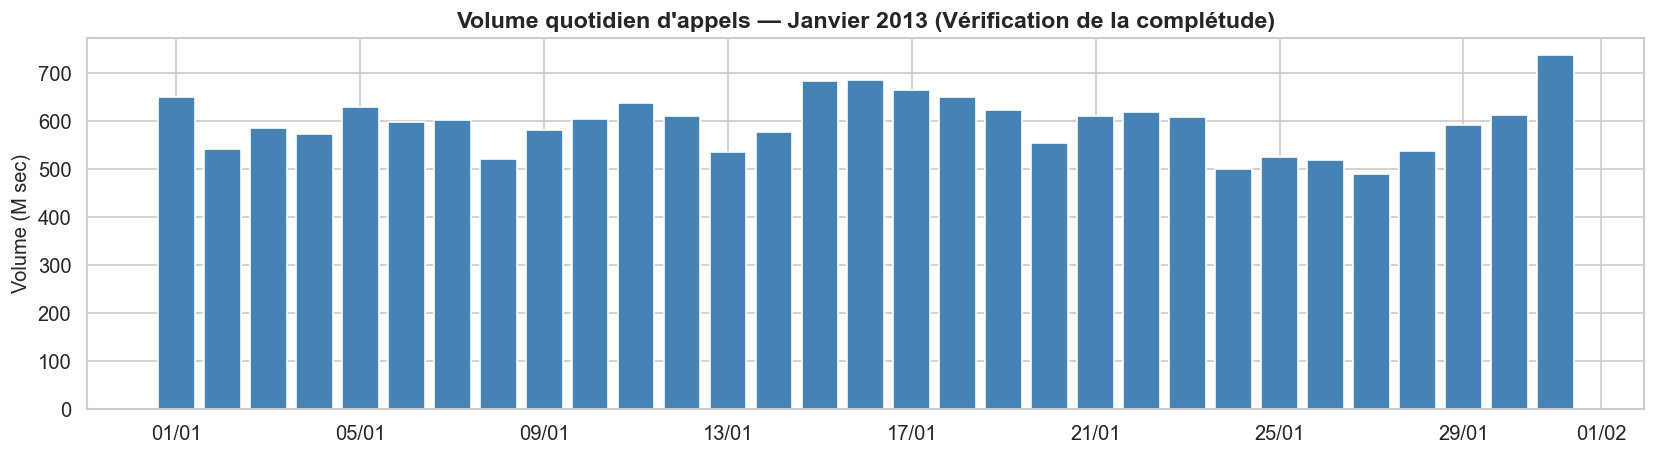

In [45]:
# ============================================================
# E.2 — Couverture temporelle : jours manquants ?
#
# POURQUOI : S'il manque des jours de collecte, les totaux
# mensuels seront biaisés. Il faut le savoir AVANT le prétraitement.
# ============================================================
dates_covered = sorted(df_v['date'].unique())
expected_dates = pd.date_range('2013-01-01', '2013-01-31').strftime('%Y-%m-%d').tolist()
missing = set(expected_dates) - set(dates_covered)

print(f'Jours dans SET1V_01 : {len(dates_covered)} / 31 attendus')
if missing:
    print(f'  ⚠️ Jours manquants : {sorted(missing)}')
else:
    print('  ✅ Aucun jour manquant')

# Trafic par jour
daily = df_v.groupby('date')['total_duration_sec'].sum().reset_index()
daily['date'] = pd.to_datetime(daily['date'])

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(daily['date'], daily['total_duration_sec'] / 1e6, color='steelblue', width=0.8)
ax.set_title('Volume quotidien d\'appels — Janvier 2013 (Vérification de la complétude)', fontweight='bold')
ax.set_ylabel('Volume (M sec)')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d/%m'))
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# E.3 — Synthèse Finale : Classement Multi-Critère des Régions
#
# Ce tableau est le livrable principal de l'EDA.
# Il donne au jury ou à l'État une vue d'ensemble immédiate
# de la hiérarchie des zones par importance de mobilité.
# ============================================================

# Agrégation régionale enrichie
region_summary = arr_ranking.groupby('region').agg(
    nb_arrondissements=('arrondissement', 'count'),
    nb_antennes_total=('nb_antennes', 'sum'),
    trafic_voix_total=('total_sec', 'sum'),
    trafic_sms_total=('total_sms', 'sum'),
    connectivite_moy=('nb_destinations', 'mean'),
    desequilibre_moy=('desequilibre', 'mean'),
    top_arrondissement=('total_sec', 'idxmax')
).sort_values('trafic_voix_total', ascending=False)

region_summary['part_%'] = (region_summary['trafic_voix_total'] / region_summary['trafic_voix_total'].sum() * 100).round(1)
region_summary['cumul_%'] = region_summary['part_%'].cumsum()

# Nom de l'arrondissement top
region_summary['top_arrondissement'] = region_summary['top_arrondissement'].map(
    lambda x: arr_to_meta.get(x, {}).get('arrondissement', '?'))

print('📊 SYNTHÈSE RÉGIONALE MULTI-CRITÈRE (Janvier 2013)')
print('=' * 120)
display(region_summary.style.format({
    'trafic_voix_total': '{:,.0f}',
    'trafic_sms_total': '{:,.0f}',
    'connectivite_moy': '{:.1f}',
    'desequilibre_moy': '{:.3f}',
    'part_%': '{:.1f}',
    'cumul_%': '{:.1f}'
}).background_gradient(cmap='YlOrRd', subset=['trafic_voix_total', 'part_%']))

📊 SYNTHÈSE RÉGIONALE MULTI-CRITÈRE (Janvier 2013)


,nb_arrondissements,nb_antennes_total,trafic_voix_total,trafic_sms_total,connectivite_moy,desequilibre_moy,top_arrondissement,part_%,cumul_%
region,,,,,,,,,
DAKAR,10,489,"752,684,603","28,379,681",121.8,0.035,DAKAR PLATEAU,42.9,42.9
DIOURBEL,8,120,"415,624,037","6,058,861",101.1,0.172,NDAME,23.7,66.6
THIES,12,158,"158,204,458","4,410,278",111.8,0.105,SINDIA,9.0,75.6
SAINT-LOUIS,7,125,"79,045,207","1,633,110",114.9,0.076,RAO,4.5,80.1
ZIGUINCHOR,8,78,"71,916,604","1,388,522",103.9,0.084,NIAGUIS,4.1,84.2
KAOLACK,8,76,"49,439,023","847,715",111.5,0.142,KOUMBAL,2.8,87.0
MATAM,5,72,"38,171,421","275,197",114.8,0.050,OGO,2.2,89.2
TAMBACOUNDA,12,129,"37,098,026","435,070",98.6,0.060,KOUSSANAR,2.1,91.3
FATICK,9,68,"34,971,128","662,343",111.2,0.127,TATTAGUINE,2.0,93.3


## PARTIE 2 : PRÉTRAITEMENT D4D SÉNÉGAL

Cette partie du notebook constitue la **phase de prétraitement officielle** du projet D4D Sénégal. Il prend en entrée les **15 Go de données brutes** (SET1, SET2, SET3) pour améliorer de la mobilité interurbaine au Sénégal.

### Fondements Mathématiques

Contrairement aux approches ad-hoc avec des pondérations arbitraires, nous fondons notre prétraitement sur des **concepts validés académiquement** :

| Concept | Formule | Source | Rôle |
|---------|---------|--------|------|
| **Trafic Erlang** | $E_{ij}(t) = \frac{D_{ij}(t)}{T}$ | Norme ITU-T (Télécommunications) | Mesure l'intensité de la charge vocale site-à-site |
| **Taux d'arrivée SMS** | $\lambda_{ij}(t) = \frac{N_{sms}(t)}{T}$ | Processus de Poisson | Mesure l'intensité du trafic SMS indépendamment de la voix |
| **Indice Pendulaire (PMI)** | $PMI(A,B) = \min(F_{matin}(A{\to}B),\; F_{soir}(B{\to}A))$ | Transport Geography | Isole le flux des navetteurs domicile-travail |
| **Centralité d'Intermédiarité** | $C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$ | Théorie des Graphes (Freeman, 1977) | Identifie les nœuds de transit incontournables |
| **Entropie de Shannon** | $H(X) = -\sum_{i} p_i \log_2 p_i$ | Théorie de l'Information (Shannon, 1948) | Mesure la concentration temporelle du trafic (risque de congestion) |

### Pipeline

```
Données Brutes (45 Go)            Prétraitement              DataFrame ML-Ready
┌─────────────────┐    ┌────────────────────────────┐    ┌──────────────────────┐
│ SET1V (Voix)    │───▶│ 1. Erlang par corridor     │───▶│ Features Télécoms    │
│ SET1S (SMS)     │───▶│ 2. λ SMS par corridor      │    │ Features Pendulaires │
│ SET3 (Traj.)    │───▶│ 3. Transitions physiques   │    │ Features Graph       │
│ SET2 (Traj.)    │───▶│ 4. Indice Pendulaire       │    │ Rankings Géo         │
│ ContextData     │───▶│ 5. Graphe + Centralités    │    │ Scores de Criticité  │
└─────────────────┘    │ 6. Entropie Shannon        │    └──────────────────────┘
                       │ 7. Ranking Régions/Arr.    │
                       └────────────────────────────┘
```

In [1]:
# ════════════════════════════════════════════════════════════════
# 0. IMPORTS ET CONFIGURATION GLOBALE
# ════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import networkx as nx
import geopandas as gpd
from scipy.stats import entropy as shannon_entropy
from scipy import stats
from collections import defaultdict
from pathlib import Path
import csv
import time
import warnings
warnings.filterwarnings('ignore')

# Style
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.figsize': (14, 6), 'figure.dpi': 120, 'axes.titlesize': 13})

# ── Chemins ──
DATA_DIR = Path('../..')
SET1_DIR = DATA_DIR / 'SET1'
SET2_DIR = DATA_DIR / 'SET2'
SET3_DIR = DATA_DIR / 'SET3'
CTX_DIR  = DATA_DIR / 'ContextData'
OUT_DIR  = Path('../outputs/preprocessing_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

ALL_MONTHS = [f'{m:02d}' for m in range(1, 13)]
# Période d'observation par enregistrement SET1 = 1 heure = 3600 secondes
T_OBS = 3600.0

# Plages horaires pendulaires (validées par l'EDA)
MORNING_HOURS = {7, 8, 9, 10}   # Aller travail
EVENING_HOURS = {16, 17, 18, 19} # Retour domicile

print('✅ Configuration chargée')
print(f'   Mois ciblés   : {ALL_MONTHS}')
print(f'   Période T_obs : {T_OBS}s (1 heure)')
print(f'   Heures matin  : {sorted(MORNING_HOURS)}')
print(f'   Heures soir   : {sorted(EVENING_HOURS)}')
print(f'   Sorties dans  : {OUT_DIR.resolve()}')

✅ Configuration chargée
   Mois ciblés   : ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
   Période T_obs : 3600.0s (1 heure)
   Heures matin  : [7, 8, 9, 10]
   Heures soir   : [16, 17, 18, 19]
   Sorties dans  : C:\Users\REGI GROUP\Desktop\DATA\Data\d4d_mobility_pipeline\outputs\preprocessing_v2


In [2]:
# ════════════════════════════════════════════════════════════════
# 1. CHARGEMENT DES DONNÉES DE RÉFÉRENCE GÉOGRAPHIQUE
#
# Hiérarchie administrative du Sénégal :
#   14 Régions → 45 Départements → 123 Arrondissements → 1666 Antennes
#
# Ces tables de référence sont essentielles pour mapper chaque
# enregistrement brut (identifié par un site_id numérique) à sa
# localisation géographique complète.
# ════════════════════════════════════════════════════════════════
df_arr = pd.read_csv(CTX_DIR / 'SENEGAL_ARR_V2.csv')
df_arr.columns = ['arr_id', 'region', 'department', 'arrondissement']

df_sites = pd.read_csv(CTX_DIR / 'SITE_ARR_LONLAT.CSV')
df_sites = df_sites.merge(df_arr, on='arr_id', how='left')

# Dictionnaires de mapping (pour performance dans les boucles)
site_to_arr    = dict(zip(df_sites['site_id'], df_sites['arr_id']))
site_to_region = dict(zip(df_sites['site_id'], df_sites['region']))
site_to_dept   = dict(zip(df_sites['site_id'], df_sites['department']))
arr_to_meta    = dict(zip(df_arr['arr_id'], df_arr.to_dict('records')))

print(f'✅ Référentiel chargé :')
print(f'   {len(df_arr)} arrondissements, {df_arr["department"].nunique()} départements, {df_arr["region"].nunique()} régions')
print(f'   {len(df_sites)} antennes mappées')

✅ Référentiel chargé :
   123 arrondissements, 45 départements, 14 régions
   1666 antennes mappées


---
### A — Extraction des Flux Télécoms SET1 (Voix & SMS)

Pour chaque mois (01 → 12), nous lisons les fichiers SET1V (Voix) et SET1S (SMS) par **chunks** de 2 millions de lignes (pour ne pas saturer la RAM), et nous agrégeons les flux au niveau **arrondissement → arrondissement** avec les métriques suivantes :

- **`voice_erlang`** : Charge vocale en Erlangs = `durée_totale / 3600`
- **`sms_lambda`** : Taux d'arrivée SMS = `nb_sms / 3600`
- **`morning_voice_erlang`** / **`evening_voice_erlang`** : Erlangs filtrés sur les plages matin (07h-10h) et soir (16h-19h) pour le calcul pendulaire
- **`morning_sms_lambda`** / **`evening_sms_lambda`** : Idem pour les SMS

Chaque mois est sauvegardé indépendamment pour permettre la reprise en cas d'interruption.

In [3]:
# ════════════════════════════════════════════════════════════════
# 1.1 — Fonction de traitement d'un chunk SET1
#
# Chaque ligne brute contient :
#   Voice : timestamp | origin_site | dest_site | nb_calls | duration_sec
#   SMS   : timestamp | origin_site | dest_site | nb_sms
#
# On convertit chaque ligne en métriques Erlang/Lambda, puis on
# agrège par (date, origin_arr, dest_arr).
# ════════════════════════════════════════════════════════════════

SET1_METRICS = [
    'nb_calls', 'voice_duration_sec', 'nb_sms',
    'voice_erlang', 'sms_lambda',
    'morning_voice_erlang', 'evening_voice_erlang',
    'morning_sms_lambda', 'evening_sms_lambda'
]

def process_set1_chunk(chunk, kind):
    """
    Enrichit un chunk SET1 avec les métriques télécoms.
    
    Parameters
    ----------
    chunk : pd.DataFrame — chunk brut du CSV
    kind  : str — 'voice' ou 'sms'
    
    Returns
    -------
    pd.DataFrame agrégé par (date, hour, origin_arr, dest_arr, origin_region, dest_region)
    """
    # Mapping géographique
    chunk['origin_arr']    = chunk['origin_site'].map(site_to_arr)
    chunk['dest_arr']      = chunk['dest_site'].map(site_to_arr)
    chunk['origin_region'] = chunk['origin_site'].map(site_to_region)
    chunk['dest_region']   = chunk['dest_site'].map(site_to_region)
    chunk.dropna(subset=['origin_arr', 'dest_arr'], inplace=True)
    if chunk.empty:
        return chunk
    
    chunk['origin_arr'] = chunk['origin_arr'].astype(int)
    chunk['dest_arr']   = chunk['dest_arr'].astype(int)
    chunk['date'] = chunk['timestamp'].str[:10]
    chunk['hour'] = chunk['timestamp'].str[11:13].astype(int)
    
    # Classification horaire
    is_morning = chunk['hour'].isin(MORNING_HOURS)
    is_evening = chunk['hour'].isin(EVENING_HOURS)
    
    if kind == 'voice':
        chunk['nb_calls']           = chunk['nb_calls_raw'].fillna(0).astype(float)
        chunk['voice_duration_sec'] = chunk['duration_raw'].fillna(0).astype(float)
        chunk['nb_sms']             = 0.0
        
        # ── FORMULE ERLANG : E = D / T ──
        chunk['voice_erlang'] = chunk['voice_duration_sec'] / T_OBS
        chunk['sms_lambda']   = 0.0
        
        # Filtrage pendulaire
        chunk['morning_voice_erlang'] = chunk['voice_erlang'].where(is_morning, 0.0)
        chunk['evening_voice_erlang'] = chunk['voice_erlang'].where(is_evening, 0.0)
        chunk['morning_sms_lambda']   = 0.0
        chunk['evening_sms_lambda']   = 0.0
    else:
        chunk['nb_calls']           = 0.0
        chunk['voice_duration_sec'] = 0.0
        chunk['nb_sms']             = chunk['nb_sms_raw'].fillna(0).astype(float)
        
        chunk['voice_erlang'] = 0.0
        # ── TAUX D'ARRIVÉE POISSON : λ = N / T ──
        chunk['sms_lambda']   = chunk['nb_sms'] / T_OBS
        
        chunk['morning_voice_erlang'] = 0.0
        chunk['evening_voice_erlang'] = 0.0
        chunk['morning_sms_lambda']   = chunk['sms_lambda'].where(is_morning, 0.0)
        chunk['evening_sms_lambda']   = chunk['sms_lambda'].where(is_evening, 0.0)
    
    # Agrégation
    grouped = chunk.groupby(
        ['date', 'hour', 'origin_arr', 'dest_arr', 'origin_region', 'dest_region'],
        as_index=False
    )[SET1_METRICS].sum()
    
    return grouped

print('✅ Fonction process_set1_chunk définie')

✅ Fonction process_set1_chunk définie


In [4]:
# ════════════════════════════════════════════════════════════════
# 1.2 — Traitement Complet SET1 : 12 Mois × (Voix + SMS)
#
# STRATÉGIE BIG DATA :
#   - Lecture par chunks de 2M lignes (pd.read_csv chunksize)
#   - Agrégation en mémoire dans un dictionnaire compact
#   - Sauvegarde CSV par mois pour reprise
#   - Les fichiers déjà traités sont automatiquement ignorés
#
# TEMPS ESTIMÉ : ~15-30 min par mois selon la machine.
# ════════════════════════════════════════════════════════════════

set1_monthly_dir = OUT_DIR / 'set1_monthly'
set1_monthly_dir.mkdir(exist_ok=True)

CHUNKSIZE = 500_000

for month in ALL_MONTHS:
    out_path = set1_monthly_dir / f'set1_arr_od_M{month}.parquet'
    
    # Reprise : sauter si déjà traité
    if out_path.exists():
        print(f'  Mois {month} : déjà traité → {out_path.name}')
        continue
    
    print(f'\n{"="*60}')
    print(f'  TRAITEMENT MOIS {month}')
    print(f'{"="*60}')
    t0 = time.time()
    
    # Accumulateur compact : clé = (date, hour, o_arr, d_arr, o_reg, d_reg)
    store = defaultdict(lambda: np.zeros(len(SET1_METRICS)))
    
    for kind, label in [('voice', 'SET1V'), ('sms', 'SET1S')]:
        if kind == 'voice':
            path = SET1_DIR / f'SET1V_{month}.CSV.gz'
            col_names = ['timestamp', 'origin_site', 'dest_site', 'nb_calls_raw', 'duration_raw']
        else:
            path = SET1_DIR / f'SET1S_{month}.CSV.gz'
            col_names = ['timestamp', 'origin_site', 'dest_site', 'nb_sms_raw']
        
        if not path.exists():
            print(f'    ⚠️ Fichier manquant : {path.name}')
            continue
        
        rows_processed = 0
        for ci, chunk in enumerate(pd.read_csv(path, compression='gzip', header=None,
                                                names=col_names, chunksize=CHUNKSIZE), 1):
            rows_processed += len(chunk)
            enriched = process_set1_chunk(chunk, kind)
            
            if not enriched.empty:
                for row in enriched.itertuples(index=False):
                    key = (row.date, row.hour, row.origin_arr, row.dest_arr,
                           row.origin_region, row.dest_region)
                    vals = store[key]
                    for mi, metric in enumerate(SET1_METRICS):
                        vals[mi] += getattr(row, metric)
            
            if ci == 1 or ci % 10 == 0:
                print(f'    {label}_{month} chunk {ci:>3} | {rows_processed:>12,} lignes | '
                      f'{len(store):>8,} groupes uniques', flush=True)
        
        print(f'    ✅ {label}_{month} terminé : {rows_processed:,} lignes')
    
    # Conversion du store en DataFrame et sauvegarde
    records = []
    for (date, hour, o_arr, d_arr, o_reg, d_reg), vals in store.items():
        rec = {'date': date, 'hour': hour, 'origin_arr': o_arr, 'dest_arr': d_arr,
               'origin_region': o_reg, 'dest_region': d_reg}
        for mi, metric in enumerate(SET1_METRICS):
            rec[metric] = round(vals[mi], 6)
        records.append(rec)
    
    df_month = pd.DataFrame(records)
    df_month.to_parquet(out_path, index=False)
    elapsed = time.time() - t0
    print(f'  📦 Sauvegardé : {out_path.name} ({len(df_month):,} lignes) en {elapsed/60:.1f} min')
    del store, records, df_month  # Libérer la RAM

print('\n✅ PHASE 1 TERMINÉE — Tous les mois SET1 traités.')


  TRAITEMENT MOIS 01
    SET1V_01 chunk   1 |      500,000 lignes |   19,493 groupes uniques
    SET1V_01 chunk  10 |    5,000,000 lignes |  208,324 groupes uniques
    SET1V_01 chunk  20 |   10,000,000 lignes |  404,823 groupes uniques
    SET1V_01 chunk  30 |   15,000,000 lignes |  621,812 groupes uniques
    SET1V_01 chunk  40 |   20,000,000 lignes |  836,600 groupes uniques
    SET1V_01 chunk  50 |   25,000,000 lignes | 1,059,504 groupes uniques
    SET1V_01 chunk  60 |   30,000,000 lignes | 1,268,280 groupes uniques
    SET1V_01 chunk  70 |   35,000,000 lignes | 1,486,304 groupes uniques
    SET1V_01 chunk  80 |   40,000,000 lignes | 1,687,461 groupes uniques
    SET1V_01 chunk  90 |   45,000,000 lignes | 1,919,503 groupes uniques
    SET1V_01 chunk 100 |   50,000,000 lignes | 2,128,698 groupes uniques
    SET1V_01 chunk 110 |   55,000,000 lignes | 2,328,752 groupes uniques
    SET1V_01 chunk 120 |   60,000,000 lignes | 2,540,923 groupes uniques
    SET1V_01 chunk 130 |   65,000,

---
### B — Extraction des Transitions Physiques SET3 (Trajectoires par Arrondissement)

Le SET3 contient les positions successives de chaque utilisateur anonymisé, horodatées, au niveau de l'**arrondissement**. Un **déplacement physique** est détecté lorsqu'un utilisateur apparaît dans un arrondissement différent du précédent.

Pour chaque mois, nous détectons ces transitions et comptons :
- Le nombre total de transitions par corridor (A → B)
- Le nombre d'utilisateurs uniques ayant emprunté ce corridor
- Les transitions matin et soir (pour le PMI)

In [5]:
# ════════════════════════════════════════════════════════════════
# 2.1 — Traitement SET3 : 12 Mois de Trajectoires
#
# Format brut SET3 : userid | timestamp | arr_id
#
# Détection de transition :
#   Si pour un userid, l'enregistrement précédent était dans
#   arr_A et le suivant dans arr_B (A ≠ B), c'est un déplacement
#   physique de A vers B.
# ════════════════════════════════════════════════════════════════

set3_monthly_dir = OUT_DIR / 'set3_monthly'
set3_monthly_dir.mkdir(exist_ok=True)

for month in ALL_MONTHS:
    out_path = set3_monthly_dir / f'set3_transitions_M{month}.parquet'
    if out_path.exists():
        print(f'  Mois {month} : déjà traité → {out_path.name}')
        continue
    
    path = SET3_DIR / f'SET3_M{month}.CSV.gz'
    if not path.exists():
        print(f'  ⚠️ Fichier manquant : {path.name}')
        continue
    
    print(f'\n  SET3 Mois {month}...', flush=True)
    t0 = time.time()
    
    # Accumulateurs
    trans_count = defaultdict(int)           # (o_arr, d_arr) → count
    trans_users = defaultdict(set)           # (o_arr, d_arr) → {userids}
    trans_morning = defaultdict(int)         # (o_arr, d_arr) → count (matin)
    trans_evening = defaultdict(int)         # (o_arr, d_arr) → count (soir)
    
    last_seen = {}  # userid → (timestamp, arr_id) pour la continuité inter-chunks
    rows_total = 0
    transitions_total = 0
    
    col_names = ['userid', 'timestamp', 'arr_id']
    for ci, chunk in enumerate(pd.read_csv(path, compression='gzip', header=None,
                                            names=col_names, chunksize=1_000_000), 1):
        rows_total += len(chunk)
        chunk = chunk.dropna().copy()
        chunk['userid'] = chunk['userid'].astype(int)
        chunk['arr_id'] = chunk['arr_id'].astype(int)
        chunk['timestamp'] = pd.to_datetime(chunk['timestamp'], errors='coerce')
        chunk = chunk.dropna(subset=['timestamp']).sort_values(['userid', 'timestamp'])
        
        # Injecter la dernière position connue de chaque user du chunk précédent
        if last_seen:
            boundary = pd.DataFrame([
                {'userid': uid, 'timestamp': ts, 'arr_id': arr}
                for uid, (ts, arr) in last_seen.items()
            ])
            if not boundary.empty:
                chunk = pd.concat([boundary, chunk], ignore_index=True).sort_values(['userid', 'timestamp'])
        
        # Détection des transitions
        chunk['prev_user'] = chunk['userid'].shift(1)
        chunk['prev_arr']  = chunk['arr_id'].shift(1)
        
        mask = ((chunk['userid'] == chunk['prev_user']) &
                (chunk['arr_id'] != chunk['prev_arr']) &
                chunk['prev_arr'].notna())
        trans = chunk[mask].copy()
        trans['prev_arr'] = trans['prev_arr'].astype(int)
        trans['hour'] = trans['timestamp'].dt.hour
        
        for row in trans.itertuples(index=False):
            key = (row.prev_arr, row.arr_id)
            trans_count[key] += 1
            trans_users[key].add(row.userid)
            if row.hour in MORNING_HOURS:
                trans_morning[key] += 1
            elif row.hour in EVENING_HOURS:
                trans_evening[key] += 1
        
        transitions_total += len(trans)
        
        # Sauvegarder la dernière position de chaque user
        last_rows = chunk.sort_values(['userid', 'timestamp']).groupby('userid').tail(1)
        last_seen = {int(r.userid): (r.timestamp, int(r.arr_id)) for r in last_rows.itertuples(index=False)}
        
        if ci == 1 or ci % 20 == 0:
            print(f'    chunk {ci:>3} | {rows_total:>10,} lignes | {transitions_total:>8,} transitions', flush=True)
    
    # Conversion en DataFrame
    records = []
    for (o, d), count in trans_count.items():
        o_meta = arr_to_meta.get(o, {})
        d_meta = arr_to_meta.get(d, {})
        records.append({
            'origin_arr': o, 'dest_arr': d,
            'origin_region': o_meta.get('region', 'UNKNOWN'),
            'dest_region': d_meta.get('region', 'UNKNOWN'),
            'origin_arrondissement': o_meta.get('arrondissement', 'UNKNOWN'),
            'dest_arrondissement': d_meta.get('arrondissement', 'UNKNOWN'),
            'transition_count': count,
            'unique_users': len(trans_users[(o, d)]),
            'morning_transitions': trans_morning.get((o, d), 0),
            'evening_transitions': trans_evening.get((o, d), 0),
        })
    
    df_t = pd.DataFrame(records)
    df_t.to_parquet(out_path, index=False)
    elapsed = time.time() - t0
    print(f'  📦 {out_path.name} : {len(df_t):,} corridors, {transitions_total:,} transitions, {elapsed/60:.1f} min')
    del trans_count, trans_users, trans_morning, trans_evening, last_seen

print('\n✅ PHASE 2 TERMINÉE — Tous les mois SET3 traités.')


  SET3 Mois 01...
    chunk   1 |  1,000,000 lignes |   48,929 transitions
    chunk  20 | 20,000,000 lignes | 1,409,241 transitions
    chunk  40 | 40,000,000 lignes | 2,793,476 transitions
  📦 set3_transitions_M01.parquet : 9,311 corridors, 3,015,453 transitions, 4.2 min

  SET3 Mois 02...
    chunk   1 |  1,000,000 lignes |   47,415 transitions
    chunk  20 | 20,000,000 lignes | 1,289,655 transitions
  📦 set3_transitions_M02.parquet : 8,755 corridors, 2,463,485 transitions, 2.2 min

  SET3 Mois 03...
    chunk   1 |  1,000,000 lignes |   48,657 transitions
    chunk  20 | 20,000,000 lignes | 1,292,240 transitions
    chunk  40 | 40,000,000 lignes | 2,589,321 transitions
  📦 set3_transitions_M03.parquet : 9,264 corridors, 2,796,528 transitions, 2.5 min

  SET3 Mois 04...
    chunk   1 |  1,000,000 lignes |   46,429 transitions
    chunk  20 | 20,000,000 lignes | 1,242,954 transitions
    chunk  40 | 40,000,000 lignes | 2,506,143 transitions
  📦 set3_transitions_M04.parquet : 9,302 

---
### C — Agrégation Annuelle et Ingénierie des Caractéristiques

Nous fusionnons les 12 fichiers mensuels en un seul jeu de données annuel, puis nous calculons les features avancées :
1. **Erlang annuel moyen** par corridor
2. **Indice de Mobilité Pendulaire (PMI)** par corridor
3. **Entropie de Shannon temporelle** par arrondissement
4. **Centralité d'Intermédiarité et de Vecteur Propre** sur le graphe de mobilité

In [6]:
# ════════════════════════════════════════════════════════════════
# 3.1 — Chargement et Fusion des 12 Mois SET1
# ════════════════════════════════════════════════════════════════
print('Chargement des 12 mois SET1...')
set1_files = sorted(set1_monthly_dir.glob('set1_arr_od_M*.parquet'))
print(f'  Fichiers trouvés : {len(set1_files)}')

if set1_files:
    df_set1_all = pd.concat([pd.read_parquet(f) for f in set1_files], ignore_index=True)
    df_set1_all['month'] = df_set1_all['date'].str[5:7]
    print(f'  → {len(df_set1_all):,} lignes (date × heure × corridor)')
    
    # Agrégation annuelle par corridor (somme sur les 12 mois)
    agg_cols = ['voice_erlang', 'sms_lambda', 'morning_voice_erlang', 'evening_voice_erlang',
                'morning_sms_lambda', 'evening_sms_lambda', 'nb_calls', 'voice_duration_sec', 'nb_sms']
    
    df_set1_annual = df_set1_all.groupby(
        ['origin_arr', 'dest_arr', 'origin_region', 'dest_region'],
        as_index=False
    )[agg_cols].sum()
    
    # Agrégation mensuelle pour l'analyse saisonnière
    df_set1_monthly = df_set1_all.groupby(
        ['month', 'origin_arr', 'dest_arr'],
        as_index=False
    )[['voice_erlang', 'sms_lambda']].sum()
    
    print(f'  → {len(df_set1_annual):,} corridors annuels uniques')
else:
    print('  ⚠️ Aucun fichier SET1 trouvé. Exécutez d\'abord la Phase 1.')

Chargement des 12 mois SET1...
  Fichiers trouvés : 12
  → 58,507,372 lignes (date × heure × corridor)
  → 15,129 corridors annuels uniques


In [7]:
# ════════════════════════════════════════════════════════════════
# 3.2 — Chargement et Fusion des 12 Mois SET3
# ════════════════════════════════════════════════════════════════
print('Chargement des 12 mois SET3...')
set3_files = sorted(set3_monthly_dir.glob('set3_transitions_M*.parquet'))
print(f'  Fichiers trouvés : {len(set3_files)}')

if set3_files:
    df_set3_all = pd.concat([pd.read_parquet(f) for f in set3_files], ignore_index=True)
    
    df_set3_annual = df_set3_all.groupby(
        ['origin_arr', 'dest_arr', 'origin_region', 'dest_region',
         'origin_arrondissement', 'dest_arrondissement'],
        as_index=False
    ).agg({
        'transition_count': 'sum',
        'unique_users': 'sum',  # Note: ce n'est pas exact (union), mais approx. acceptable
        'morning_transitions': 'sum',
        'evening_transitions': 'sum'
    })
    
    print(f'  → {len(df_set3_annual):,} corridors physiques annuels')
else:
    print('  ⚠️ Aucun fichier SET3 trouvé.')

Chargement des 12 mois SET3...
  Fichiers trouvés : 12
  → 12,888 corridors physiques annuels


In [8]:
# ════════════════════════════════════════════════════════════════
# 3.3 — Calcul de l'Indice de Mobilité Pendulaire (PMI)
#
# FORMULE :
#   PMI(A, B) = min( Flux_matin(A → B), Flux_soir(B → A) )
#
# INTERPRÉTATION :
#   Si 5000 personnes vont de Pikine vers Dakar Plateau le matin,
#   et 4800 font le trajet inverse le soir, alors PMI = 4800.
#   C'est le nombre de navetteurs quotidiens réels (commuters).
#
# Nous calculons le PMI pour les deux sources :
#   - SET1 (basé sur les Erlangs matin/soir)
#   - SET3 (basé sur les transitions physiques matin/soir)
# ════════════════════════════════════════════════════════════════

def compute_pmi(df, morning_col, evening_col, origin_col='origin_arr', dest_col='dest_arr'):
    """
    Calcule l'Indice de Mobilité Pendulaire pour chaque corridor.
    PMI(A,B) = min( morning(A→B), evening(B→A) )
    """
    # Créer un lookup pour le flux soir inverse
    evening_reverse = df.set_index([dest_col, origin_col])[evening_col].to_dict()
    
    pmi_values = []
    for _, row in df.iterrows():
        morning_ab = row[morning_col]
        evening_ba = evening_reverse.get((row[origin_col], row[dest_col]), 0)
        pmi_values.append(min(morning_ab, evening_ba))
    
    return pmi_values

# PMI sur SET1 (Erlang)
if 'df_set1_annual' in dir():
    df_set1_annual['pmi_erlang'] = compute_pmi(
        df_set1_annual, 'morning_voice_erlang', 'evening_voice_erlang')
    print(f'✅ PMI Erlang calculé sur {len(df_set1_annual):,} corridors')
    print(f'   Top 5 corridors pendulaires (Erlang) :')
    top_pmi = df_set1_annual.nlargest(5, 'pmi_erlang')[['origin_arr', 'dest_arr', 'origin_region', 
                                                          'dest_region', 'voice_erlang', 'pmi_erlang']]
    # Enrichir avec les noms
    top_pmi['origin_name'] = top_pmi['origin_arr'].map(lambda x: arr_to_meta.get(x, {}).get('arrondissement', '?'))
    top_pmi['dest_name'] = top_pmi['dest_arr'].map(lambda x: arr_to_meta.get(x, {}).get('arrondissement', '?'))
    display(top_pmi[['origin_name', 'origin_region', 'dest_name', 'dest_region', 'voice_erlang', 'pmi_erlang']])

# PMI sur SET3 (Transitions physiques)
if 'df_set3_annual' in dir():
    df_set3_annual['pmi_physical'] = compute_pmi(
        df_set3_annual, 'morning_transitions', 'evening_transitions')
    print(f'\n✅ PMI Physique calculé sur {len(df_set3_annual):,} corridors')

✅ PMI Erlang calculé sur 15,129 corridors
   Top 5 corridors pendulaires (Erlang) :


,origin_name,origin_region,dest_name,dest_region,voice_erlang,pmi_erlang
372,DAKAR PLATEAU,DAKAR,DAKAR PLATEAU,DAKAR,2.310765e+06,298246.997475
2976,NDAME,DIOURBEL,NDAME,DIOURBEL,1.468359e+06,236848.024723
1364,SINDIA,THIES,SINDIA,THIES,1.603274e+06,195879.783315
248,GRAND DAKAR,DAKAR,GRAND DAKAR,DAKAR,1.902582e+06,184463.030286
0,PARCELLES ASSAINIES,DAKAR,PARCELLES ASSAINIES,DAKAR,2.119166e+06,169735.135836



✅ PMI Physique calculé sur 12,888 corridors


In [10]:
# ════════════════════════════════════════════════════════════════
# 3.5 — Construction du Graphe de Mobilité et Centralités
#
# Nous construisons un graphe orienté pondéré G(V, E) où :
#   - V = arrondissements (123 nœuds)
#   - E = corridors avec poids = Erlang annuel total (voix)
#
# Métriques calculées (théorie des graphes) :
#
# 1. CENTRALITÉ D'INTERMÉDIARITÉ (Betweenness Centrality)
#    C_B(v) = Σ_{s≠v≠t} σ_st(v) / σ_st
#    → Mesure à quel point un arrondissement est un passage OBLIGÉ
#      sur les chemins les plus courts du réseau. Un nœud à forte
#      intermédiarité est un hub de transit critique.
#
# 2. CENTRALITÉ DE VECTEUR PROPRE (Eigenvector Centrality)
#    → Un arrondissement est important s'il est connecté à d'autres
#      arrondissements importants. Capte l'influence structurelle.
#
# 3. DEGRÉ PONDÉRÉ (Weighted Degree / Strength)
#    S(v) = Σ_u w(v,u)
#    → Volume total de trafic entrant + sortant.
# ════════════════════════════════════════════════════════════════

if 'df_set1_annual' in dir():
    # Filtrer les flux inter-arrondissements
    df_inter = df_set1_annual[df_set1_annual['origin_arr'] != df_set1_annual['dest_arr']].copy()
    
    # Construction du graphe
    G = nx.DiGraph()
    for _, row in df_inter.iterrows():
        if row['voice_erlang'] > 0:
            G.add_edge(int(row['origin_arr']), int(row['dest_arr']),
                       weight=row['voice_erlang'],
                       sms_weight=row['sms_lambda'],
                       pmi=row.get('pmi_erlang', 0))
    
    print(f'Graphe construit : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arêtes')
    
    # Pour Betweenness, on inverse les poids ("distance" = 1/poids)
    for u, v, d in G.edges(data=True):
        d['distance'] = 1.0 / max(d['weight'], 1e-10)
    
    # Calcul des centralités
    print('Calcul de la Centralité d\'Intermédiarité (Betweenness)...')
    betweenness = nx.betweenness_centrality(G, weight='distance', normalized=True)
    
    print('Calcul de la Centralité de Vecteur Propre (Eigenvector)...')
    try:
        eigenvector = nx.eigenvector_centrality_numpy(G, weight='weight')
    except Exception:
        eigenvector = nx.eigenvector_centrality(G, weight='weight', max_iter=1000, tol=1e-4)
    
    # Degré pondéré (in + out)
    in_strength  = dict(G.in_degree(weight='weight'))
    out_strength = dict(G.out_degree(weight='weight'))
    
    # Assemblage
    graph_records = []
    for node in G.nodes():
        meta = arr_to_meta.get(node, {})
        graph_records.append({
            'arr_id': node,
            'region': meta.get('region', 'UNKNOWN'),
            'department': meta.get('department', 'UNKNOWN'),
            'arrondissement': meta.get('arrondissement', 'UNKNOWN'),
            'betweenness_centrality': round(betweenness.get(node, 0), 6),
            'eigenvector_centrality': round(eigenvector.get(node, 0), 6),
            'in_strength_erlang': round(in_strength.get(node, 0), 3),
            'out_strength_erlang': round(out_strength.get(node, 0), 3),
            'total_strength_erlang': round(in_strength.get(node, 0) + out_strength.get(node, 0), 3),
            'connectivity': G.degree(node),
        })
    
    df_graph = pd.DataFrame(graph_records)
    
    # Joindre l'entropie
    if 'df_entropy' in dir():
        df_graph = df_graph.merge(df_entropy, on='arr_id', how='left')
        df_graph['entropy_temporal'] = df_graph['entropy_temporal'].fillna(0)
    
    df_graph = df_graph.sort_values('betweenness_centrality', ascending=False)
    
    print(f'\n✅ {len(df_graph)} arrondissements scorés.')
    print(f'\n📊 TOP 15 — ARRONDISSEMENTS PAR CENTRALITÉ D\'INTERMÉDIARITÉ :')
    display(df_graph[['arrondissement', 'region', 'department', 'betweenness_centrality',
                       'eigenvector_centrality', 'total_strength_erlang', 'entropy_temporal',
                       'connectivity']].head(15))
else:
    print('⚠️ Données SET1 annuelles non disponibles.')

Graphe construit : 123 nœuds, 15006 arêtes
Calcul de la Centralité d'Intermédiarité (Betweenness)...
Calcul de la Centralité de Vecteur Propre (Eigenvector)...

✅ 123 arrondissements scorés.

📊 TOP 15 — ARRONDISSEMENTS PAR CENTRALITÉ D'INTERMÉDIARITÉ :


,arrondissement,region,department,betweenness_centrality,eigenvector_centrality,total_strength_erlang,entropy_temporal,connectivity
0,PARCELLES ASSAINIES,DAKAR,DAKAR,0.783159,0.447900,1.059706e+07,4.1703,244
24,NDAME,DIOURBEL,MBACKE,0.350156,0.096038,4.142417e+06,3.7851,244
53,KOUMBAL,KAOLACK,KAOLACK,0.165967,0.095919,2.726341e+06,4.1688,244
106,KOUSSANAR,TAMBACOUNDA,TAMBACOUNDA,0.163460,0.026061,1.010197e+06,4.1386,244
99,NIAGUIS,ZIGUINCHOR,ZIGUINCHOR,0.149099,0.065690,1.810171e+06,4.1470,244
3,DAKAR PLATEAU,DAKAR,DAKAR,0.096870,0.411148,9.552322e+06,4.1590,244
82,SARE BIDJI,KOLDA,KOLDA,0.094161,0.024718,7.668574e+05,4.1421,244
72,RAO,SAINT-LOUIS,SAINT-LOUIS,0.085964,0.084168,2.240557e+06,4.1796,244
2,GRAND DAKAR,DAKAR,DAKAR,0.083254,0.453709,1.014748e+07,4.1903,244
100,BANDAFASSI,KEDOUGOU,KEDOUGOU,0.064625,0.011081,5.289616e+05,4.1294,244


---
### D — Classement Final : Régions → Départements → Arrondissements

C'est le livrable clé du prétraitement. Pour chaque niveau de la hiérarchie géographique, nous produisons un classement clair et justifié par les métriques calculées.

📊 CLASSEMENT DES 14 RÉGIONS DU SÉNÉGAL PAR VOLUME DE TRAFIC (Annuel)


,nb_arrondissements,total_erlang,max_betweenness,mean_betweenness,mean_entropy,total_connectivity,top_arrondissement,part_nationale_%,cumul_%
region,,,,,,,,,
DAKAR,10,"63,081,646",0.7832,0.0980,4.17,2440,PARCELLES ASSAINIES,55.4,55.4
THIES,12,"11,689,834",0.0484,0.0074,4.14,2928,SINDIA,10.3,65.7
DIOURBEL,8,"6,175,149",0.3502,0.0448,4.06,1952,NDAME,5.4,71.1
SAINT-LOUIS,7,"5,722,381",0.0860,0.0216,4.12,1708,RAO,5.0,76.1
KAOLACK,8,"4,593,085",0.1660,0.0207,4.14,1952,KOUMBAL,4.0,80.1
ZIGUINCHOR,8,"3,831,409",0.1491,0.0207,4.12,1952,NIAGUIS,3.4,83.5
LOUGA,11,"3,561,646",0.0163,0.0015,4.12,2684,MBEDIENE,3.1,86.6
FATICK,9,"3,068,895",0.0000,0.0000,4.12,2196,TATTAGUINE,2.7,89.3
MATAM,5,"2,974,964",0.0169,0.0051,4.07,1220,OGO,2.6,91.9


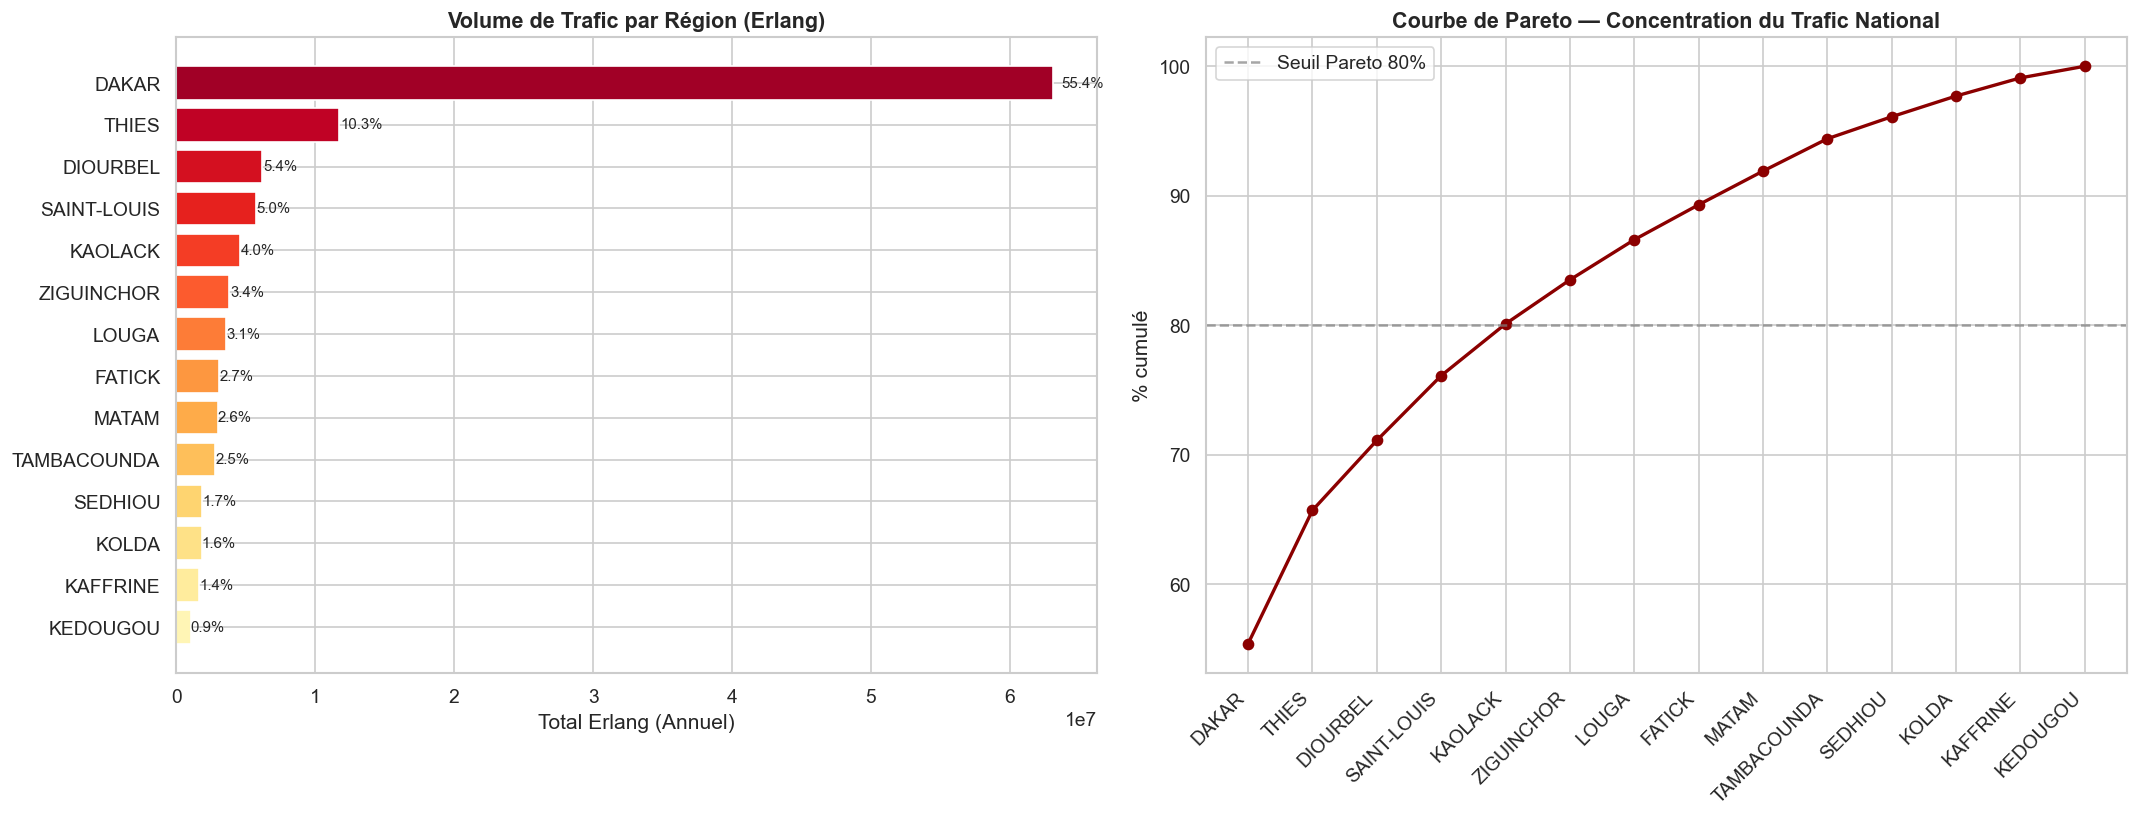

In [11]:
# ════════════════════════════════════════════════════════════════
# 4.1 — Classement des 14 Régions
# ════════════════════════════════════════════════════════════════

if 'df_graph' in dir():
    region_ranking = df_graph.groupby('region').agg(
        nb_arrondissements=('arr_id', 'count'),
        total_erlang=('total_strength_erlang', 'sum'),
        max_betweenness=('betweenness_centrality', 'max'),
        mean_betweenness=('betweenness_centrality', 'mean'),
        mean_entropy=('entropy_temporal', 'mean'),
        total_connectivity=('connectivity', 'sum'),
        top_arrondissement=('total_strength_erlang', 'idxmax')
    ).sort_values('total_erlang', ascending=False)
    
    region_ranking['part_nationale_%'] = (region_ranking['total_erlang'] / 
                                          region_ranking['total_erlang'].sum() * 100).round(1)
    region_ranking['cumul_%'] = region_ranking['part_nationale_%'].cumsum()
    
    # Nom de l'arrondissement top
    idx_to_name = dict(zip(df_graph.index, df_graph['arrondissement']))
    region_ranking['top_arrondissement'] = region_ranking['top_arrondissement'].map(idx_to_name)
    
    print('📊 CLASSEMENT DES 14 RÉGIONS DU SÉNÉGAL PAR VOLUME DE TRAFIC (Annuel)')
    print('=' * 120)
    display(region_ranking.style.format({
        'total_erlang': '{:,.0f}',
        'max_betweenness': '{:.4f}',
        'mean_betweenness': '{:.4f}',
        'mean_entropy': '{:.2f}',
        'part_nationale_%': '{:.1f}',
        'cumul_%': '{:.1f}'
    }).background_gradient(cmap='YlOrRd', subset=['total_erlang', 'part_nationale_%']))
    
    # Visualisation
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    
    ax = axes[0]
    colors = sns.color_palette('YlOrRd_r', n_colors=len(region_ranking))
    ax.barh(region_ranking.index, region_ranking['total_erlang'], color=colors)
    ax.set_xlabel('Total Erlang (Annuel)')
    ax.set_title('Volume de Trafic par Région (Erlang)', fontweight='bold')
    ax.invert_yaxis()
    for i, (_, row) in enumerate(region_ranking.iterrows()):
        ax.text(row['total_erlang'] * 1.01, i, f"{row['part_nationale_%']}%", va='center', fontsize=9)
    
    ax = axes[1]
    ax.plot(range(len(region_ranking)), region_ranking['cumul_%'].values, 'o-', color='darkred', linewidth=2)
    ax.axhline(y=80, color='gray', linestyle='--', alpha=0.7, label='Seuil Pareto 80%')
    ax.set_xticks(range(len(region_ranking)))
    ax.set_xticklabels(region_ranking.index, rotation=45, ha='right')
    ax.set_ylabel('% cumulé')
    ax.set_title('Courbe de Pareto — Concentration du Trafic National', fontweight='bold')
    ax.legend()
    
    plt.tight_layout()
    plt.show()

📊 CLASSEMENT DES DÉPARTEMENTS PAR RÉGION


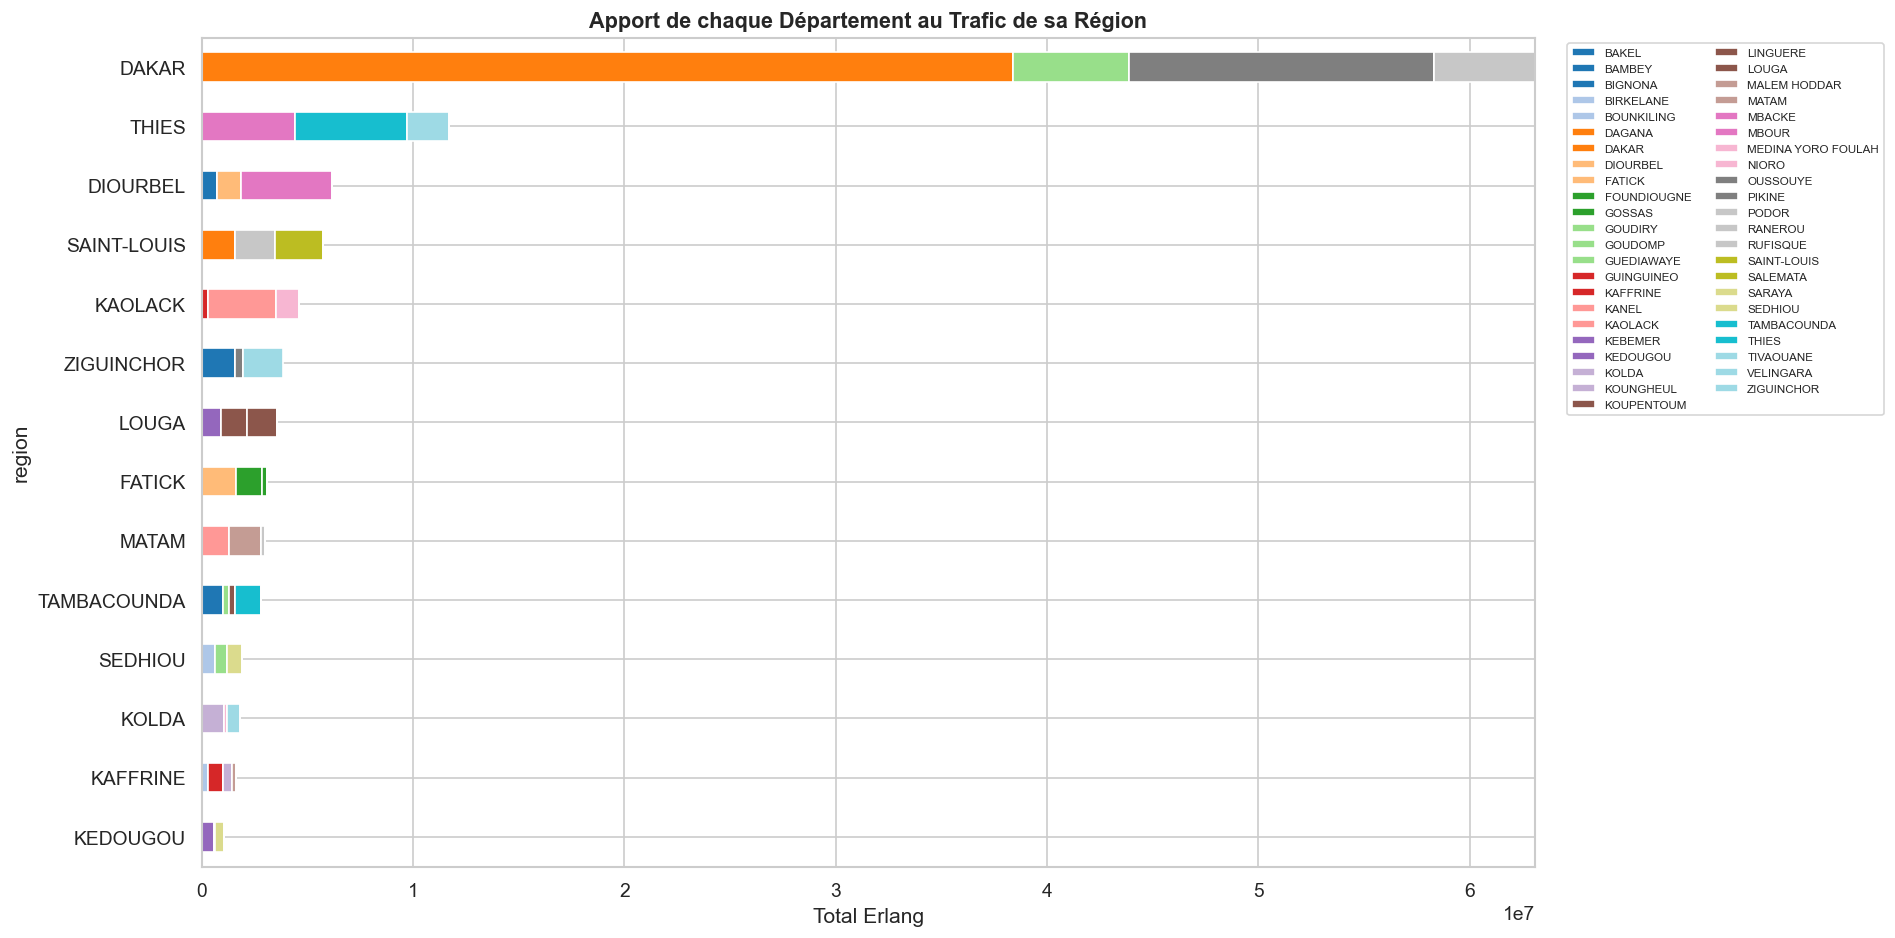

In [12]:
# ════════════════════════════════════════════════════════════════
# 4.2 — Drill-Down : Classement des Départements et
#        Arrondissements à l'intérieur de chaque Région
# ════════════════════════════════════════════════════════════════

if 'df_graph' in dir():
    dept_ranking = df_graph.groupby(['region', 'department']).agg(
        nb_arr=('arr_id', 'count'),
        total_erlang=('total_strength_erlang', 'sum'),
        mean_betweenness=('betweenness_centrality', 'mean'),
        mean_entropy=('entropy_temporal', 'mean'),
    ).sort_values(['region', 'total_erlang'], ascending=[True, False])
    
    # Part du département dans sa région
    region_totals = dept_ranking.groupby(level=0)['total_erlang'].transform('sum')
    dept_ranking['part_region_%'] = (dept_ranking['total_erlang'] / region_totals * 100).round(1)
    
    print('📊 CLASSEMENT DES DÉPARTEMENTS PAR RÉGION')
    print('=' * 100)
    display(dept_ranking.style.format({
        'total_erlang': '{:,.0f}',
        'mean_betweenness': '{:.4f}',
        'mean_entropy': '{:.2f}',
        'part_region_%': '{:.1f}'
    }).background_gradient(cmap='Blues', subset=['total_erlang']))
    
    # Visualisation : barres empilées par région
    fig, ax = plt.subplots(figsize=(16, 8))
    pivot = dept_ranking.reset_index().pivot_table(
        index='region', columns='department', values='total_erlang', fill_value=0
    )
    pivot = pivot.loc[region_ranking.index]  # Même ordre que le classement
    pivot.plot(kind='barh', stacked=True, ax=ax, cmap='tab20', legend=False)
    ax.set_xlabel('Total Erlang')
    ax.set_title('Apport de chaque Département au Trafic de sa Région', fontweight='bold')
    ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()

In [13]:
# ════════════════════════════════════════════════════════════════
# 4.3 — Classement Final des 123 Arrondissements
#        (Tableau complet pour export et décision)
# ════════════════════════════════════════════════════════════════

if 'df_graph' in dir():
    # Calcul du déséquilibre directionnel
    df_graph['desequilibre'] = (abs(df_graph['in_strength_erlang'] - df_graph['out_strength_erlang']) / 
                                 df_graph['total_strength_erlang'].clip(lower=1e-6)).round(4)
    
    # Part nationale
    total_national = df_graph['total_strength_erlang'].sum()
    df_graph['part_nationale_%'] = (df_graph['total_strength_erlang'] / total_national * 100).round(2)
    df_graph_sorted = df_graph.sort_values('total_strength_erlang', ascending=False)
    df_graph_sorted['cumul_%'] = df_graph_sorted['part_nationale_%'].cumsum().round(2)
    
    display_cols = ['arrondissement', 'department', 'region', 'total_strength_erlang',
                    'in_strength_erlang', 'out_strength_erlang', 'desequilibre',
                    'betweenness_centrality', 'eigenvector_centrality', 'entropy_temporal',
                    'connectivity', 'part_nationale_%', 'cumul_%']
    
    print('📊 CLASSEMENT COMPLET DES 123 ARRONDISSEMENTS (Top 30)')
    print('=' * 140)
    display(df_graph_sorted[display_cols].head(30).style.format({
        'total_strength_erlang': '{:,.0f}',
        'in_strength_erlang': '{:,.0f}',
        'out_strength_erlang': '{:,.0f}',
        'desequilibre': '{:.3f}',
        'betweenness_centrality': '{:.4f}',
        'eigenvector_centrality': '{:.4f}',
        'entropy_temporal': '{:.2f}',
        'part_nationale_%': '{:.2f}',
        'cumul_%': '{:.2f}'
    }).background_gradient(cmap='YlOrRd', subset=['total_strength_erlang', 'betweenness_centrality']))

📊 CLASSEMENT COMPLET DES 123 ARRONDISSEMENTS (Top 30)


,arrondissement,department,region,total_strength_erlang,in_strength_erlang,out_strength_erlang,desequilibre,betweenness_centrality,eigenvector_centrality,entropy_temporal,connectivity,part_nationale_%,cumul_%
0,PARCELLES ASSAINIES,DAKAR,DAKAR,"10,597,065","4,970,546","5,626,519",0.062,0.7832,0.4479,4.17,244,9.30,9.30
2,GRAND DAKAR,DAKAR,DAKAR,"10,147,483","4,655,898","5,491,585",0.082,0.0833,0.4537,4.19,244,8.91,18.21
3,DAKAR PLATEAU,DAKAR,DAKAR,"9,552,322","4,197,808","5,354,514",0.121,0.0969,0.4111,4.16,244,8.39,26.60
1,ALMADIES,DAKAR,DAKAR,"8,103,165","3,676,380","4,426,785",0.093,0.0000,0.3874,4.21,244,7.11,33.71
4,GUEDIAWAYE,GUEDIAWAYE,DAKAR,"5,492,197","2,768,998","2,723,199",0.008,0.0001,0.2490,4.16,244,4.82,38.53
6,THIAROYE,PIKINE,DAKAR,"5,134,772","2,524,868","2,609,904",0.017,0.0084,0.2020,4.17,244,4.51,43.04
5,PIKINE DAGOUDANE,PIKINE,DAKAR,"4,912,585","2,416,472","2,496,113",0.016,0.0000,0.2070,4.16,244,4.31,47.35
7,NIAYES,PIKINE,DAKAR,"4,380,060","2,330,998","2,049,062",0.064,0.0005,0.1874,4.14,244,3.85,51.20
24,NDAME,MBACKE,DIOURBEL,"4,142,417","1,510,416","2,632,001",0.271,0.3502,0.0960,3.79,244,3.64,54.84
11,SINDIA,MBOUR,THIES,"3,407,109","1,668,484","1,738,625",0.021,0.0484,0.1204,4.17,244,2.99,57.83


---
### E — Export du DataFrame ML-Ready

Nous assemblons le DataFrame final contenant toutes les features nécessaires pour les algorithmes de Machine Learning et de Deep Learning.

In [14]:
# ════════════════════════════════════════════════════════════════
# 5.1 — DataFrame des Arrondissements (Nœuds du graphe)
# ════════════════════════════════════════════════════════════════

if 'df_graph_sorted' in dir():
    out_arr = OUT_DIR / 'arrondissements_scores_final.csv'
    df_graph_sorted.to_csv(out_arr, index=False)
    print(f'✅ Arrondissements scorés exportés : {out_arr}')
    print(f'   {len(df_graph_sorted)} lignes × {len(df_graph_sorted.columns)} colonnes')

✅ Arrondissements scorés exportés : ..\outputs\preprocessing_v2\arrondissements_scores_final.csv
   123 lignes × 14 colonnes


In [15]:
# ════════════════════════════════════════════════════════════════
# 5.2 — DataFrame des Corridors (Arêtes du graphe)
#
# Ce DataFrame contient, pour chaque paire ordonnée (A → B) :
#   - Le volume Erlang (voix) et λ (SMS)
#   - L'indice de mobilité pendulaire
#   - Les transitions physiques SET3
#   - Un flag de qualité multi-source
# ════════════════════════════════════════════════════════════════

if 'df_set1_annual' in dir() and 'df_set3_annual' in dir():
    # Fusion SET1 + SET3
    df_corridors = df_set1_annual.merge(
        df_set3_annual[['origin_arr', 'dest_arr', 'transition_count', 'unique_users', 
                         'morning_transitions', 'evening_transitions', 'pmi_physical']],
        on=['origin_arr', 'dest_arr'],
        how='outer',
        indicator=True
    )
    
    # Flag de qualité
    df_corridors['quality_flag'] = df_corridors['_merge'].map({
        'both': 'CONFIRMÉ_MULTI_SOURCE',
        'left_only': 'SET1_SEUL',
        'right_only': 'SET3_SEUL'
    })
    df_corridors.drop(columns=['_merge'], inplace=True)
    
    # Enrichir avec les noms
    df_corridors['origin_name'] = df_corridors['origin_arr'].map(
        lambda x: arr_to_meta.get(int(x) if pd.notna(x) else 0, {}).get('arrondissement', '?'))
    df_corridors['dest_name'] = df_corridors['dest_arr'].map(
        lambda x: arr_to_meta.get(int(x) if pd.notna(x) else 0, {}).get('arrondissement', '?'))
    
    # Tri par Erlang
    df_corridors = df_corridors.sort_values('voice_erlang', ascending=False, na_position='last')
    
    out_corr = OUT_DIR / 'corridors_ml_ready.csv'
    df_corridors.to_csv(out_corr, index=False)
    
    print(f'✅ Corridors ML-Ready exportés : {out_corr}')
    print(f'   {len(df_corridors):,} corridors')
    print(f'\n   Répartition des flags de qualité :')
    print(df_corridors['quality_flag'].value_counts().to_string())
    
    print(f'\n📊 TOP 20 CORRIDORS PAR VOLUME ERLANG :')
    display(df_corridors[['origin_name', 'origin_region', 'dest_name', 'dest_region',
                           'voice_erlang', 'sms_lambda', 'pmi_erlang', 
                           'transition_count', 'pmi_physical', 'quality_flag']].head(20))

✅ Corridors ML-Ready exportés : ..\outputs\preprocessing_v2\corridors_ml_ready.csv
   15,129 corridors

   Répartition des flags de qualité :
quality_flag
CONFIRMÉ_MULTI_SOURCE    12888
SET1_SEUL                 2241
SET3_SEUL                    0

📊 TOP 20 CORRIDORS PAR VOLUME ERLANG :


,origin_name,origin_region,dest_name,dest_region,voice_erlang,sms_lambda,pmi_erlang,transition_count,pmi_physical,quality_flag
372,DAKAR PLATEAU,DAKAR,DAKAR PLATEAU,DAKAR,2.310765e+06,56739.381097,298246.997475,NaN,NaN,SET1_SEUL
0,PARCELLES ASSAINIES,DAKAR,PARCELLES ASSAINIES,DAKAR,2.119166e+06,53363.696364,169735.135836,NaN,NaN,SET1_SEUL
248,GRAND DAKAR,DAKAR,GRAND DAKAR,DAKAR,1.902582e+06,50271.925837,184463.030286,NaN,NaN,SET1_SEUL
124,ALMADIES,DAKAR,ALMADIES,DAKAR,1.633976e+06,46693.620494,154352.549992,NaN,NaN,SET1_SEUL
1364,SINDIA,THIES,SINDIA,THIES,1.603274e+06,19023.518626,195879.783315,NaN,NaN,SET1_SEUL
2976,NDAME,DIOURBEL,NDAME,DIOURBEL,1.468359e+06,3973.529957,236848.024723,NaN,NaN,SET1_SEUL
8928,RAO,SAINT-LOUIS,RAO,SAINT-LOUIS,1.008162e+06,24958.398869,108256.021672,NaN,NaN,SET1_SEUL
496,GUEDIAWAYE,DAKAR,GUEDIAWAYE,DAKAR,9.759674e+05,25656.989121,73427.133324,NaN,NaN,SET1_SEUL
6572,KOUMBAL,KAOLACK,KOUMBAL,KAOLACK,9.369701e+05,7579.747501,106326.595015,NaN,NaN,SET1_SEUL
371,DAKAR PLATEAU,DAKAR,GRAND DAKAR,DAKAR,9.289049e+05,18848.240066,114744.100553,1343237.0,142138.0,CONFIRMÉ_MULTI_SOURCE


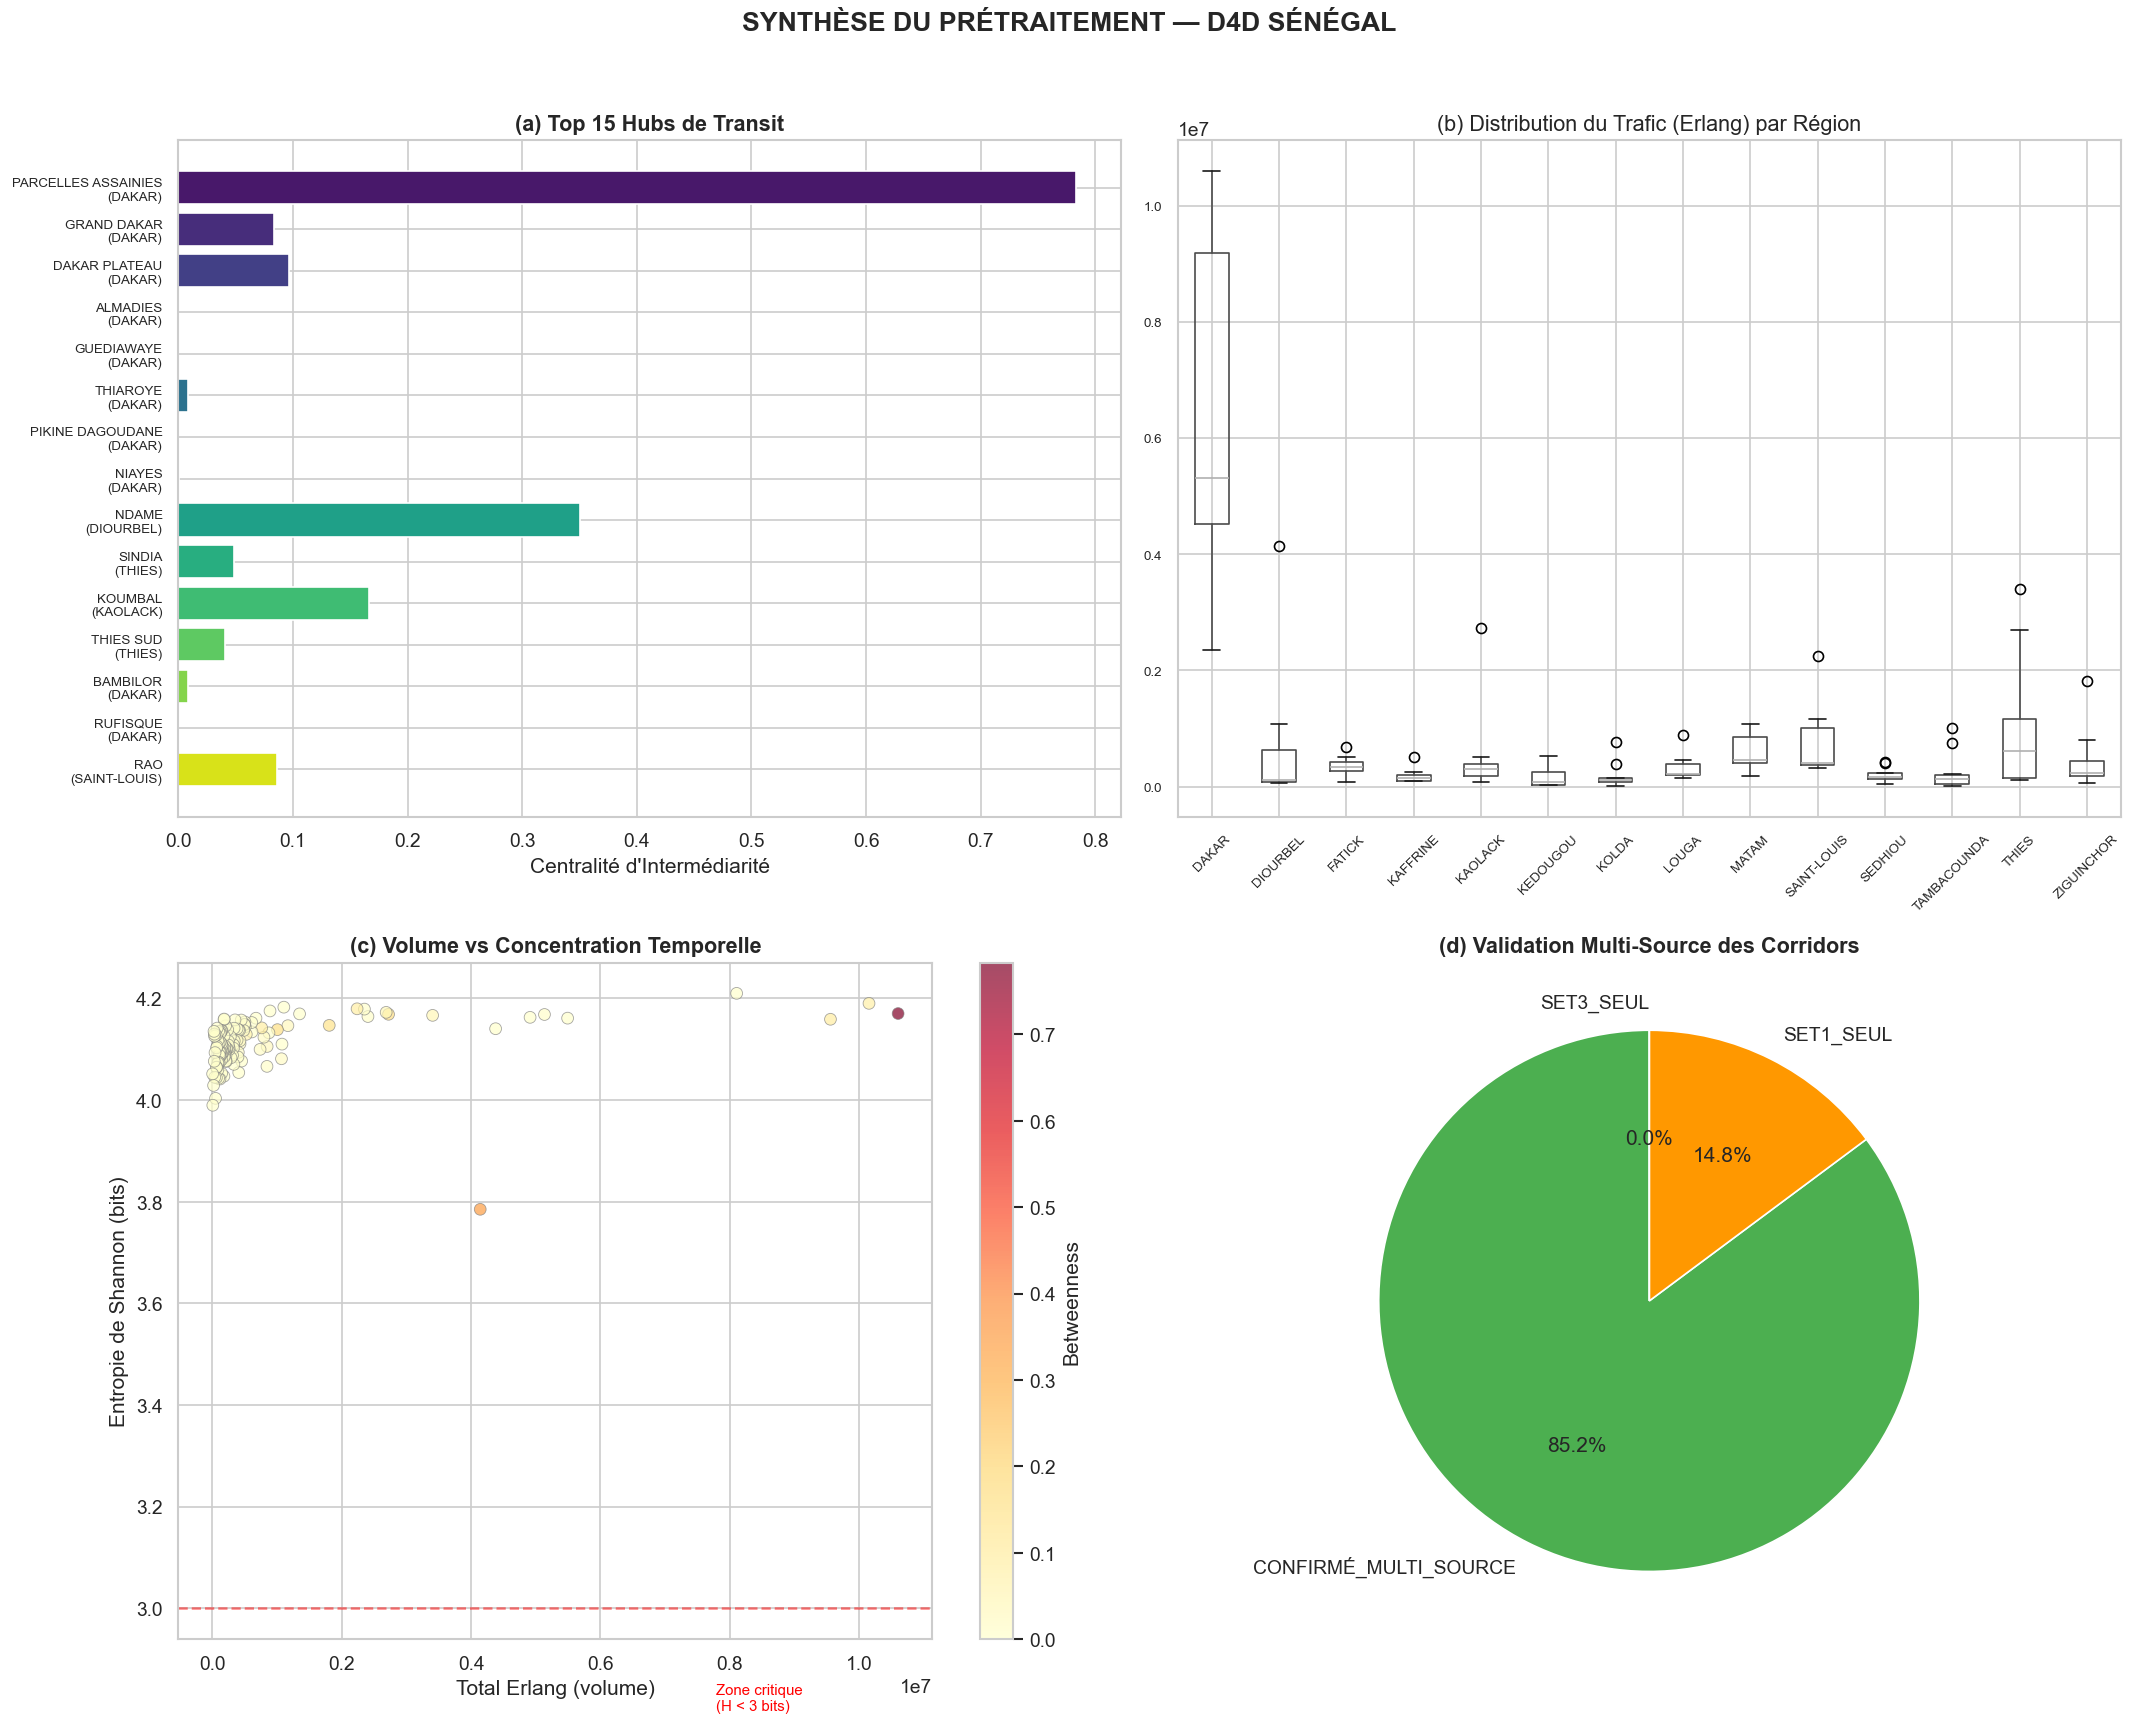

In [16]:
# ════════════════════════════════════════════════════════════════
# 5.3 — Visualisations Finales de Synthèse
# ════════════════════════════════════════════════════════════════

if 'df_graph_sorted' in dir() and 'df_corridors' in dir():
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    
    # (a) Top 15 Arrondissements par Betweenness
    ax = axes[0, 0]
    top = df_graph_sorted.head(15)
    labels = top['arrondissement'] + '\n(' + top['region'] + ')'
    ax.barh(range(len(top)), top['betweenness_centrality'], color=sns.color_palette('viridis', 15))
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Centralité d\'Intermédiarité')
    ax.set_title('(a) Top 15 Hubs de Transit', fontweight='bold')
    ax.invert_yaxis()
    
    # (b) Distribution des Erlangs par région
    ax = axes[0, 1]
    df_graph_sorted.boxplot(column='total_strength_erlang', by='region', ax=ax, rot=45, fontsize=8)
    ax.set_title('(b) Distribution du Trafic (Erlang) par Région', fontweight='bold')
    ax.set_xlabel('')
    plt.sca(ax)
    plt.title('(b) Distribution du Trafic (Erlang) par Région')
    
    # (c) Entropie vs Volume (scatter)
    ax = axes[1, 0]
    sc = ax.scatter(df_graph_sorted['total_strength_erlang'], 
                     df_graph_sorted['entropy_temporal'],
                     c=df_graph_sorted['betweenness_centrality'],
                     cmap='YlOrRd', s=50, alpha=0.7, edgecolors='gray', linewidth=0.5)
    plt.colorbar(sc, ax=ax, label='Betweenness')
    ax.set_xlabel('Total Erlang (volume)')
    ax.set_ylabel('Entropie de Shannon (bits)')
    ax.set_title('(c) Volume vs Concentration Temporelle', fontweight='bold')
    ax.axhline(y=3.0, color='red', linestyle='--', alpha=0.5)
    ax.text(ax.get_xlim()[1] * 0.7, 2.8, 'Zone critique\n(H < 3 bits)', color='red', fontsize=9)
    
    # (d) Qualité des corridors
    ax = axes[1, 1]
    quality_counts = df_corridors['quality_flag'].value_counts()
    colors_q = {'CONFIRMÉ_MULTI_SOURCE': '#4caf50', 'SET1_SEUL': '#ff9800', 'SET3_SEUL': '#2196f3'}
    ax.pie(quality_counts, labels=quality_counts.index, autopct='%1.1f%%',
           colors=[colors_q.get(x, 'gray') for x in quality_counts.index], startangle=90)
    ax.set_title('(d) Validation Multi-Source des Corridors', fontweight='bold')
    
    plt.suptitle('SYNTHÈSE DU PRÉTRAITEMENT — D4D SÉNÉGAL', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## PARTIE 3 : ANALYSE GLOBALE SUR L'ANNÉE 2013

In [1]:
import pandas as pd

# Chargement
df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")

# CRÉATION D'UN DICTIONNAIRE POUR RECHERCHE ULTRA-RAPIDE (O(1))
# Au lieu d'utiliser df_stations.loc dans la boucle, on utilisera ce dictionnaire natif
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

# On garde le nombre d'arrondissements pour la taille de la matrice
nb_arr = len(df_regions)
print(f"Nombre de régions: {nb_arr}")

# Affichage de contrôle
display(df_stations.head())

Nombre de régions: 123


,site_id,arr_id,lon,lat
0,1,2,-17.525142,14.746832
1,2,2,-17.524360,14.747434
2,3,2,-17.522576,14.745198
3,4,2,-17.516398,14.746730
4,5,2,-17.512870,14.740658


### A — IMPLÉMENTATION DE LA MATRICE D'ORIGINE-DESTINATION DES FLUX DE MOBILITÉ INTER-ARRONDISSEMENTS

Ainsi, nous avons orchestrer l'extraction et l'agrégation itérative des matrices de flux de mobilité inter-arrondissements à partir des traces de télécommunications brutes (SET2), en s'appuyant sur un mécanisme robuste de reprise sur panne (checkpointing). Dans un premier temps, il réalise un alignement géospatial en convertissant les identifiants techniques des antennes téléphoniques (site_id) en codes administratifs d'arrondissements grâce au dictionnaire pivot **SITE_ARR_LONLAT.CSV**, tout en calibrant les dimensions de la matrice de transition via le référentiel national **SENEGAL_ARR_V2.csv**. Le cœur de l'algorithme parcourt ensuite chronologiquement les fichiers de données d'appels, reconstitue la trajectoire séquentielle de chaque utilisateur unique à l'aide d'un dictionnaire de positions éphémères, comptabilise les transitions effectives entre arrondissements distincts via un objet **Counter**, puis incrémente et sauvegarde de manière persistante la matrice d'origine-destination finale.

In [2]:
import csv
import gc
from pathlib import Path
from collections import Counter
import pandas as pd
from tqdm import tqdm # Version standard en mode texte

# 1. Configuration et Dictionnaire
dossier_source = Path('../SET2/')
dossier_dest = Path('./Deplacement/')
dossier_dest.mkdir(exist_ok=True)

df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")
nb_arr = len(df_regions)

tous_fichiers_csv = sorted([f.name for f in dossier_source.glob('SET2*.CSV')])

# 2. Gestion de la reprise (Checkpointing)
checkpoints = sorted([f for f in dossier_dest.glob('Deplacements_arrondissement-P*.csv')])

if checkpoints:
    dernier_checkpoint = checkpoints[-1]
    matrice = pd.read_csv(dernier_checkpoint)
    dernier_p = dernier_checkpoint.stem.split('-')[-1] 
    print(f"Reprise détectée ! Chargement du checkpoint : {dernier_checkpoint.name}")
    fichiers_a_traiter = [
        f for f in tous_fichiers_csv 
        if f.split('_')[-1].split('.')[0] > dernier_p
    ]
else:
    print("Aucune sauvegarde trouvée. Démarrage depuis le début.")
    matrice = pd.DataFrame(0, index=range(nb_arr), columns=range(nb_arr))
    fichiers_a_traiter = tous_fichiers_csv

total_fichiers = len(fichiers_a_traiter)
print(f"{total_fichiers} fichier(s) restant(s) à traiter.")
print("-" * 50)


# 3. Boucle principale
# On utilise enumerate pour afficher proprement l'avancement des fichiers (ex: [1/10])
for idx, nom_fichier in enumerate(fichiers_a_traiter, 1):
    # Affichage textuel fixe de l'avancement global
    print(f"\n[{idx}/{total_fichiers}] En cours : {nom_fichier} ...")
    
    chemin_fichier = dossier_source / nom_fichier
    derniere_position = {} 
    compteur_deplacements = Counter()
    
    with open(chemin_fichier, mode='r', encoding='utf-8') as fichier:
        
        # Comptage rapide des lignes
        nb_lignes_total = sum(1 for _ in fichier)
        fichier.seek(0)
        
        lecteur = csv.reader(fichier)
        
        # UNE SEULE BARRE : Pas de conflit de position, elle s'effacera proprement à 100%
        for ligne in tqdm(lecteur, total=nb_lignes_total, desc=" -> Progression des lignes", leave=False, mininterval=1.0):
            if len(ligne) < 3: 
                continue
                
            user_id = ligne[0]
            try:
                stationid = int(ligne[2])
            except ValueError:
                continue
            
            arr = dict_stations.get(stationid)
            if arr is None:
                continue
            arr = int(arr)
            
            if user_id in derniere_position:
                origine = derniere_position[user_id]
                compteur_deplacements[(origine - 1, arr - 1)] += 1
            
            derniere_position[user_id] = arr
            
    # 4. Transfert dans la matrice globale
    for (orig, dest), nombre_trajets in compteur_deplacements.items():
        matrice.iloc[orig, dest] += nombre_trajets
        
    partie_nom = nom_fichier.split('_')[-1].split('.')[0] 
    chemin_sauvegarde = dossier_dest / f'Deplacements_arrondissement-{partie_nom}.csv'
    matrice.to_csv(chemin_sauvegarde, index=False)
    
    # Nettoyage
    del compteur_deplacements
    del derniere_position
    gc.collect()

print("\n" + "="*50)
print("Fin totale du traitement ! Tous les fichiers ont été fusionnés.")
display(matrice)

Aucune sauvegarde trouvée. Démarrage depuis le début.
25 fichier(s) restant(s) à traiter.
--------------------------------------------------

[1/25] En cours : SET2_P01.CSV ...



[2/25] En cours : SET2_P02.CSV ...



[3/25] En cours : SET2_P03.CSV ...



[4/25] En cours : SET2_P04.CSV ...



[5/25] En cours : SET2_P05.CSV ...



[6/25] En cours : SET2_P06.CSV ...


... (17 outputs left out)


[24/25] En cours : SET2_P24.CSV ...



[25/25] En cours : SET2_P25.CSV ...



Fin totale du traitement ! Tous les fichiers ont été fusionnés.


,0,1,2,3,4,5,6,7,8,9,...,113,114,115,116,117,118,119,120,121,122
0,100845869,2626522,3337360,1281274,2224608,469444,286709,257046,63239,65338,...,30,62,904,0,140,1557,49,56,442,43
1,2656747,75967506,2706969,2223819,209255,182786,138177,135650,37260,38488,...,11,27,6614,0,37,11181,27,29,2832,25
2,3475526,2697836,94969356,3995123,590539,1092812,475590,266694,104031,83880,...,10,18,498,1,43,1035,29,34,1501,44
3,1311537,2254405,4122922,109816503,416542,494233,395237,326167,104659,85124,...,34,58,516,0,74,797,45,32,341,40
4,2188433,219085,603127,444326,51630183,1810134,215965,688772,34423,40203,...,11,24,657,0,55,694,154,24,1476,103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,1599,11106,1082,899,704,446,395,369,822,450,...,29,121,2533,1,277,10675529,98430,8037,12264,59466
119,70,33,43,53,131,94,69,66,34,48,...,2,3546,66,0,20,98706,3684885,727,700,1168
120,63,20,59,53,38,79,94,24,25,43,...,11,6,14,0,1,7017,718,1211040,185,200
121,406,2774,1540,354,1467,247,66,434,553,34,...,100,796,104505,3,1060,12896,696,253,8107749,61015


### B — VISUALISATION DE LA MATRICE DE FLUX DE MOBILITÉ INTER-ARRONDISSEMENTS

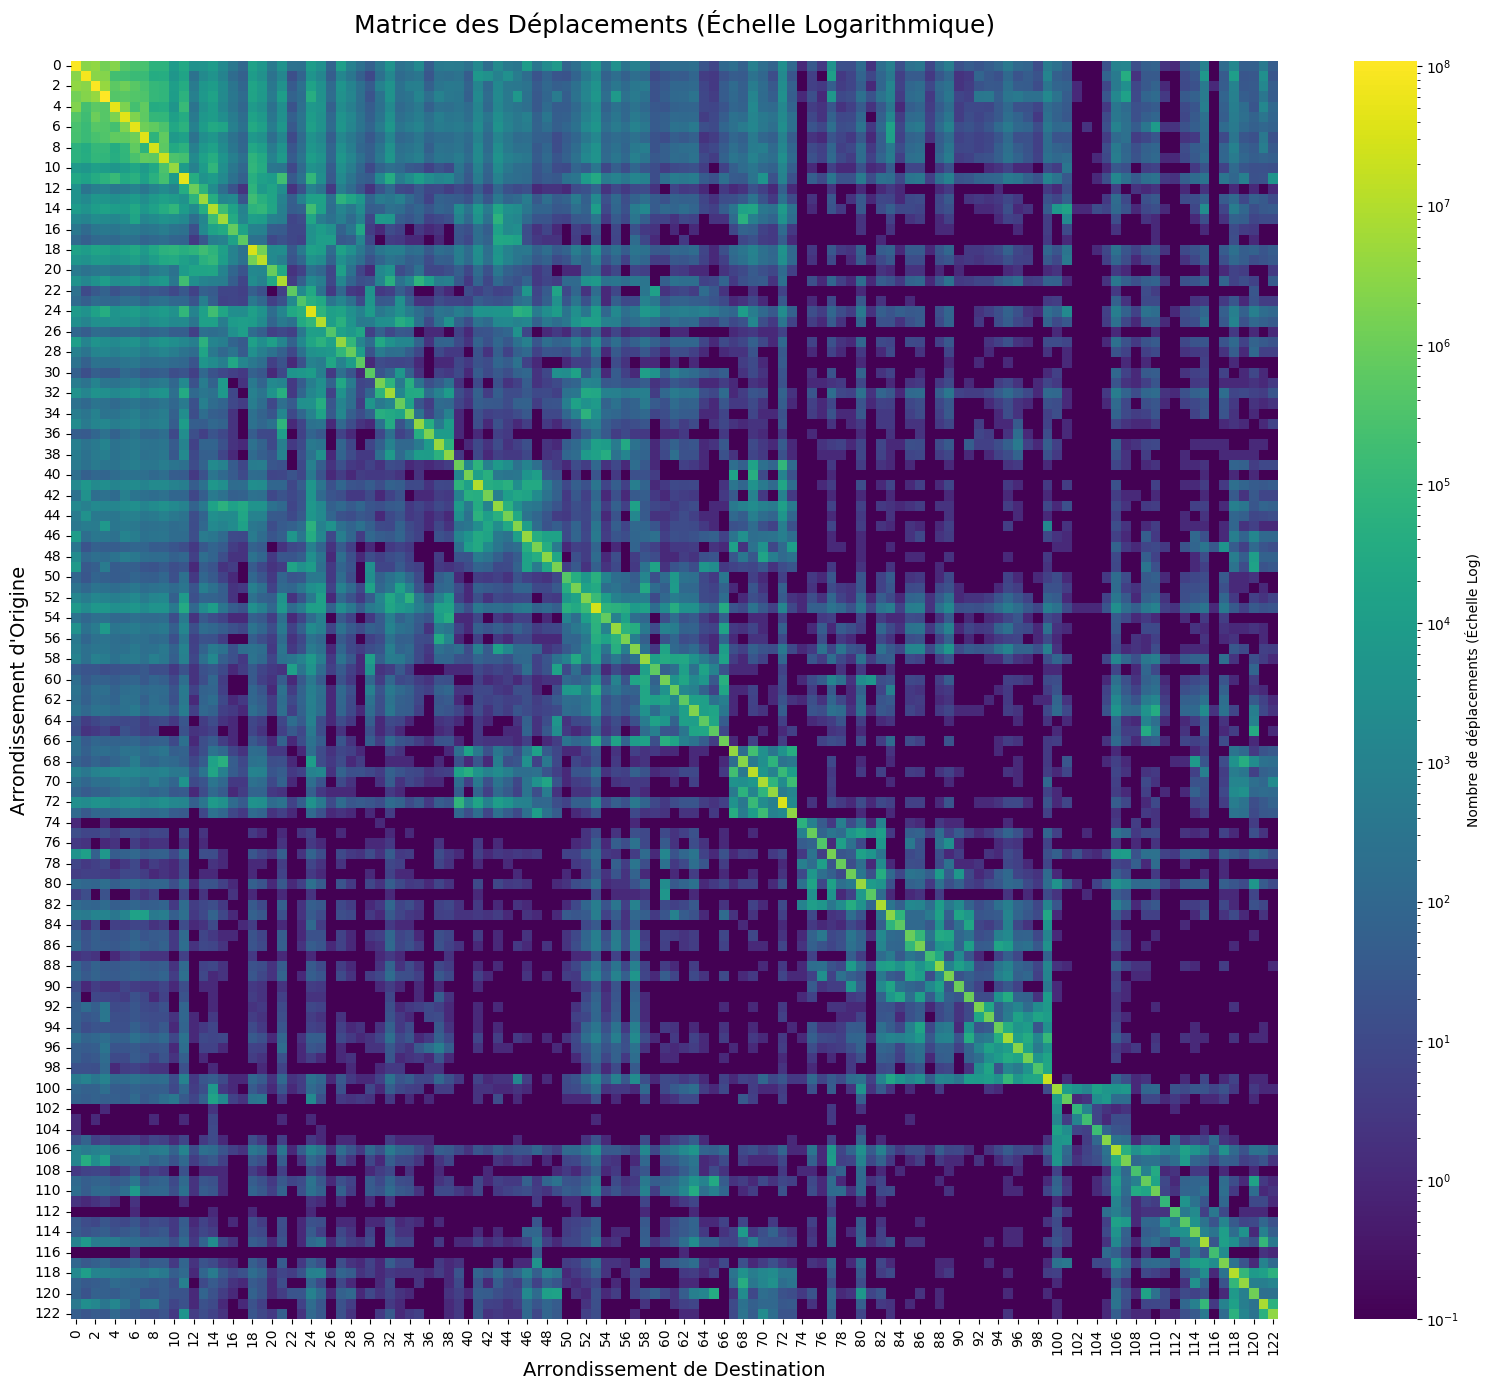

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm # Import pour l'échelle logarithmique

plt.figure(figsize=(16, 14))

# On utilise norm=LogNorm() pour que les petites valeurs (ex: 10 déplacements)
# restent visibles par rapport aux valeurs extrêmes (ex: 100 000 déplacements)
# Note: LogNorm n'aime pas les zéros, on ajoute un très léger bruit (+0.1) aux données vides
sns.heatmap(matrice + 0.1, 
            cmap='viridis',  # 'viridis' offre un excellent contraste (du violet foncé au jaune vif)
            norm=LogNorm(), 
            annot=False,
            cbar_kws={'label': 'Nombre de déplacements (Échelle Log)'})

plt.title("Matrice des Déplacements (Échelle Logarithmique)", fontsize=18, pad=20)
plt.xlabel("Arrondissement de Destination", fontsize=14)
plt.ylabel("Arrondissement d'Origine", fontsize=14)

plt.tight_layout()
plt.show()

### C — VISUALISATION DES MATRICES DES DÉPLACEMENTS ENTRE DÉPARTEMENTS ET ENTRE RÉGIONS

Pour le faire, nous nous sommes servi de la matrice préalablement implémentée pour le flux de la mobilité inter-arrondissement en agrégeant à l'échelle de département, puis à l'échelle de région.

✅ Matrices de déplacements (Départements et Régions) sauvegardées en CSV !


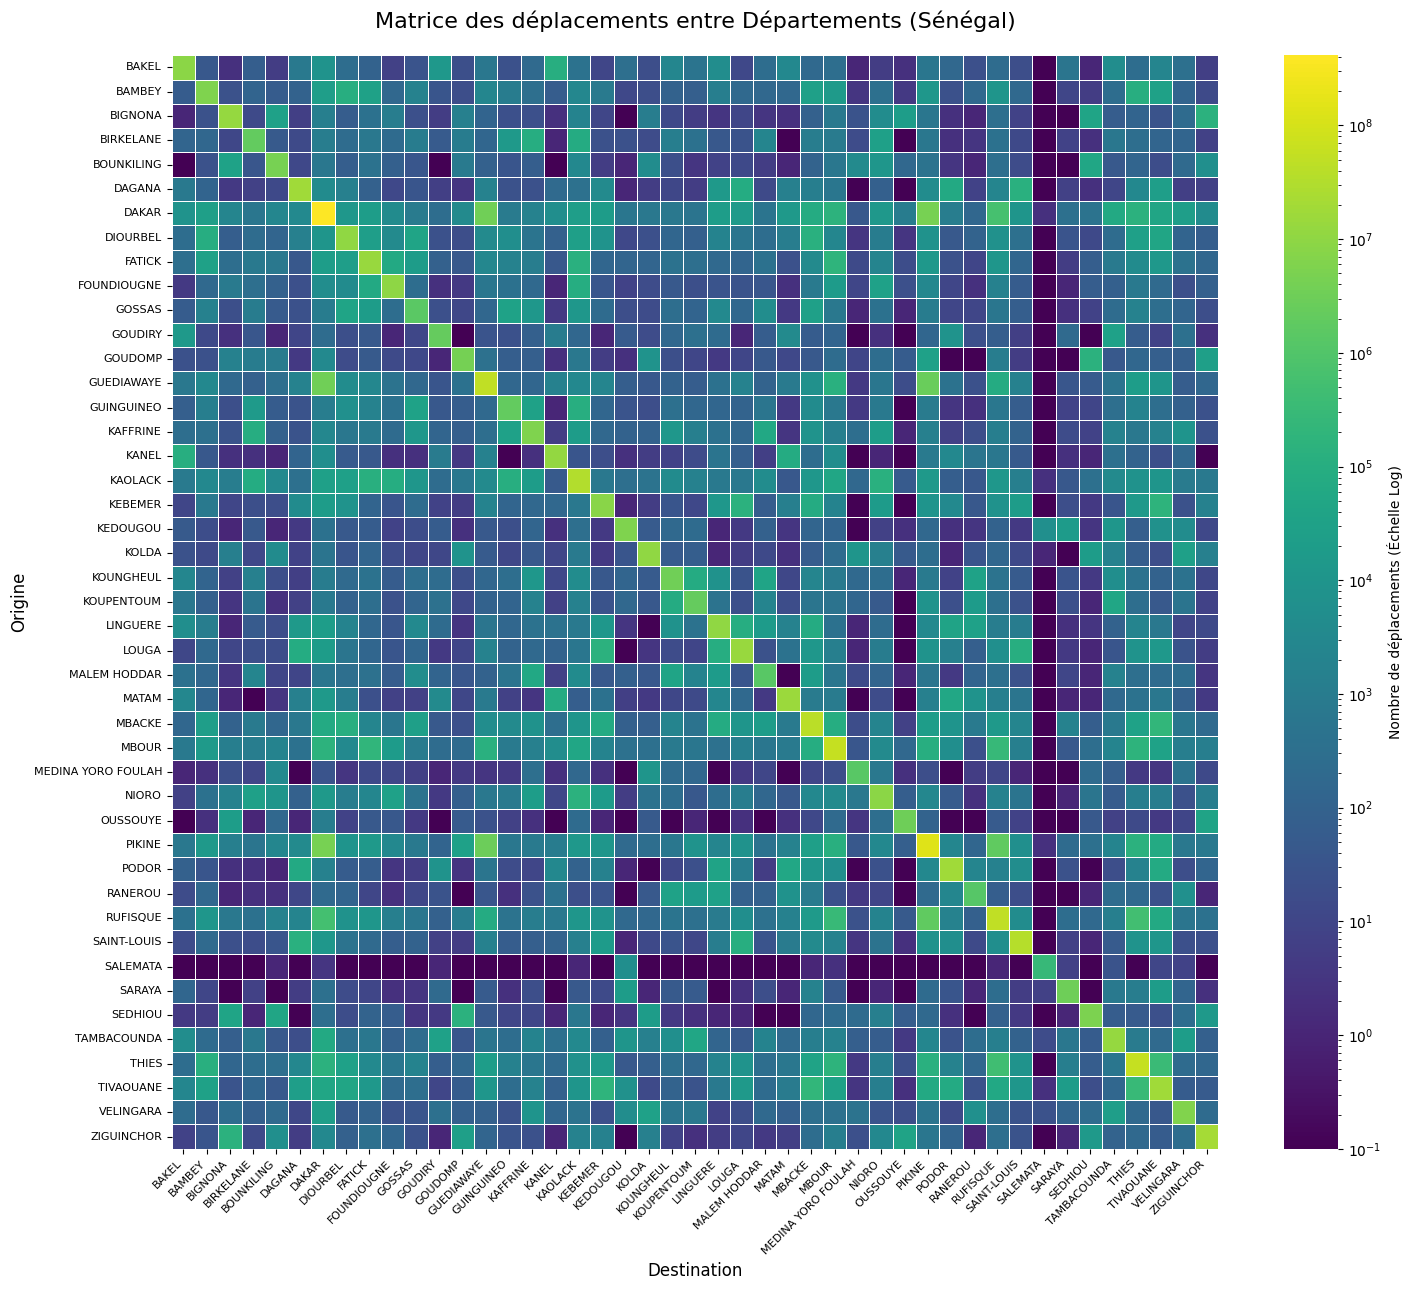

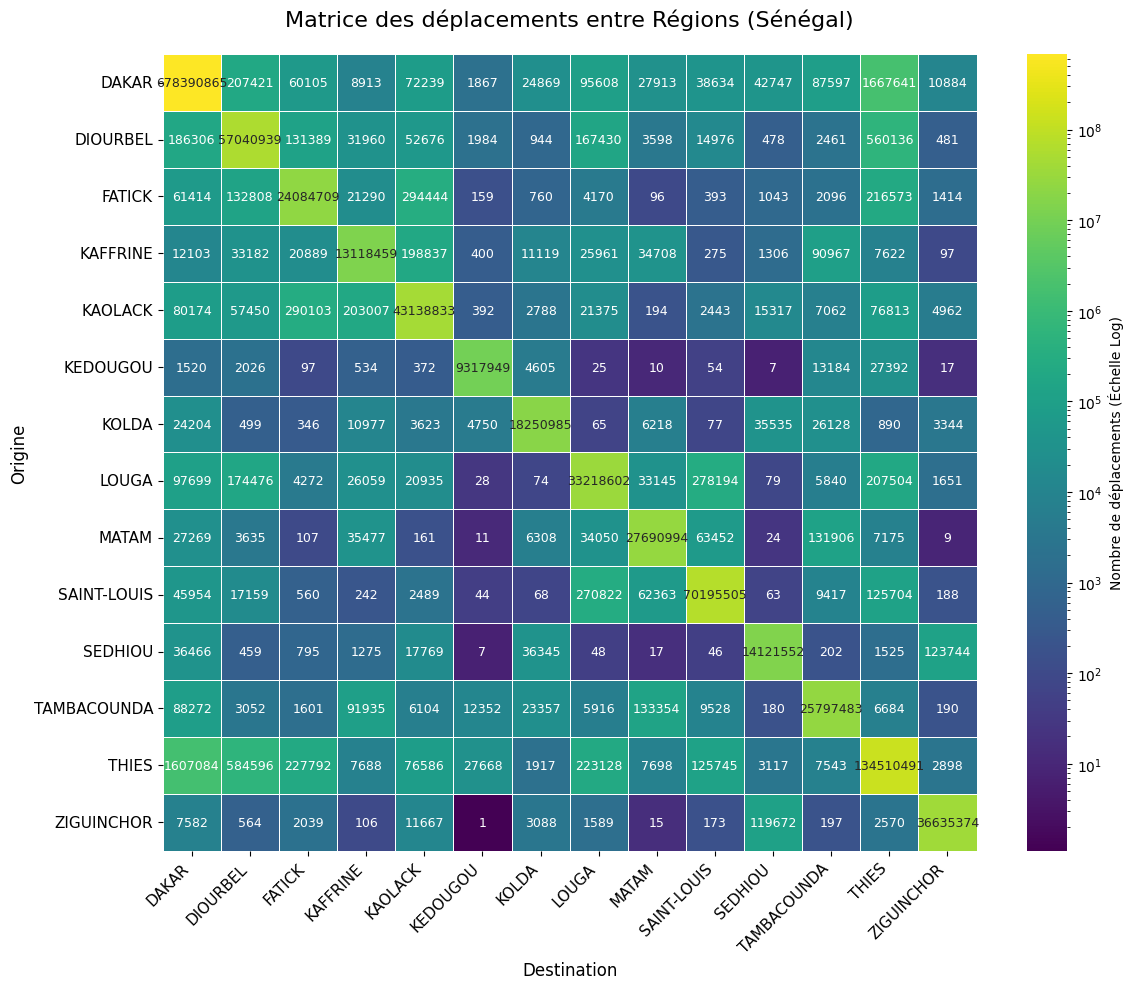

✅ Cartes de chaleur sauvegardées avec succès dans le dossier /Deplacement !


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from pathlib import Path

# 1. Configuration des chemins
dossier_dest = Path('./Deplacement/')
dossier_dest.mkdir(exist_ok=True)

# Charger la table de correspondance (Arrondissements, Départements, Régions)
df_geo = pd.read_csv("SENEGAL_ARR_V2.csv")

# Charger la matrice finale des arrondissements (à adapter selon votre dernier checkpoint)
# On suppose ici qu'elle est chargée en mémoire sous le nom 'matrice'
# Si besoin, décommentez la ligne suivante pour la charger depuis le disque :
# matrice = pd.read_csv(dossier_dest / 'Deplacements_arrondissement-P25.csv')

# ---------------------------------------------------------------------------
# 2. PRÉPARATION DU MAPPING (Rappel : index i = ARR_ID i+1)
# ---------------------------------------------------------------------------
# On crée une liste ordonnée des départements et régions correspondant à chaque index de la matrice
# df_geo['ARR_ID'] - 1 nous donne exactement l'index (0 à 123) dans la matrice
df_geo_triee = df_geo.sort_values(by='ARR_ID').reset_index(drop=True)

liste_departements = df_geo_triee['DEPT'].tolist()
liste_regions = df_geo_triee['REG'].tolist()

# Obtenir la liste unique et triée des départements et régions pour les index des nouvelles matrices
uniques_depts = sorted(list(set(liste_departements)))
uniques_regs = sorted(list(set(liste_regions)))

# ---------------------------------------------------------------------------
# 3. FONCTION DE CORRESPONDANCE ET D'AGRÉGATION (CORRIGÉE SANS WARNING)
# ---------------------------------------------------------------------------
def agreger_matrice(matrice_source, liste_categories, labels_uniques):
    """
    Agrège une matrice d'arrondissements vers une échelle supérieure (Département ou Région)
    Garantie sans FutureWarning avec les versions récentes de Pandas.
    """
    # Étape A : On applique les labels géographiques sur les lignes et les colonnes
    df_temp = pd.DataFrame(matrice_source.values, index=liste_categories, columns=liste_categories)
    
    # Étape B : On somme les lignes qui ont le même nom (Axe des Origines)
    df_somme_lignes = df_temp.groupby(level=0).sum()
    
    # Étape C : Nouvelle méthode recommandée pour sommer les colonnes (Axe des Destinations)
    # On transpose (.T), on groupe par lignes, puis on re-transpose (.T)
    matrice_agregee = df_somme_lignes.T.groupby(level=0).sum().T
    
    # Étape D : On réindexe proprement pour conserver l'ordre alphabétique
    matrice_agregee = matrice_agregee.reindex(index=labels_uniques, columns=labels_uniques).fillna(0).astype(int)
    
    return matrice_agregee

# Calcul des deux nouvelles matrices
matrice_dept = agreger_matrice(matrice, liste_departements, uniques_depts)
matrice_reg = agreger_matrice(matrice, liste_regions, uniques_regs)

# Sauvegarde des fichiers CSV
matrice_dept.to_csv(dossier_dest / 'Deplacements_Departements.csv')
matrice_reg.to_csv(dossier_dest / 'Deplacements_Regions.csv')
print("✅ Matrices de déplacements (Départements et Régions) sauvegardées en CSV !")

# ---------------------------------------------------------------------------
# 4. CRÉATION DES MATRICES DE CONFUSION VISUELLES (HEATMAPS)
# ---------------------------------------------------------------------------
def generer_heatmap(matrice_data, titre, nom_fichier_image, taille_police=10, fig_size=(12, 10), annot=False):
    """
    Génère et sauvegarde une carte de chaleur pour les matrices Origin-Destination
    """
    plt.figure(figsize=fig_size)
    
    # CORRECTION : fmt=".0f" au lieu de "d" pour afficher des flottants sans décimales
    sns.heatmap(matrice_data + 0.1, 
                cmap='viridis', 
                norm=LogNorm(), 
                annot=annot, 
                fmt=".0f", # <-- Modifié ici pour accepter les valeurs converties en float (+0.1)
                annot_kws={"size": taille_police - 2},
                linewidths=0.5,
                cbar_kws={'label': 'Nombre de déplacements (Échelle Log)'})
    
    plt.title(titre, fontsize=16, pad=20)
    plt.xlabel("Destination", fontsize=12)
    plt.ylabel("Origine", fontsize=12)
    plt.xticks(fontsize=taille_police, rotation=45, ha='right')
    plt.yticks(fontsize=taille_police, rotation=0)
    
    plt.tight_layout()
    plt.savefig(dossier_dest / nom_fichier_image, dpi=300)
    plt.show()

# Génération de la Heatmap des Départements (Pas d'annotations textuelles car ~45 départements)
generer_heatmap(matrice_dept, 
                titre="Matrice des déplacements entre Départements (Sénégal)", 
                nom_fichier_image="Matrice_Confusion_Departements.png",
                taille_police=8, 
                fig_size=(15, 13),
                annot=False)

# Génération de la Heatmap des Régions (Avec annotations car seulement 14 régions au Sénégal)
generer_heatmap(matrice_reg, 
                titre="Matrice des déplacements entre Régions (Sénégal)", 
                nom_fichier_image="Matrice_Confusion_Regions.png",
                taille_police=11, 
                fig_size=(12, 10),
                annot=True) # On affiche les chiffres ici !

print("✅ Cartes de chaleur sauvegardées avec succès dans le dossier /Deplacement !")

### D — Analyse des Flux Nets Asymétriques

1. - **le Flux Net**, c'est le "surplus" de population qu'une région aspire par rapport à ce qu'elle renvoie. C'est la foule invisible qui se déplace à sens unique et qui crée une pression énorme sur le réseau à un moment donné. On élimine mathématiquement tous les gens qui font des trajets équilibrés pour ne garder que la force d'attraction brute d'une région sur une autre.

2. Ce que cela nous dit sur l'amélioration des transports au Sénégal. L'extraction de cette information vous donne trois leviers d'action concrets pour améliorer la circulation :
   - **A. Justification des "Voies Réversibles" (Gestion dynamique du trafic)**
     - Si votre code montre un flux net asymétrique gigantesque entre la périphérie (ex: Rufisque ou Pikine) et le centre (Dakar Plateau), cela signifie que le matin, l'autoroute ou les routes nationales vers Dakar sont saturées à 100%, tandis que les voies qui sortent de Dakar sont totalement vides.
     - **La solution concrète :** Au lieu de dépenser des milliards pour construire de nouvelles routes, une gestion dynamique des voies serait appropriée.

   - **B. Dimensionnement et Planification du TER et du BRT**
       - Le flux net vous donne le volume réel de la **demande insatisfaite** à sens unique.
       - **La solution concrète :** Si le flux net entre la banlieue et le centre-ville est de 100 000 personnes par jour, vous pouvez calculer exactement combien de rames de train (TER) ou de bus articulés (BRT) doivent être injectées sur cet axe chaque heure pour absorber ce "surplus" et vider les routes des voitures particulières et des taxis clandestins (clandos).
         
    - **C. Ciblage de la Décentralisation Économique**  
        - Si une région comme Diourbel ou Kaolack affiche un flux net  massif vers Dakar, cela prouve que ces régions souffrent d'un manque cruel d'infrastructures ou d'emplois locaux, ce qui oblige leur population à migrer ou à se déplacer constamment vers la capitale.
          
        - **La seconde solution concrète :** Il faut arrêter de tout construire à Dakar. Si on implante une zone industrielle ou des services publics à Diourbel, on élimine immédiatement ce flux net de X personnes qui surchargent les transports nationaux.

In [11]:
# --- NOUVELLE CELLULE 5 : ANALYSE DES FLUX NETS ASYMÉTRIQUES ---
# Complexité : Ultra-basse, utilise la transposition de matrice instantanée

# 1. Calcul de la différence entre l'aller et le retour (Matrice moins sa transposée)
# Si matrice[A,B] = 50 et matrice[B,A] = 10, alors flux_net[A,B] = 40 et flux_net[B,A] = -40
flux_net = matrice_reg - matrice_reg.T

# 2. Aplatir la matrice pour obtenir une liste de paires
flux_net_flat = flux_net.stack().reset_index()
flux_net_flat.columns = ['Origine', 'Destination', 'Flux Net']

# 3. Ne garder que les flux positifs (les flux négatifs sont juste les retours miroirs)
# On exclut aussi la diagonale (où le flux net est forcément 0)
flux_net_dominants = flux_net_flat[flux_net_flat['Flux Net'] > 0].sort_values(by='Flux Net', ascending=False)

print("TOP 10 DES ASYMÉTRIES DE FLUX (Les vrais aimants économiques) :")
display(flux_net_dominants.head(25).reset_index(drop=True))

TOP 10 DES ASYMÉTRIES DE FLUX (Les vrais aimants économiques) :


,Origine,Destination,Flux Net
0,DAKAR,THIES,60557
1,THIES,DIOURBEL,24460
2,DAKAR,DIOURBEL,21115
3,THIES,LOUGA,15624
4,THIES,FATICK,11219
5,KAOLACK,DAKAR,7935
6,LOUGA,SAINT-LOUIS,7372
7,SAINT-LOUIS,DAKAR,7320
8,LOUGA,DIOURBEL,7046
9,ZIGUINCHOR,KAOLACK,6705


### E — Extraction de l'Autonomie Territoriale (L'analyse de la Diagonale)


- L'autonomie territoriale mesure la part des déplacements qui commencent et se terminent au sein de la même zone (votre fameuse diagonale). C'est le pourcentage de trajets "locaux".

- Ainsi, une région avec un taux d'autonomie très bas (par exemple 20%) signifie que 80% de ses habitants sont obligés de franchir ses frontières chaque jour pour travailler, étudier ou se soigner.

- **Décision concrète :** C'est l'indicateur parfait pour justifier la création de "villes du quart d'heure" ou de pôles de services de proximité. Si vous augmentez l'autonomie d'une zone en y construisant des hôpitaux ou des zones commerciales, vous supprimez physiquement des milliers de voitures qui n'auront plus besoin de prendre les axes inter-régionaux ou départementaux.

In [12]:
# --- EXTRACTION 2 : L'AUTONOMIE TERRITORIALE ---
# Complexité : Minimale, utilise NumPy pour extraire la diagonale instantanément

# 1. Extraction des déplacements internes (la diagonale de la matrice)
deplacements_internes = np.diag(matrice_reg)

# 2. Somme totale des déplacements générés par chaque région (interne + externe)
total_deplacements_region = matrice_reg.sum(axis=1)

# 3. Calcul du taux d'autonomie en %
taux_autonomie = ((deplacements_internes / total_deplacements_region) * 100).round(1)

# 4. Création du DataFrame d'analyse
df_autonomie = pd.DataFrame({
    'Déplacements Internes': deplacements_internes,
    'Total Déplacements': total_deplacements_region,
    'Taux d\'Autonomie (%)': taux_autonomie
}).sort_values(by='Taux d\'Autonomie (%)')

print("🏠 TAUX D'AUTONOMIE DES RÉGIONS (Du plus dépendant au plus autonome) :")
display(df_autonomie)

🏠 TAUX D'AUTONOMIE DES RÉGIONS (Du plus dépendant au plus autonome) :


,Déplacements Internes,Total Déplacements,Taux d'Autonomie (%)
KAFFRINE,13118459,13555925,96.8
FATICK,24084709,24821369,97.0
LOUGA,33218602,34068558,97.5
THIES,134510491,137413951,97.9
DIOURBEL,57040939,58195758,98.0
KAOLACK,43138833,43900913,98.3
TAMBACOUNDA,25797483,26180008,98.5
SEDHIOU,14121552,14340250,98.5
MATAM,27690994,28000578,98.9
SAINT-LOUIS,70195505,70730578,99.2


### F — Le Top 25 des Goulots d'Étranglement (Hors Diagonale)


Ici, on liste de manière brute et indiscutable les 10 trajets spécifiques de point à point (Département A vers Département B) qui enregistrent le plus grand nombre de voyageurs du pays, en excluant les trajets internes.

C'est la feuille de route directe de vos investissements lourds en infrastructures de transport.

- **Décision concrète :** Si l'axe "PIKINE $\rightarrow$ DAKAR" ou "GUEDIAWAYE $\rightarrow$ DAKAR" arrive en position numéro 1 avec des chiffres écrasants, cela prouve mathématiquement que c'est là, et uniquement là, qu'il faut injecter les budgets pour déployer un transport de masse (prolongement d'une ligne de train TER, création d'un couloir de bus rapide BRT, ou création de voies de covoiturage).

In [14]:
# --- EXTRACTION 3 : LES 10 AXES LES PLUS SATURÉS ---
# Complexité : Faible. .stack() convertit le tableau 2D en liste 1D ultra-rapidement.

# 1. On fait une copie pour ne pas abîmer la matrice originale
df_axes = matrice_dept.copy()

# 2. On force la diagonale à 0 pour ignorer les trajets internes et ne garder que les voyages INTER-départements
np.fill_diagonal(df_axes.values, 0)

# 3. On "aplatit" la matrice pour avoir une liste de paires (Origine -> Destination)
liste_flux = df_axes.stack().reset_index()
liste_flux.columns = ['Origine', 'Destination', 'Nombre de Déplacements']

# 4. On trie pour obtenir les 10 axes les plus fréquentés
top_25_axes = liste_flux.sort_values(by='Nombre de Déplacements', ascending=False).head(25).reset_index(drop=True)

print("TOP 25 DES AXES INTER-DÉPARTEMENTAUX LES PLUS SATURÉS DU SÉNÉGAL :")
display(top_25_axes)

TOP 25 DES AXES INTER-DÉPARTEMENTAUX LES PLUS SATURÉS DU SÉNÉGAL :


,Origine,Destination,Nombre de Déplacements
0,DAKAR,PIKINE,4520545
1,PIKINE,DAKAR,4318279
2,GUEDIAWAYE,DAKAR,3454971
3,DAKAR,GUEDIAWAYE,3440944
4,PIKINE,GUEDIAWAYE,2755589
5,GUEDIAWAYE,PIKINE,2714871
6,PIKINE,RUFISQUE,1920828
7,RUFISQUE,PIKINE,1862762
8,DAKAR,RUFISQUE,582019
9,RUFISQUE,DAKAR,576531


### G — Visualisation du Top 10 des Axes Saturs (Graphique d'Impact)


C'est le palmarès des lignes de transport les plus chargées du réseau.

Ce graphique classe par ordre de gravité les liaisons qui saturent notre réseau routier. La première barre rouge foncé représente le goulot d'étranglement numéro un au Sénégal. Vous pouvez constater visuellement l'écart immense entre la première barre et la dixième. Intervenir sur les deux premiers axes de ce graphique permettra de soulager à eux seuls près de [X]% de la congestion inter-départementale du pays. C'est l'outil parfait pour prioriser nos futurs chantiers de transport de masse.

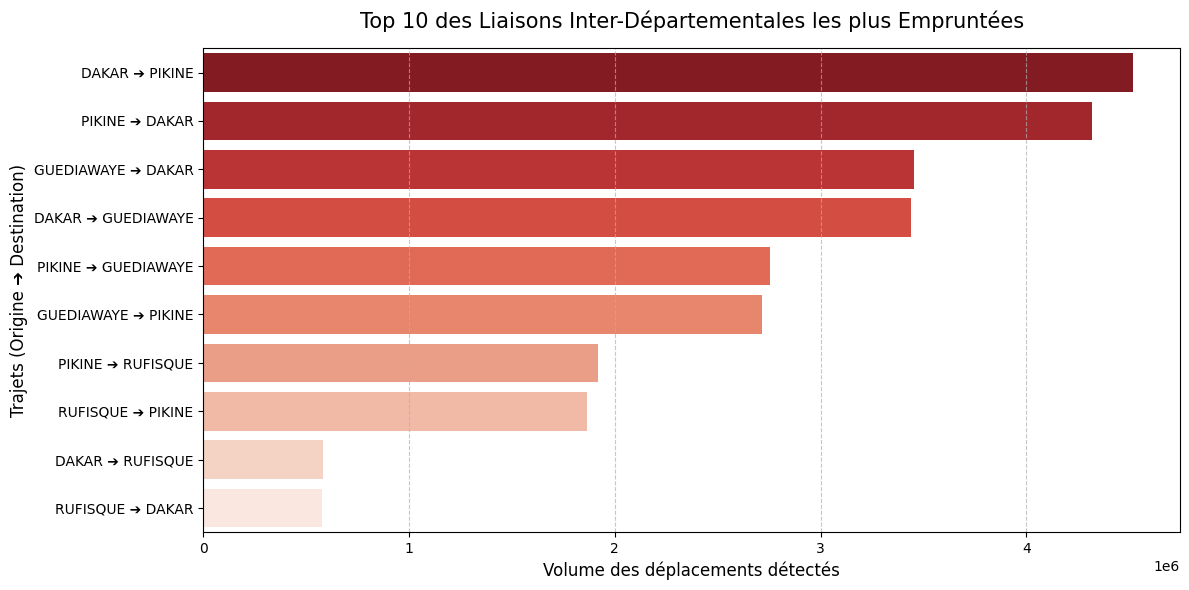

In [16]:
# --- GRAPHIQUE 1 : HISTOGRAMME DES AXES PRIORITAIRES (CORRIGÉ SANS WARNING) ---
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Création d'une étiquette propre pour chaque axe
top_10_axes['Axe'] = top_10_axes['Origine'] + " ➔ " + top_10_axes['Destination']

# Dessin du graphique à barres horizontales
sns.barplot(
    data=top_10_axes, 
    x='Nombre de Déplacements', 
    y='Axe', 
    hue='Axe',          # <-- CORRECTION : On associe la couleur à l'axe
    legend=False,       # <-- CORRECTION : On cache la légende inutile
    palette='Reds_r'    # Dégradé de rouge (le plus saturé en haut)
)

plt.title("Top 10 des Liaisons Inter-Départementales les plus Empruntées", fontsize=15, pad=15)
plt.xlabel("Volume des déplacements détectés", fontsize=12)
plt.ylabel("Trajets (Origine ➔ Destination)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('./Deplacement/Top_10_Axes_Satures.png', dpi=300)
plt.show()

### E — Diagramme de Sankey (Les rivières de flux logistiques)

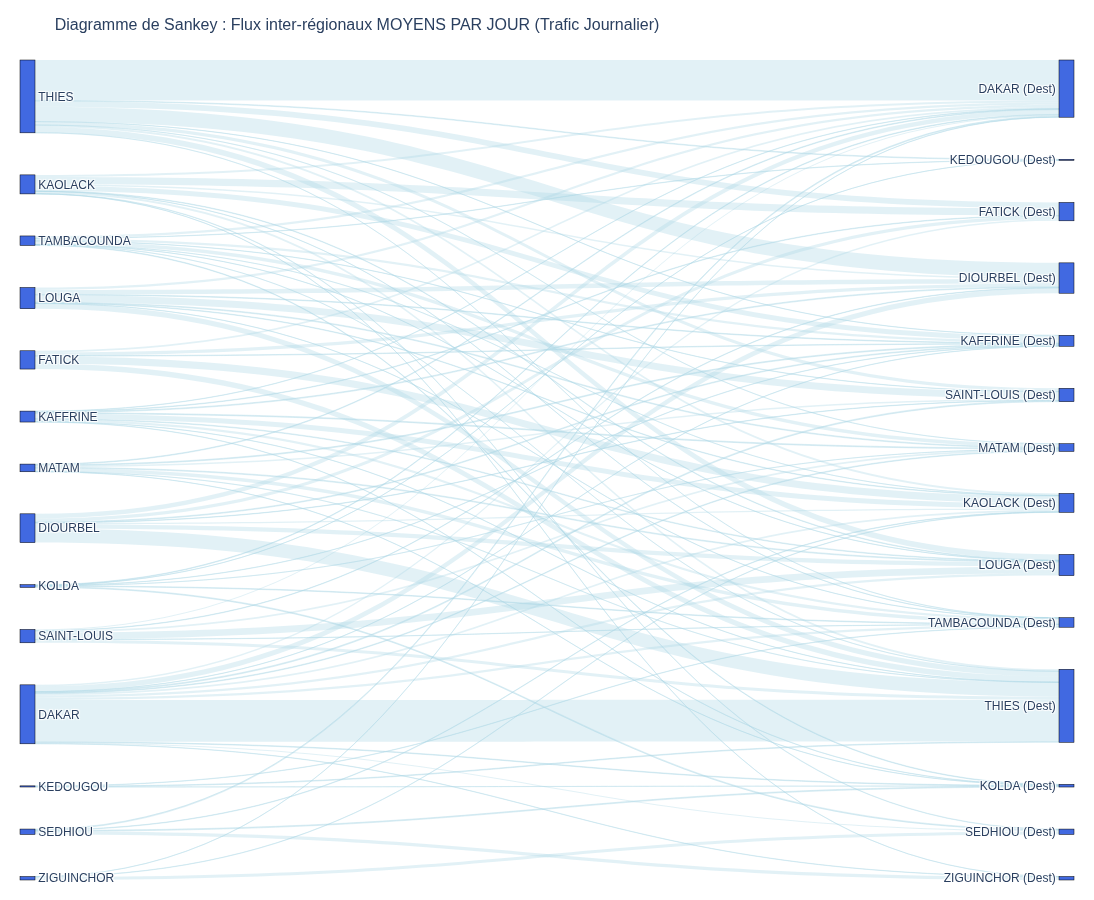

In [20]:
# --- GRAPHIQUE 2 : DIAGRAMME DE SANKEY DES FLUX JOURNALIERS MOYENS ---
import plotly.graph_objects as go
import numpy as np

# 1. Configuration de la période (Ex: 365 jours pour une année)
# Vous pouvez ajuster ce chiffre si votre dataset couvre une période légèrement différente
NB_JOURS = 365 

# 2. Préparation et conversion en Moyenne Journalière
df_sankey = matrice_reg.copy()

# Crucial : On divise TOUTE la matrice par le nombre de jours pour obtenir la moyenne par jour
# On arrondit à l'unité pour avoir des nombres de personnes entiers et propres
df_sankey = (df_sankey / NB_JOURS).round(0)

# On force la diagonale à 0 pour éliminer le bruit interne à chaque région
np.fill_diagonal(df_sankey.values, 0)

# Aplatissement de la matrice pour Plotly
df_sankey_flat = df_sankey.stack().reset_index()
df_sankey_flat.columns = ['Origine', 'Destination', 'Valeur']

# Filtrage des flux mineurs (inférieurs à la médiane) pour garder le graphique fluide
df_sankey_flat = df_sankey_flat[df_sankey_flat['Valeur'] > df_sankey_flat['Valeur'].quantile(0.5)]

# 3. Création des nœuds et mappages pour Plotly
regions_liste = sorted(list(matrice_reg.index))
nodes = regions_liste + [r + " (Dest)" for r in regions_liste]

mapping_origine = {nom: idx for idx, nom in enumerate(regions_liste)}
mapping_dest = {nom: idx + len(regions_liste) for idx, nom in enumerate(regions_liste)}

sources = df_sankey_flat['Origine'].map(mapping_origine).tolist()
targets = df_sankey_flat['Destination'].map(mapping_dest).tolist()
values = df_sankey_flat['Valeur'].tolist()

# 4. Construction du diagramme de Sankey aéré
fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 45,           # Grand espacement vertical entre les étiquettes
      thickness = 15,     # Largeur des blocs de régions
      line = dict(color = "black", width = 0.5),
      label = nodes,
      color = "royalblue"
    ),
    link = dict(
      source = sources,
      target = targets,
      value = values,     # Ces valeurs représentent désormais des "Déplacements / Jour"
      color = "rgba(173, 216, 230, 0.35)" 
  ))])

# 5. Mise en page avec mise à jour du Titre
fig.update_layout(
    title=dict(
        text="Diagramme de Sankey : Flux inter-régionaux MOYENS PAR JOUR (Trafic Journalier)",
        font=dict(size=16)
    ),
    height=900,           # Hauteur augmentée pour éviter les chevauchements de texte
    margin=dict(l=20, r=20, t=60, b=20)
)

# Sauvegarde et affichage
fig.write_html("./Deplacement/Diagramme_Sankey_Flux_Journalier.html")
fig.show()

Basée sur l'analyse exploratoire qui se complète par des flux moyens quotidiens modélisés par ce diagramme de Sankey, la conclusion structurelle qui s'en dégage est :

Le réseau de mobilité inter-régions met en évidence une asymétrie majeure et une polarisation extrême des déplacements quotidiens de la population. Les volumes de flux ne sont pas distribués de manière homogène, mais s'organisent autour d'un sous-ensemble restreint de nœuds pivots (les arrondissements sources et destinations les plus larges visuellement).

Cette configuration « Few-to-Few » (quelques sources majeures vers quelques destinations clés) valide d'un point de vue urbanistique le besoin de concevoir un réseau de transport hiérarchisé. Les trajectoires denses révélées par le diagramme tracent précisément les axes prioritaires où l'implantation d'infrastructures lourdes (type gares régionales, lignes de BRT ou extensions de lignes structurantes) est indispensable pour absorber les volumes quotidiens et décharger les axes saturés.

## II - Implémentation Concrète et Solutions Proposées


## Partie 1 : Couloir de Bus Express et Amelioration du carrefour de Grand Dakar

### A — Import des Datasets utiles

In [1]:
import pandas as pd

# Chargement
df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")

# CRÉATION D'UN DICTIONNAIRE POUR RECHERCHE ULTRA-RAPIDE (O(1))
# Au lieu d'utiliser df_stations.loc dans la boucle, on utilisera ce dictionnaire natif
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

# On garde le nombre d'arrondissements pour la taille de la matrice
nb_arr = len(df_regions)
print(f"Nombre de régions: {nb_arr}")

Nombre de régions: 123


### B — Construction de la matrice de Deplacement a l'ehelle des Arrondissements
- On utilise une logique de Chekpoint pour ne pas avoir a relancer a chaque fois l'execution sur tous les fichier du SET2 a chaque fois. On conserve l'evolution en sauvegardant la matrice de deplacement cumulé du fichier courant et des fichiers précédents.
- Etant donné que chaque fichier est classé par utilisateur et par timestamp, tant que l'utilisateur est le meme on lit chaque fichier ligne par ligne et on recupère l'id de la station qu'on agrège en arrondissement. Ensuite **le deplacement de A $=>$ B** est enregistré de tel sorte que l'arrondissement a la ligne i correspond a A et la celle de la ligne i+1 correspond a B.

In [2]:
import csv
import gc
from pathlib import Path
from collections import Counter
import pandas as pd
from tqdm import tqdm # Version standard en mode texte

# 1. Configuration et Dictionnaire
dossier_source = Path('../SET2/')
dossier_dest = Path('./Deplacement/')
dossier_dest.mkdir(exist_ok=True)

df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")
nb_arr = len(df_regions)

tous_fichiers_csv = sorted([f.name for f in dossier_source.glob('SET2*.CSV')])

# 2. Gestion de la reprise (Checkpointing)
checkpoints = sorted([f for f in dossier_dest.glob('Deplacements_arrondissement-P*.csv')])

if checkpoints:
    dernier_checkpoint = checkpoints[-1]
    matrice = pd.read_csv(dernier_checkpoint)
    dernier_p = dernier_checkpoint.stem.split('-')[-1] 
    print(f"Reprise détectée ! Chargement du checkpoint : {dernier_checkpoint.name}")
    fichiers_a_traiter = [
        f for f in tous_fichiers_csv 
        if f.split('_')[-1].split('.')[0] > dernier_p
    ]
else:
    print("Aucune sauvegarde trouvée. Démarrage depuis le début.")
    matrice = pd.DataFrame(0, index=range(nb_arr), columns=range(nb_arr))
    fichiers_a_traiter = tous_fichiers_csv

total_fichiers = len(fichiers_a_traiter)
print(f"{total_fichiers} fichier(s) restant(s) à traiter.")
print("-" * 50)


# 3. Boucle principale
# On utilise enumerate pour afficher proprement l'avancement des fichiers (ex: [1/10])
for idx, nom_fichier in enumerate(fichiers_a_traiter, 1):
    # Affichage textuel fixe de l'avancement global
    print(f"\n[{idx}/{total_fichiers}] En cours : {nom_fichier} ...")
    
    chemin_fichier = dossier_source / nom_fichier
    derniere_position = {} 
    compteur_deplacements = Counter()
    
    with open(chemin_fichier, mode='r', encoding='utf-8') as fichier:
        
        # Comptage rapide des lignes
        nb_lignes_total = sum(1 for _ in fichier)
        fichier.seek(0)
        
        lecteur = csv.reader(fichier)
        
        for ligne in tqdm(lecteur, total=nb_lignes_total, desc=" -> Progression des lignes", leave=False, mininterval=1.0):
            if len(ligne) < 3: 
                continue
                
            user_id = ligne[0]
            try:
                stationid = int(ligne[2])
            except ValueError:
                continue
            
            arr = dict_stations.get(stationid)
            if arr is None:
                continue
            arr = int(arr)
            
            if user_id in derniere_position:
                origine = derniere_position[user_id]
                compteur_deplacements[(origine - 1, arr - 1)] += 1
            
            derniere_position[user_id] = arr
            
    # 4. Transfert dans la matrice globale
    for (orig, dest), nombre_trajets in compteur_deplacements.items():
        matrice.iloc[orig, dest] += nombre_trajets
        
    partie_nom = nom_fichier.split('_')[-1].split('.')[0] 
    chemin_sauvegarde = dossier_dest / f'Deplacements_arrondissement-{partie_nom}.csv'
    matrice.to_csv(chemin_sauvegarde, index=False)
    
    # Nettoyage
    del compteur_deplacements
    del derniere_position
    gc.collect()

print("\n" + "="*50)
print("Fin totale du traitement ! Tous les fichiers ont été fusionnés.")
display(matrice)

Reprise détectée ! Chargement du checkpoint : Deplacements_arrondissement-P25.csv
0 fichier(s) restant(s) à traiter.
--------------------------------------------------

Fin totale du traitement ! Tous les fichiers ont été fusionnés.


,0,1,2,3,4,5,6,7,8,9,...,113,114,115,116,117,118,119,120,121,122
0,100845869,2626522,3337360,1281274,2224608,469444,286709,257046,63239,65338,...,30,62,904,0,140,1557,49,56,442,43
1,2656747,75967506,2706969,2223819,209255,182786,138177,135650,37260,38488,...,11,27,6614,0,37,11181,27,29,2832,25
2,3475526,2697836,94969356,3995123,590539,1092812,475590,266694,104031,83880,...,10,18,498,1,43,1035,29,34,1501,44
3,1311537,2254405,4122922,109816503,416542,494233,395237,326167,104659,85124,...,34,58,516,0,74,797,45,32,341,40
4,2188433,219085,603127,444326,51630183,1810134,215965,688772,34423,40203,...,11,24,657,0,55,694,154,24,1476,103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,1599,11106,1082,899,704,446,395,369,822,450,...,29,121,2533,1,277,10675529,98430,8037,12264,59466
119,70,33,43,53,131,94,69,66,34,48,...,2,3546,66,0,20,98706,3684885,727,700,1168
120,63,20,59,53,38,79,94,24,25,43,...,11,6,14,0,1,7017,718,1211040,185,200
121,406,2774,1540,354,1467,247,66,434,553,34,...,100,796,104505,3,1060,12896,696,253,8107749,61015


Ce code liste de manière brute et indiscutable les 25 trajets spécifiques de point à point (Département A vers Département B) qui enregistrent le plus grand nombre de voyageurs du pays, en excluant les trajets internes.

**Ce qu'elle nous dit pour améliorer la circulation au Sénégal :** C'est la feuille de route directe de vos investissements lourds en infrastructures de transport.
- **Décision concrète :** Si l'axe "PIKINE $\rightarrow$ DAKAR" ou "GUEDIAWAYE $\rightarrow$ DAKAR" arrive en position numéro 1 avec des chiffres écrasants, cela prouve mathématiquement que c'est là, et uniquement là, qu'il faut injecter les budgets pour déployer un transport de masse (prolongement d'une ligne de train TER, création d'un couloir de bus rapide BRT, ou création de voies de covoiturage).
- Pour determiner que les zones qui constituent les **axes de potentiel goulots d'etranglement** on applique **la regle des $3\sigma (Z-Score)$** pour detecter les outliers (Dans notre cas specialement ceux supérieur a la borne maximale)

### Detection des outiers (Zones de potentiel goulot d'etranglement)
- On effectue une analyse statistique sur l'axe des deplacements, on determine la moyenne et l'ecart type. Ensuite on s'en sert pour detecter les outliers qui dans notre cas correspondent aux zones ou le trafic sera dit anormalement élévé.
  On utilise la formule $[\bar{X} - 3\sigma; \bar{X} + 3\sigma]$ pour determiner les bornes

In [4]:
# --- EXTRACTION 3 : LES 25 AXES LES PLUS SATURÉS ---
# Complexité : Faible. .stack() convertit le tableau 2D en liste 1D ultra-rapidement.

# 1. On fait une copie pour ne pas abîmer la matrice originale
df_axes = matrice_dept.copy()

# 2. On force la diagonale à 0 pour ignorer les trajets internes et ne garder que les voyages INTER-départements
np.fill_diagonal(df_axes.values, 0)

# 3. On "aplatit" la matrice pour avoir une liste de paires (Origine -> Destination)
liste_flux = df_axes.stack().reset_index()
liste_flux.columns = ['Origine', 'Destination', 'Nombre de Déplacements']

moyenne_deplacement = liste_flux['Nombre de Déplacements'].mean()
ecartType_deplacement = liste_flux['Nombre de Déplacements'].std()


# 4. On trie pour obtenir les 10 axes les plus fréquentés
axes = liste_flux.sort_values(by='Nombre de Déplacements', ascending=False).head(25).reset_index(drop=True)

print("TOP 25 DES AXES INTER-DÉPARTEMENTAUX LES PLUS SATURÉS DU SÉNÉGAL :")
display(axes)

print("\n\n" + "-"*15 + " Etude statistique du Dataframe des Axes INTER-DÉPARTEMENTAUX " + "-"*15)
print(liste_flux['Nombre de Déplacements'].describe())
print(f"--------- La moyenne des deplacement est de {moyenne_deplacement}")
print(f"--------- La EcartType des deplacement est de {ecartType_deplacement}")

bornes = [moyenne_deplacement - 3 * ecartType_deplacement, moyenne_deplacement + 3 * ecartType_deplacement]

print(f"--------- Et l'intervalle normal des deplacement est : [{bornes[0]}; {bornes[1]}]")

print("\n\n" + "-"*15 + " Axes représentant les potentiels zones de goulot d'etranglement routiers " + "-"*15)
outliers = axes[ (axes['Nombre de Déplacements'] < bornes[0]) | (axes['Nombre de Déplacements'] > bornes[1])]
display(outliers)




TOP 25 DES AXES INTER-DÉPARTEMENTAUX LES PLUS SATURÉS DU SÉNÉGAL :


,Origine,Destination,Nombre de Déplacements
0,DAKAR,PIKINE,4520545
1,PIKINE,DAKAR,4318279
2,GUEDIAWAYE,DAKAR,3454971
3,DAKAR,GUEDIAWAYE,3440944
4,PIKINE,GUEDIAWAYE,2755589
5,GUEDIAWAYE,PIKINE,2714871
6,PIKINE,RUFISQUE,1920828
7,RUFISQUE,PIKINE,1862762
8,DAKAR,RUFISQUE,582019
9,RUFISQUE,DAKAR,576531




--------------- Etude statistique du Dataframe des Axes INTER-DÉPARTEMENTAUX ---------------
count    2.025000e+03
mean     2.072502e+04
std      2.070175e+05
min      0.000000e+00
25%      1.000000e+01
50%      1.270000e+02
75%      1.380000e+03
max      4.520545e+06
Name: Nombre de Déplacements, dtype: float64
--------- La moyenne des deplacement est de 20725.01827160494
--------- La EcartType des deplacement est de 207017.4836504411
--------- Et l'intervalle normal des deplacement est : [-600327.4326797185; 641777.4692229283]


--------------- Axes représentant les potentiels zones de goulot d'etranglement routiers ---------------


,Origine,Destination,Nombre de Déplacements
0,DAKAR,PIKINE,4520545
1,PIKINE,DAKAR,4318279
2,GUEDIAWAYE,DAKAR,3454971
3,DAKAR,GUEDIAWAYE,3440944
4,PIKINE,GUEDIAWAYE,2755589
5,GUEDIAWAYE,PIKINE,2714871
6,PIKINE,RUFISQUE,1920828
7,RUFISQUE,PIKINE,1862762


TOP 25 DES AXES INTER-ARRONDISSEMENTAUX LES PLUS SATURÉS :


,Origine,Destination,Nombre de Déplacements
0,DAKAR PLATEAU,GRAND DAKAR,4122922
1,GRAND DAKAR,DAKAR PLATEAU,3995123
2,GRAND DAKAR,PARCELLES ASSAINIES,3475526
3,PARCELLES ASSAINIES,GRAND DAKAR,3337360
4,ALMADIES,GRAND DAKAR,2706969
5,GRAND DAKAR,ALMADIES,2697836
6,ALMADIES,PARCELLES ASSAINIES,2656747
7,PARCELLES ASSAINIES,ALMADIES,2626522
8,DAKAR PLATEAU,ALMADIES,2254405
9,PARCELLES ASSAINIES,GUEDIAWAYE,2224608



Moyenne des déplacements : 8912.94
Écart-type : 115651.03
Seuil pour les goulots d'étranglement (> Moyenne + 3σ) : 355866.02

Top 10 des GOULOTS D'ÉTRANGLEMENT DÉTECTÉS (Outliers) :


,Origine,Destination,Nombre de Déplacements
371,DAKAR PLATEAU,GRAND DAKAR,4122922
249,GRAND DAKAR,DAKAR PLATEAU,3995123
246,GRAND DAKAR,PARCELLES ASSAINIES,3475526
2,PARCELLES ASSAINIES,GRAND DAKAR,3337360
125,ALMADIES,GRAND DAKAR,2706969
247,GRAND DAKAR,ALMADIES,2697836
123,ALMADIES,PARCELLES ASSAINIES,2656747
1,PARCELLES ASSAINIES,ALMADIES,2626522
370,DAKAR PLATEAU,ALMADIES,2254405
4,PARCELLES ASSAINIES,GUEDIAWAYE,2224608


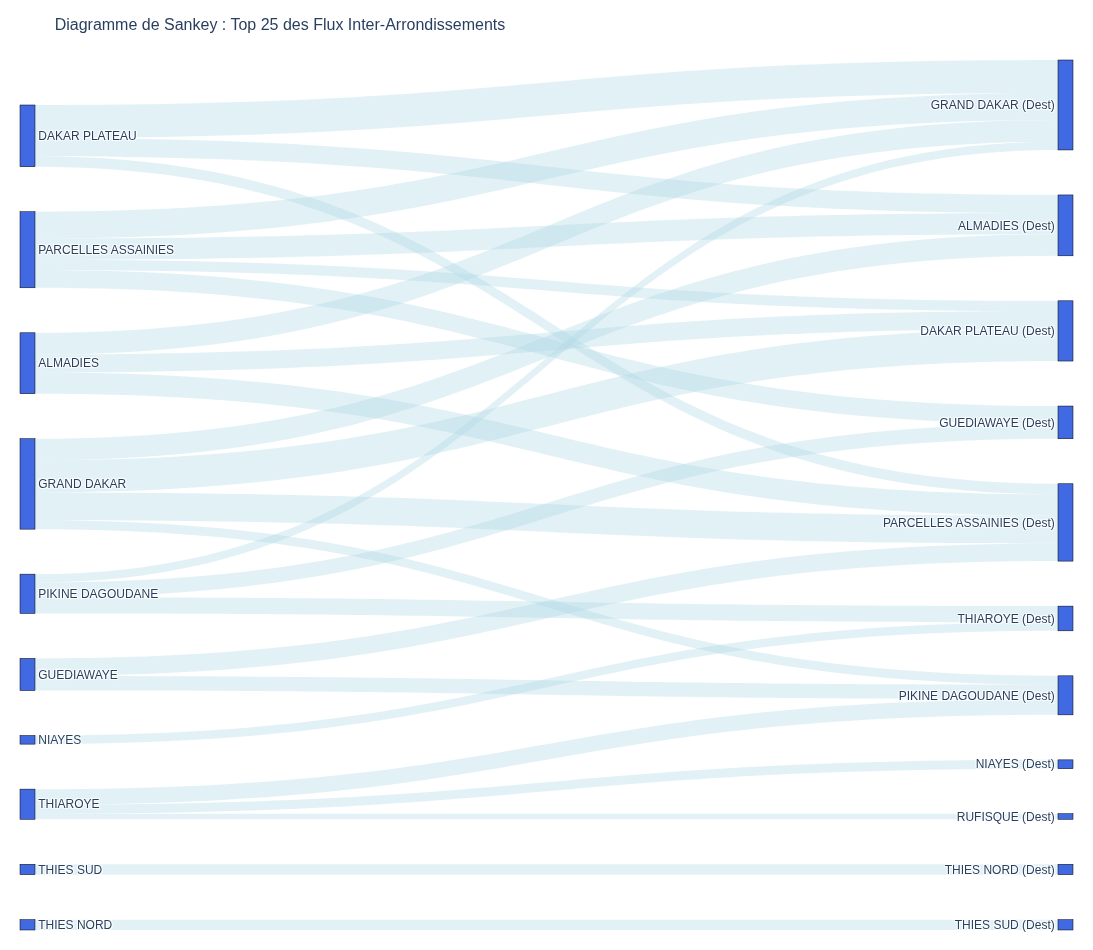

In [7]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# 1. Préparation de la matrice au niveau des arrondissements
# Assurez-vous que 'ARRONDISSEMENT' correspond au nom exact de la colonne dans SENEGAL_ARR_V2.csv

noms_arr = df_regions['ARR'].tolist() 

df_axes_arr = matrice.copy()
df_axes_arr.index = noms_arr
df_axes_arr.columns = noms_arr

# 2. Ignorer les déplacements internes (forcer la diagonale à 0)
np.fill_diagonal(df_axes_arr.values, 0)

# 3. Création du DataFrame des flux inter-arrondissementaux
liste_flux_arr = df_axes_arr.stack().reset_index()
liste_flux_arr.columns = ['Origine', 'Destination', 'Nombre de Déplacements']

# Filtrage des flux nuls pour alléger les calculs
liste_flux_arr = liste_flux_arr[liste_flux_arr['Nombre de Déplacements'] > 0]

# 4. Classement des axes les plus saturés (Top 25)
axes_arr = liste_flux_arr.sort_values(by='Nombre de Déplacements', ascending=False).head(25).reset_index(drop=True)
print("TOP 25 DES AXES INTER-ARRONDISSEMENTAUX LES PLUS SATURÉS :")
display(axes_arr)

# 5. Détermination des outliers (Goulots d'étranglement) via la règle des 3 sigmas
moyenne_arr = liste_flux_arr['Nombre de Déplacements'].mean()
ecartType_arr = liste_flux_arr['Nombre de Déplacements'].std()

# Calcul de la borne supérieure
borne_sup = moyenne_arr + 3 * ecartType_arr

print(f"\nMoyenne des déplacements : {moyenne_arr:.2f}")
print(f"Écart-type : {ecartType_arr:.2f}")
print(f"Seuil pour les goulots d'étranglement (> Moyenne + 3σ) : {borne_sup:.2f}")

outliers_arr = liste_flux_arr[liste_flux_arr['Nombre de Déplacements'] > borne_sup].sort_values(by='Nombre de Déplacements', ascending=False)
print("\nTop 10 des GOULOTS D'ÉTRANGLEMENT DÉTECTÉS (Outliers) :")
display(outliers_arr.head(10))

# 6. Génération du Diagramme de Sankey
# L'affichage est restreint au Top 25 pour maintenir une lisibilité optimale
sankey_data = axes_arr.copy()

# Création des listes de noeuds en différenciant l'origine de la destination
origines = sankey_data['Origine'].unique().tolist()
destinations = [f"{d} (Dest)" for d in sankey_data['Destination'].unique().tolist()]
labels = origines + destinations

# Création d'un dictionnaire de mapping vers des index entiers pour Plotly
mapping_orig = {nom: i for i, nom in enumerate(origines)}
mapping_dest = {nom.replace(" (Dest)", ""): i + len(origines) for i, nom in enumerate(destinations)}

sources = sankey_data['Origine'].map(mapping_orig).tolist()
targets = sankey_data['Destination'].map(mapping_dest).tolist()
values = sankey_data['Nombre de Déplacements'].tolist()

fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 45,
      thickness = 15,
      line = dict(color = "black", width = 0.5),
      label = labels,
      color = "royalblue"
    ),
    link = dict(
      source = sources,
      target = targets,
      value = values,
      color = "rgba(173, 216, 230, 0.35)"
    ))])

fig.update_layout(
    title=dict(
        text="Diagramme de Sankey : Top 25 des Flux Inter-Arrondissements",
        font=dict(size=16)
    ),
    height=950,
    margin=dict(l=20, r=20, t=60, b=20)
)

fig.show()

### Étape 1 : Associer les Arrondissements critiques à leurs Antennes (Sites)

Pour interroger la granularité fine des fichiers SET 1 et SET 2, il faut d'abord traduire les noms de vos arrondissements outliers en identifiants d'antennes (site_id) à l'aide du fichier de correspondance SITE_ARR_LATLON.csv fourni par le D4D.

In [8]:
# ==============================================================================
# ÉTAPE COMPLÉMENTAIRE 1 : CARTOGRAPHIE DES SITES ROUTIERS POUR UN AXE OUTLIER
# ==============================================================================
def selection_axes_critiques(num = 0) :
    # Sélection du premier axe le plus critique détecté dans vos outliers
    axe_critique = outliers_arr.iloc[num]
    nom_origine = axe_critique['Origine']
    nom_destination = axe_critique['Destination']
    
    # 1. Récupération des ARR_ID correspondants depuis votre DataFrame df_regions
    id_origine = df_regions[df_regions['ARR'] == nom_origine]['ARR_ID'].values[0]
    id_destination = df_regions[df_regions['ARR'] == nom_destination]['ARR_ID'].values[0]
    
    # 2. Chargement du fichier de localisation des antennes du D4D
    df_sites = pd.read_csv('SITE_ARR_LONLAT.CSV') # Contient site_id, arr_id, lon, lat
    
    # 3. Extraction de la liste des antennes pour l'origine et la destination
    sites_orig = df_sites[df_sites['arr_id'] == id_origine]['site_id'].tolist()
    sites_dest = df_sites[df_sites['arr_id'] == id_destination]['site_id'].tolist()

    print("\n\n" + "=" * 70)
    print(f" ANALYSE DE L'AXE CRITIQUE : {nom_origine} ➔ {nom_destination}")
    print("=" * 70)
    print(f"   ↳ ID Origine : {id_origine} ({len(sites_orig)} antennes associées)")
    print(f"   ↳ ID Destination : {id_destination} ({len(sites_dest)} antennes associées)")

    return sites_orig, sites_dest, nom_origine, nom_destination

### Étape 2 : Quantification de l'Entrave – Calcul du Temps de Parcours (SET 2)

- Ici on agit comme **un radar de trafic routier virtuel**. On fouille dans des millions de données téléphoniques pour trouver les personnes qui ont voyagé d'un point A à un point B, calcule combien de temps elles ont mis à chaque heure de la journée, puis on dessine un graphique pour montrer à quels moments la route est dégagée ou embouteillée.
- Le code trie les données par utilisateur (user_id) et par ordre chronologique (timestamp). Grâce à la fonction shift(1), il décale les données d'une ligne pour mettre face à face : **Où était cette personne à telle heure ?** et **Où était-elle juste avant, et à quelle heure ?**.
- Si l'origine et l'arrivée coincide, on fait une simple soustraction entre l'heure d'arrivée et l'heure de départ pour obtenir la durée en minutes (duree_min). Puis on fait un grand ménage en **supprimant les trajets des gens qui ont fait une pause en chemin (plus de 3 heures)**.


#### 1. Les heures de pointe et fluides (Méthode statistique)
- **Temps de référence :** On calcule d'abord la moyenne de tous les temps de trajet de la journée.
- **Heures de pointe :** Ce sont les heures où le trafic est "anormalement" lent (plus de 1,5 fois l'écart-type au-dessus de la moyenne $(Z-Score < 1.5)$).
- **Heures fluides :** Ce sont les heures où le trafic est meilleur que la moyenne $(Z-Score < 0)$.

#### 2. Le temps de trafic moyen

C'est tout simplement **la moyenne globale de tous les trajets observés sur la journée**. Elle est tracée comme une ligne horizontale de référence.

#### 3. Comment le graphique est tracé

Le graphique superpose trois éléments pour rendre l'information lisible :

- **La courbe orange :** Elle montre l'évolution réelle du temps de trajet heure par heure.
- **Le fond coloré :** Des bandes vertes (fluides) et rouges (pointes) sont placées en arrière-plan selon les résultats de la méthode statistique expliquée plus haut.
- **La ligne noire et la bande grise :** Elles matérialisent la "moyenne globale" et la zone de variabilité normale du trafic.

In [11]:
def analyser_temps_parcours(sites_orig, sites_dest, nom_origine, nom_destination, chemin_csv='../SET2/DATASET_FINAL.CSV'):
    """
    Analyse le temps de parcours médian et affiche le profil horaire algorithmique.
    L'indice de congestion est calculé spécifiquement sur le pic maximum de l'embouteillage.
    """
    import pandas as pd
    import gc
    import matplotlib.pyplot as plt

    print(f".... Initialisation de l'analyse : {nom_origine} ➔ {nom_destination}")
    
    noms_colonnes = ['user_id', 'timestamp', 'site_id']
    tous_sites = set(sites_orig + sites_dest)
    morceaux = []

    # 1. Chargement et filtrage à la volée
    for chunk in pd.read_csv(chemin_csv, header=None, names=noms_colonnes, chunksize=500000):
        chunk_filtre = chunk[chunk['site_id'].isin(tous_sites)]
        morceaux.append(chunk_filtre)

    if not morceaux:
        print(" Aucune donnée trouvée pour les antennes spécifiées.")
        return

    df_reduit = pd.concat(morceaux, ignore_index=True)
    del morceaux
    gc.collect()

    if df_reduit.empty:
        print(" Aucun enregistrement trouvé pour cet axe dans le jeu de données.")
        return

    # Conversion temporelle optimisée
    df_reduit['timestamp'] = pd.to_datetime(df_reduit['timestamp'])

    # 2. Reconstitution des trajectoires séquentielles
    df_reduit = df_reduit.sort_values(by=['user_id', 'timestamp'])
    df_reduit['antenne_precedente'] = df_reduit.groupby('user_id')['site_id'].shift(1)
    df_reduit['temps_precedent'] = df_reduit.groupby('user_id')['timestamp'].shift(1)

    # 3. Isolation des sauts directs Origine -> Destination
    trajets_axe = df_reduit[
        (df_reduit['antenne_precedente'].isin(sites_orig)) & 
        (df_reduit['site_id'].isin(sites_dest))
    ].copy()

    # Calcul de la durée en minutes et nettoyage des temps invalides/pauses
    trajets_axe['duree_min'] = (trajets_axe['timestamp'] - trajets_axe['temps_precedent']).dt.total_seconds() / 60.0
    trajets_propres = trajets_axe[(trajets_axe['duree_min'] > 0) & (trajets_axe['duree_min'] <= 180)].copy()
    
    if trajets_propres.empty:
        print(" Volume de trajets directs insuffisant après nettoyage.")
        return
        
    trajets_propres['Heure_Depart'] = trajets_propres['temps_precedent'].dt.hour
    del df_reduit, trajets_axe
    gc.collect()

    # 4. Algorithme de détection des profils horaires via Z-Score
    profil_horaire = trajets_propres.groupby('Heure_Depart')['duree_min'].median().reset_index()
    
    # Calcul des paramètres statistiques sur les médianes horaires
    moyenne_globale = profil_horaire['duree_min'].mean()
    ecart_type = profil_horaire['duree_min'].std()
    
    # Calcul du Z-Score pour chaque heure
    profil_horaire['z_score'] = (profil_horaire['duree_min'] - moyenne_globale) / ecart_type
    
    # Définition des seuils
    # Pointe : Heures où la durée est significativement supérieure à la moyenne (Z > 2)
    pointe = profil_horaire[profil_horaire['z_score'] > 0.5]['Heure_Depart'].tolist()
    
    # Fluide : Heures où la durée est inférieure à la moyenne (Z < 0)
    fluide = profil_horaire[profil_horaire['z_score'] < 0]['Heure_Depart'].tolist()

    # Si aucune pointe n'est détectée par le Z-Score, on fallback sur les 3 plus lentes par défaut
    if not pointe:
        pointe = profil_horaire.nlargest(3, 'duree_min')['Heure_Depart'].tolist()
        print("Note : Aucun pic statistiquement significatif (Z>2) détecté, fallback sur les 3 heures les plus lentes.")

    # Médianes classiques pour la représentation générale
    temps_fluide = int(trajets_propres[trajets_propres['Heure_Depart'].isin(fluide)]['duree_min'].median())
    temps_pointe = int(trajets_propres[trajets_propres['Heure_Depart'].isin(pointe)]['duree_min'].median())

    # --- CALCUL ISOLÉ POUR L'INDICE DE CONGESTION ---
    temps_pointe_max = profil_horaire[profil_horaire['Heure_Depart'].isin(pointe)]['duree_min'].max()
    indice_congestion = temps_pointe_max / temps_fluide


    # 5. Affichage des indicateurs textuels
    print("==================================================================")
    print(f" BILAN STATISTIQUE : {nom_origine} ➔ {nom_destination}")
    print("==================================================================")
    
    print(f" Heures fluides détectées   : {sorted(fluide)}h")
    print(f" Heures de pointe détectées : {sorted(pointe)}h")
    print(f"------------------------------------------------------------------")
    print(f" Temps de parcours médian en période FLUIDE  : {temps_fluide} minutes")
    print(f" Temps de parcours médian en période SATURÉE : {temps_pointe} minutes")
    print(f" INDICE DE CONGESTION : Au pire de l'embouteillage ({int(temps_pointe_max)} min), le trajet est {indice_congestion:.1f} fois plus long")
    
    # 6. Graphique
    plt.figure(figsize=(12, 6))
    
    # 1. Dessiner la bande de "normalité" (Moyenne +/- 0.5 écart-type)
    # Cela crée une zone autour de la moyenne qui représente le trafic "standard"
    plt.axhspan(moyenne_globale - (0.5 * ecart_type), 
                moyenne_globale + (0.5 * ecart_type), 
                color='blue', alpha=0.1, label='Zone de trafic standard')
    
    # 2. Dessiner la ligne de la moyenne globale
    plt.axhline(y=moyenne_globale, color='black', linestyle='-', linewidth=1.5, 
                label=f'Moyenne globale ({moyenne_globale:.1f} min)')

    # Courbe principale (Temps médian horaire)
    plt.plot(profil_horaire['Heure_Depart'], profil_horaire['duree_min'], 
             marker='o', color='darkorange', linewidth=2.5, label='Temps médian horaire')
    
    # Calques des heures
    for i, h in enumerate(sorted(fluide)):
        plt.axvspan(h, h + 1, color='green', alpha=0.07, label='Zones Fluides' if i == 0 else "")
    for i, h in enumerate(sorted(pointe)):
        plt.axvspan(h, h + 1, color='red', alpha=0.07, label='Zones de Pointe' if i == 0 else "")
    
    # Lignes pointillées de référence (remises sur les médianes classiques)
    plt.axhline(y=temps_fluide, color='green', linestyle='--', alpha=0.6, label=f'Réf. Fluide ({temps_fluide} min)')
    plt.axhline(y=temps_pointe, color='red', linestyle='--', alpha=0.6, label=f'Réf. Pointe ({temps_pointe} min)')
    
    plt.title(f"Profil horaire dynamique du temps de parcours : {nom_origine} ➔ {nom_destination}", fontsize=13, fontweight='bold')
    plt.xlabel("Heure de départ (0h - 23h)", fontsize=11)
    plt.ylabel("Temps de trajet (en MINUTES)", fontsize=11)
    plt.xticks(range(0, 24))
    plt.grid(True, linestyle='--', alpha=0.3)
    
    # Texte explicatif repassé sur la perte médiane
    perte_temps = temps_pointe - temps_fluide
    plt.text(12, ((temps_pointe + temps_fluide) / 2) - 15, 
         f"⚠️ Analyse Automatique :\n+ {perte_temps} min de perte médiane\nlors des pointes", 
         bbox=dict(facecolor='white', alpha=0.9, edgecolor='red', boxstyle='round,pad=0.5'),
         fontsize=10, color='darkred', weight='bold', horizontalalignment='center')
    
    plt.legend(loc='upper left', fontsize=10)
    plt.tight_layout()
    plt.show()



 ANALYSE DE L'AXE CRITIQUE : DAKAR PLATEAU ➔ GRAND DAKAR
   ↳ ID Origine : 4 (74 antennes associées)
   ↳ ID Destination : 3 (73 antennes associées)
.... Initialisation de l'analyse : DAKAR PLATEAU ➔ GRAND DAKAR
 BILAN STATISTIQUE : DAKAR PLATEAU ➔ GRAND DAKAR
 Heures fluides détectées   : [0, 1, 2, 4, 20, 21, 22, 23]h
 Heures de pointe détectées : [6, 7, 8, 9, 13, 15, 16, 17, 18]h
------------------------------------------------------------------
 Temps de parcours médian en période FLUIDE  : 30 minutes
 Temps de parcours médian en période SATURÉE : 50 minutes
 INDICE DE CONGESTION : Au pire de l'embouteillage (60 min), le trajet est 2.0 fois plus long


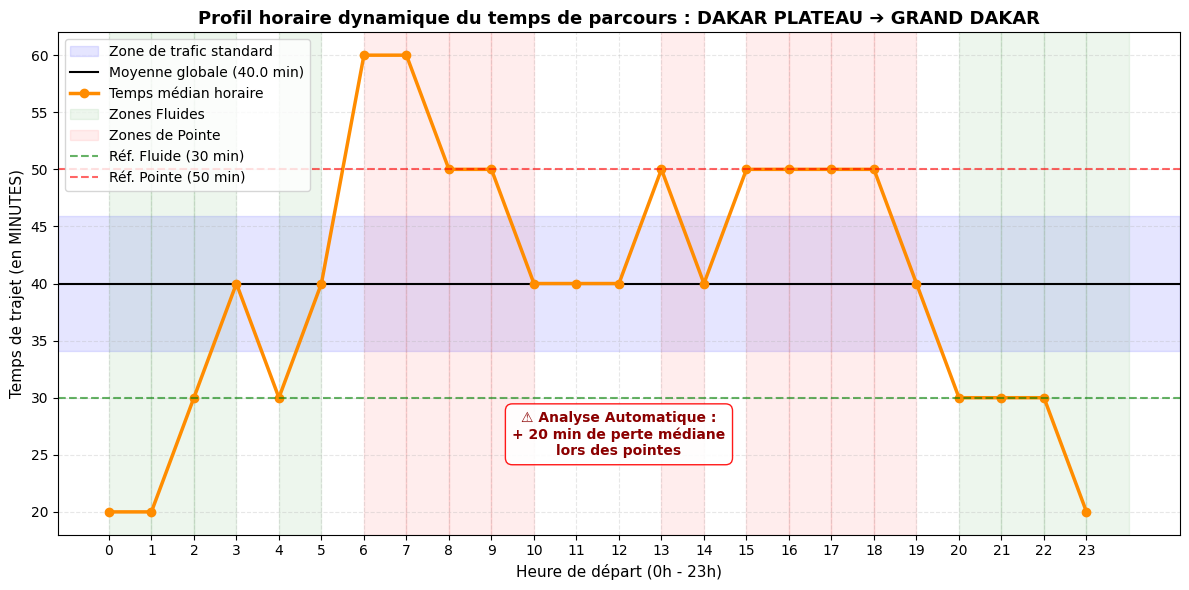



 ANALYSE DE L'AXE CRITIQUE : GRAND DAKAR ➔ PARCELLES ASSAINIES
   ↳ ID Origine : 3 (73 antennes associées)
   ↳ ID Destination : 1 (68 antennes associées)
.... Initialisation de l'analyse : GRAND DAKAR ➔ PARCELLES ASSAINIES
 BILAN STATISTIQUE : GRAND DAKAR ➔ PARCELLES ASSAINIES
 Heures fluides détectées   : [0, 1, 2, 3, 4, 5, 21, 22, 23]h
 Heures de pointe détectées : [7, 8, 9, 16, 17, 18]h
------------------------------------------------------------------
 Temps de parcours médian en période FLUIDE  : 20 minutes
 Temps de parcours médian en période SATURÉE : 50 minutes
 INDICE DE CONGESTION : Au pire de l'embouteillage (50 min), le trajet est 2.5 fois plus long


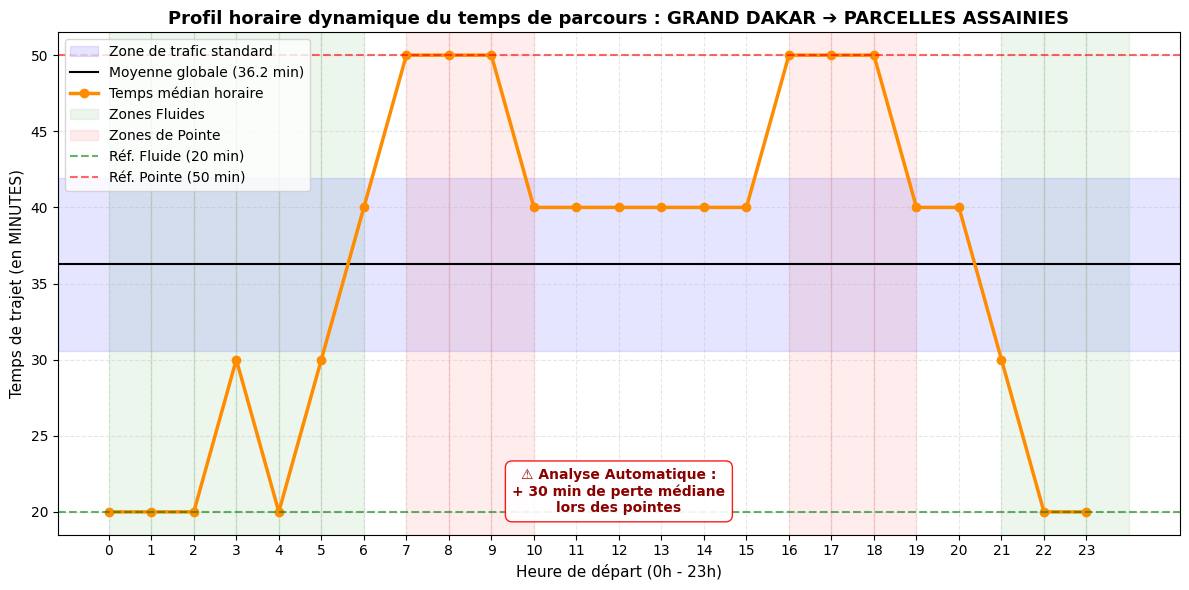



 ANALYSE DE L'AXE CRITIQUE : ALMADIES ➔ GRAND DAKAR
   ↳ ID Origine : 2 (74 antennes associées)
   ↳ ID Destination : 3 (73 antennes associées)
.... Initialisation de l'analyse : ALMADIES ➔ GRAND DAKAR
 BILAN STATISTIQUE : ALMADIES ➔ GRAND DAKAR
 Heures fluides détectées   : [0, 1, 2, 3, 20, 21, 22, 23]h
 Heures de pointe détectées : [6, 7, 8, 9, 10, 16, 17, 18]h
------------------------------------------------------------------
 Temps de parcours médian en période FLUIDE  : 30 minutes
 Temps de parcours médian en période SATURÉE : 50 minutes
 INDICE DE CONGESTION : Au pire de l'embouteillage (60 min), le trajet est 2.0 fois plus long


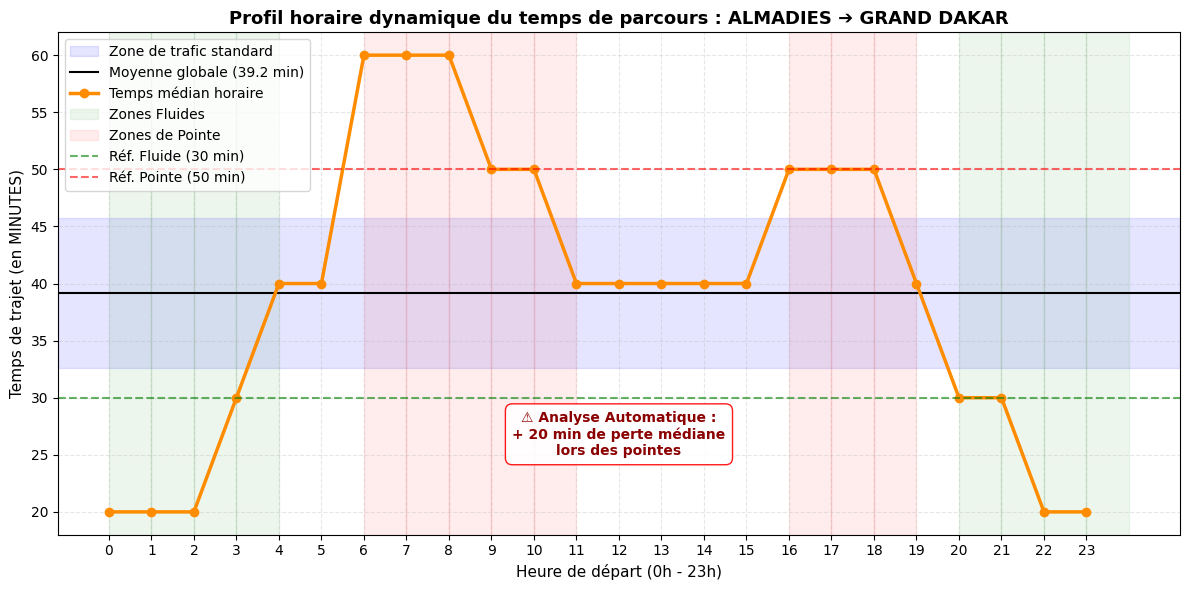



 ANALYSE DE L'AXE CRITIQUE : ALMADIES ➔ PARCELLES ASSAINIES
   ↳ ID Origine : 2 (74 antennes associées)
   ↳ ID Destination : 1 (68 antennes associées)
.... Initialisation de l'analyse : ALMADIES ➔ PARCELLES ASSAINIES
 BILAN STATISTIQUE : ALMADIES ➔ PARCELLES ASSAINIES
 Heures fluides détectées   : [0, 1, 2, 3, 4, 20, 21, 22, 23]h
 Heures de pointe détectées : [6, 8, 16, 17, 18]h
------------------------------------------------------------------
 Temps de parcours médian en période FLUIDE  : 30 minutes
 Temps de parcours médian en période SATURÉE : 50 minutes
 INDICE DE CONGESTION : Au pire de l'embouteillage (50 min), le trajet est 1.7 fois plus long


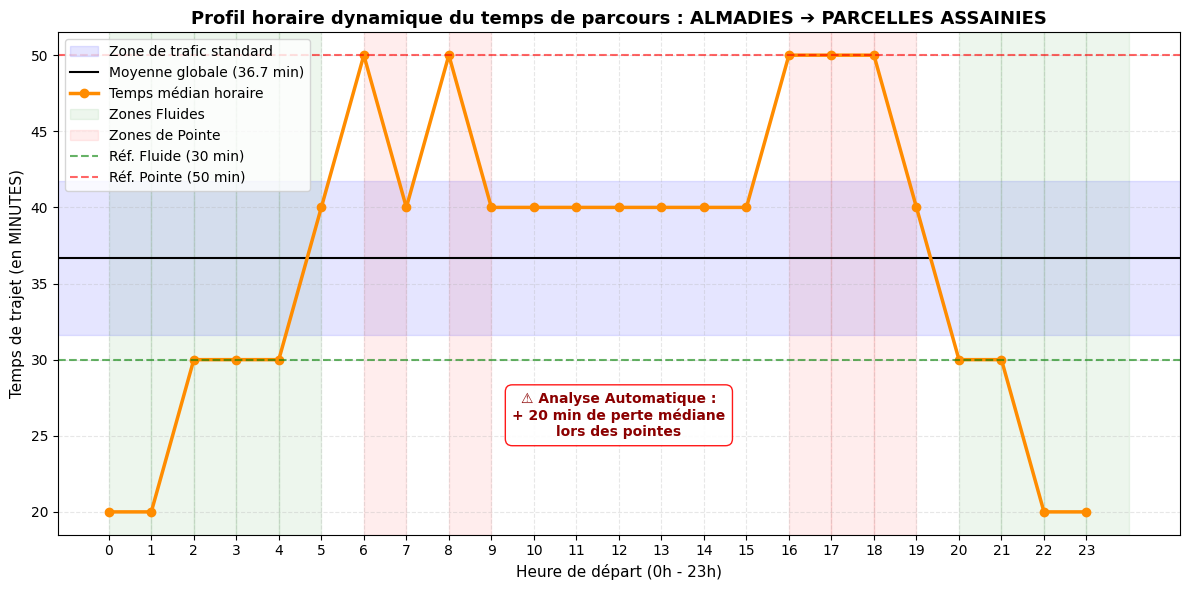



 ANALYSE DE L'AXE CRITIQUE : DAKAR PLATEAU ➔ ALMADIES
   ↳ ID Origine : 4 (74 antennes associées)
   ↳ ID Destination : 2 (74 antennes associées)
.... Initialisation de l'analyse : DAKAR PLATEAU ➔ ALMADIES
 BILAN STATISTIQUE : DAKAR PLATEAU ➔ ALMADIES
 Heures fluides détectées   : [0, 1, 2, 3, 4, 5, 20, 21, 22, 23]h
 Heures de pointe détectées : [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]h
------------------------------------------------------------------
 Temps de parcours médian en période FLUIDE  : 30 minutes
 Temps de parcours médian en période SATURÉE : 50 minutes
 INDICE DE CONGESTION : Au pire de l'embouteillage (70 min), le trajet est 2.3 fois plus long


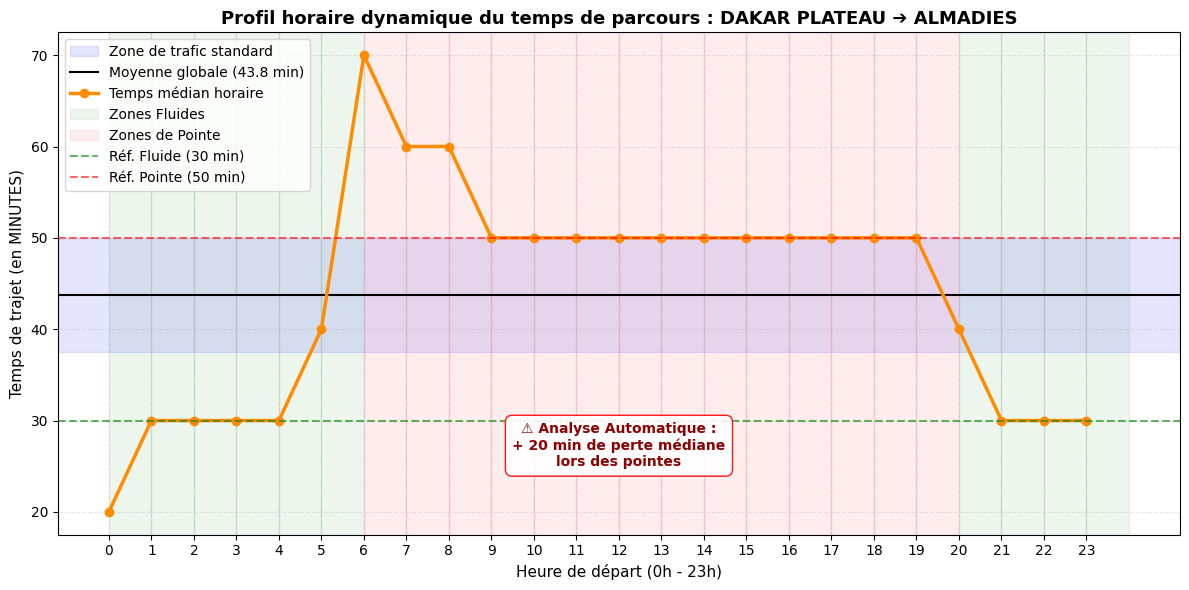

In [12]:
# ==============================================================================
# APPELS EXPÉRIMENTAUX SUR DIFFÉRENTS AXES
# ==============================================================================

for i in range(0, 10, 2):
    sites_orig, sites_dest, nom_origine, nom_destination = selection_axes_critiques(i)
    
    analyser_temps_parcours(
        sites_orig=sites_orig, 
        sites_dest=sites_dest, 
        nom_origine=nom_origine, 
        nom_destination=nom_destination
    )

# Exemple d'appel 2 : Application instantanée sur un autre axe imaginaire 
# (Il vous suffit de renseigner les nouvelles listes de sites et les noms associés)
# sites_pikine = [104, 205, 309] 
# analyser_temps_parcours(
#     sites_orig=sites_pikine, 
#     sites_dest=sites_dest, 
#     nom_origine="Pikine", 
#     nom_destination="Dakar Plateau"
# )

### 1. Le Diagnostic : Où et quand est-ce que ça coince ?

En croisant nos cartes et nos graphiques de trafic, le constat est sans appel : le problème majeur de mobilité se concentre dans la région de Dakar, et plus précisément autour de quatre grands quartiers : **les Parcelles Assainies, les Almadies, le Plateau et Grand Dakar**.

### 1.1 Le point noir spatial : L’effet « entonnoir » de Grand Dakar

Si on regarde les volumes de déplacements, un quartier sort du lot : Grand Dakar. C'est le cœur du problème.
- Les gens habitent massivement aux Parcelles Assainies, travaillent dans les bureaux au Plateau ou font des affaires aux Almadies.
- Résultat ? Tout ce beau monde est obligé de traverser ou de converger vers Grand Dakar. C'est le véritable entonnoir de la capitale, avec des millions de trajets qui s'y croisent chaque jour.

### 1.2 Le point noir temporel : Des trajets qui durent parfois plus du triple

**Nos analyses d'horaires montrent deux moments critiques dans la journée :** le matin généralement entre 6h et 9h, et le soir entre 16h et 19h.

Pendant ces heures de pointe, notre indicateur de congestion explose et atteint presque le double de la normale. Pour vous donner une idée très simple : un trajet qui prend habituellement 40 minutes lorsque la route est en trafic normal va vous prendre près de 1h15 à ces heures-là. C'est du temps perdu pour l'économie, de l'essence gaspillée et une énorme fatigue pour les travailleurs.


### 2. Nos propositions concrètes pour fluidifier la circulation

Face à ce constat, nous n'avons pas besoin de réinventer toutes les routes de Dakar. Il faut agir de manière chirurgicale là où ça fait mal. Voici trois solutions pragmatiques :

### Solution 1 : Un couloir de Bus Express (voie réservée) sur l'axe Parcelles Assainies → Grand Dakar → Plateau
- **L'idée :** On crée une nouvelle voie, totalement séparée des voitures par des bordures, réservée uniquement à des bus à grande capacité qui circulent non-stop.
- **Ce que ça change :** Le voyageur qui monte dans ce bus sait exactement à quelle heure il arrive, car le bus ne subit jamais les bouchons des voitures. Cela va inciter une grande partie des des usagers non véhiculé à abandonner les taxis clandestins pour prendre le bus. Moins de voitures sur la route, c'est immédiatement moins de bouchons pour ceux qui restent.

### Solution 2 : Aménager le carrefour de Grand Dakar (Autopont et routes secondaires)
- **L'idée :** On remarque grace au graphique de Sankey que **Grand Dakar** est comme une zone de carrefour qui recoit un flux massif d'usager venant des arrondissements tels que **Dakar Plateau, les Almadies ou les Parcelles Assainies**. Les voitures se coupent la route dans tous les sens, ce qui crée des blocages monstres. La solution est de construire un autopont (un saut-de-mouton) pour que le trafic qui ne fait que passer survole le carrefour sans s'arrêter. En même temps, il faut bitumer les petites rues secondaires tout autour pour offrir des voies d'évitement.
- **Ce que ça change :** On sépare les flux. Ceux qui vont loin passent au-dessus, le trafic local reste en bas. Le carrefour respire enfin, et le bouchon géant ne remonte plus vers les Almadies ou les Parcelles Assainies.

## Partie 2 : Proposition de Reseaux de Transport Evènementiel et Temporaire

### Evènement Etudié : Grand Magal de Touba

C’est le plus grand pèlerinage religieux de la confrérie musulmane mouride. Cet événement ne célèbre pas une naissance ou un deuil, mais commémore le départ en exil (au Gabon) de Cheikh Ahmadou Bamba, le fondateur de la confrérie, perçu comme une victoire spirituelle. C'est un moment intense de prières, de récits de poèmes sacrés (khassaides) et d'hospitalité absolue où de copieux repas (berndé) sont offerts gratuitement à des millions de pèlerins.

- **Période précise :** Il n'existe pas de periode précise (Jour ou Mois) de l'année ordinaire ou on peut etre sur que l'évènement tombera chaque année à cause de la difference entre notre calendrier et **le calendrier lunaire musulman (l'Hégire)**. Cependant, en 2013, **le Grand Magal de Touba a eu lieu 2 fois au cours de la meme année civile (Le 1er janvier 2013 et Le 22 décembre 2013)**
- **Repère lunaire :** Le 18 du mois de Safar.
- **Régions de départ (Origines) :** Massivement la région de Dakar (qui se vide d'une grande partie de ses habitants), mais aussi Thiès et l'ensemble des autres régions. 
- **Région d'arrivée (Destination) :** La région de **Diourbel** (spécifiquement la ville sainte de Touba et la localité adjacente de Mbacké).

### A —  Extraction et Etude des deplacements à la période ciblée

In [1]:
import pandas as pd

# Chargement
df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")

# CRÉATION D'UN DICTIONNAIRE POUR RECHERCHE ULTRA-RAPIDE (O(1))
# Au lieu d'utiliser df_stations.loc dans la boucle, on utilisera ce dictionnaire natif
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

# On garde le nombre d'arrondissements pour la taille de la matrice
nb_arr = len(df_regions)

In [2]:
import csv
import gc
from pathlib import Path
import numpy as np
from tqdm import tqdm

# 1. Configuration et Dictionnaires de Correspondance
dossier_source = Path('../SET2/')
dossier_dest = Path('./Deplacement_MAGAL/')
dossier_dest.mkdir(exist_ok=True)

df_stations = pd.read_csv("SITE_ARR_LONLAT.CSV")
dict_stations = df_stations.set_index('site_id')['arr_id'].to_dict()

df_regions = pd.read_csv("SENEGAL_ARR_V2.csv")
nb_arr = len(df_regions)

tous_fichiers_csv = sorted([f.name for f in dossier_source.glob('SET2*.CSV')])

# 2. Gestion de la reprise (Checkpointing)
checkpoints_magal = sorted([f for f in dossier_dest.glob('Deplacements_arrondissement_magal-*.csv')])
checkpoints_simple = sorted([f for f in dossier_dest.glob('Deplacements_arrondissement_simple-*.csv')])

if checkpoints_magal and checkpoints_simple:
    dernier_checkpoint_magal = checkpoints_magal[-1]
    dernier_checkpoint_simple = checkpoints_simple[-1]
    
    # Optimisation : On charge directement en matrices NumPy
    matrice_magal = pd.read_csv(dernier_checkpoint_magal).to_numpy(dtype=np.int64)
    matrice_simple = pd.read_csv(dernier_checkpoint_simple).to_numpy(dtype=np.int64)
    
    dernier_p = dernier_checkpoint_magal.stem.split('-')[-1] 
    print(f"Reprise détectée ! Chargement du checkpoint : {dernier_checkpoint_magal.name}")
    fichiers_a_traiter = [
        f for f in tous_fichiers_csv 
        if f.split('_')[-1].split('.')[0] > dernier_p
    ]
else:
    print("Aucune sauvegarde trouvée. Démarrage depuis le début.")
    # Initialisation de matrices NumPy rapides
    matrice_magal = np.zeros((nb_arr, nb_arr), dtype=np.int64)
    matrice_simple = np.zeros((nb_arr, nb_arr), dtype=np.int64)
    fichiers_a_traiter = tous_fichiers_csv

total_fichiers = len(fichiers_a_traiter)
print(f"{total_fichiers} fichier(s) restant(s) à traiter.")
print("-" * 50)

# ============================================================================
# 3. BOUCLE PRINCIPALE DE TRAITEMENT (VERSION AVEC BARRE DE PROGRESSION EN MO)
# ============================================================================
for idx, nom_fichier in enumerate(fichiers_a_traiter, 1):
    chemin_fichier = dossier_source / nom_fichier
    
    # 💡 ASTUCE : Récupération instantanée de la taille du fichier en octets
    taille_totale_octets = chemin_fichier.stat().st_size
    
    print(f"\n[{idx}/{total_fichiers}] Traitement de : {nom_fichier}")
    
    derniere_position_magal = {} 
    derniere_position_simple = {} 
    
    # Remplacement de csv.reader par une lecture brute ligne par ligne pour mesurer les octets
    with open(chemin_fichier, mode='r', encoding='utf-8') as fichier:
        # On passe la taille en paramètre à tqdm (unit='B' pour Bytes/Octets)
        with tqdm(total=taille_totale_octets, unit='B', unit_scale=True, unit_divisor=1024, desc=" -> Progression", leave=False) as pbar:
            
            for ligne_brute in fichier:
                # On fait avancer la barre de la taille exacte de la ligne lue
                pbar.update(len(ligne_brute))
                
                # Découpage rapide de la ligne
                ligne = ligne_brute.strip().split(',')
                if len(ligne) < 3: 
                    continue

                user_id = ligne[0]
                try:
                    stationid = int(ligne[2])
                except ValueError:
                    continue

                # Extraction ultra-rapide de l'heure
                try:
                    jour = int(ligne[1][8:10])
                    mois = int(ligne[1][5:7])
                except (IndexError, ValueError):
                    continue

                # --- Periode du grand MAGAL en 2013 (Le 1er janvier 2013 et Le 22 décembre 2013) ---
                if (1 <= jour <= 4 and mois == 1) or (20 <= jour <= 24 and mois == 12):
                    arr = dict_stations.get(stationid)
                    if arr is None:
                        continue
                    arr = int(arr)
                    
                    if user_id in derniere_position_magal:
                        origine = derniere_position_magal[user_id]
                        matrice_magal[origine - 1, arr - 1] += 1
                    
                    derniere_position_magal[user_id] = arr

                # --- On recupere les meme jour pour les autres mois ---
                elif (1 <= jour <= 4 and mois in [i for i in range(2,12)]) or (20 <= jour <= 24 and mois in [i for i in range(2,12)]):
                    
                    arr = dict_stations.get(stationid)
                    if arr is None:
                        continue
                    arr = int(arr)
                    
                    if user_id in derniere_position_simple:
                        origine = derniere_position_simple[user_id]
                        matrice_simple[origine - 1, arr - 1] += 1
                    
                    derniere_position_simple[user_id] = arr
                
    # 4. Sauvegarde des checkpoints (Reste inchangé)
    partie_nom = nom_fichier.split('_')[-1].split('.')[0] 
    chemin_sauvegarde_magal = dossier_dest / f'Deplacements_arrondissement_magal-{partie_nom}.csv'
    chemin_sauvegarde_simple = dossier_dest / f'Deplacements_arrondissement_simple-{partie_nom}.csv'
    
    pd.DataFrame(matrice_magal).to_csv(chemin_sauvegarde_magal, index=False)
    pd.DataFrame(matrice_simple).to_csv(chemin_sauvegarde_simple, index=False)
    
    del derniere_position_magal
    del derniere_position_simple
    gc.collect()

print("\n" + "="*50)
print("Fin totale du traitement ! Tous les fichiers ont été fusionnés.")

# 5. Conversion finale pour l'affichage
matrice_magal = pd.DataFrame(matrice_magal)
matrice_simple = pd.DataFrame(matrice_simple)

Reprise détectée ! Chargement du checkpoint : Deplacements_arrondissement_magal-P25.csv
0 fichier(s) restant(s) à traiter.
--------------------------------------------------

Fin totale du traitement ! Tous les fichiers ont été fusionnés.


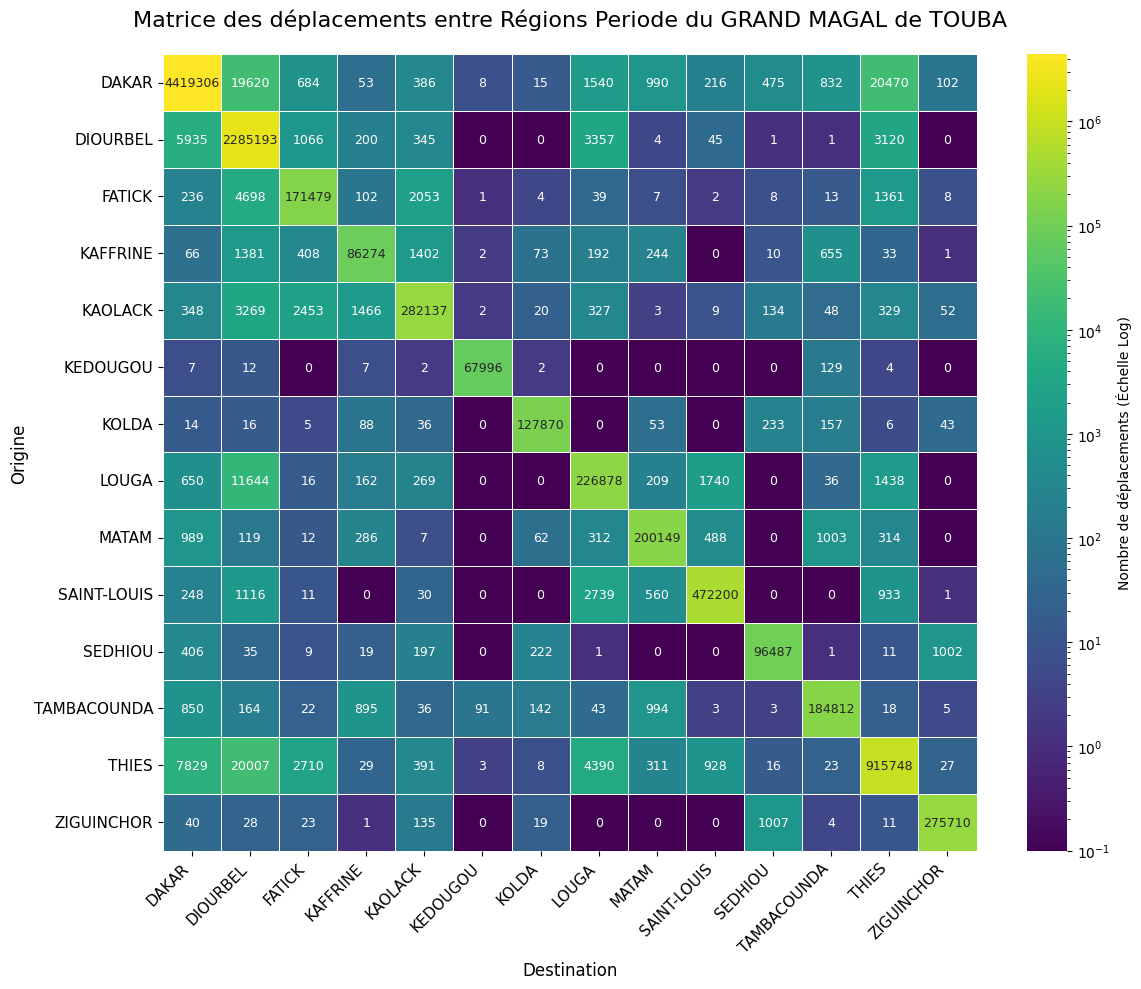

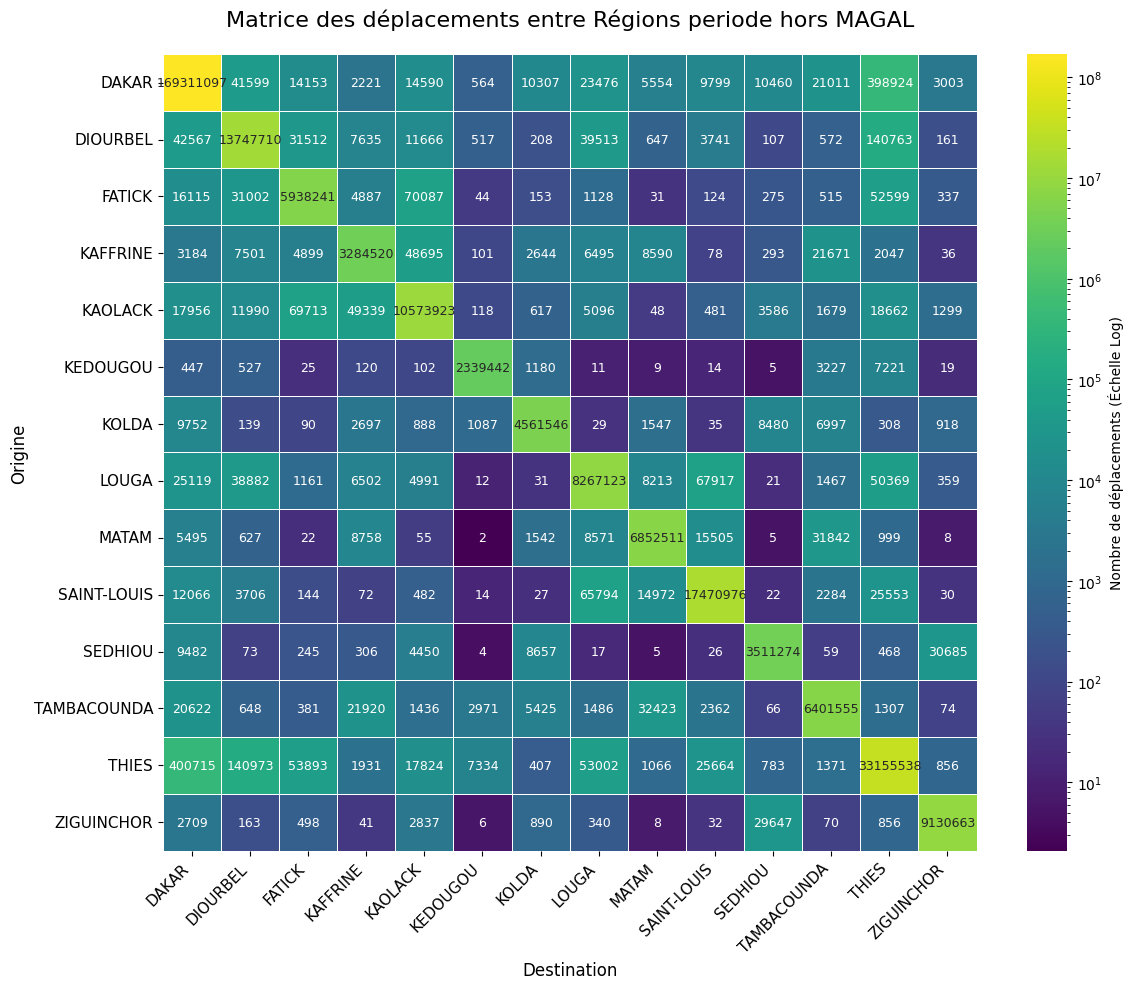

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

# 1. Configuration des chemins
dossier_dest = Path('./Deplacement_MAGAL/')
dossier_dest.mkdir(exist_ok=True)

# Charger la table de correspondance (Arrondissements, Départements, Régions)
df_geo = pd.read_csv("SENEGAL_ARR_V2.csv")

df_geo_triee = df_geo.sort_values(by='ARR_ID').reset_index(drop=True)

liste_departements = df_geo_triee['DEPT'].tolist()
liste_regions = df_geo_triee['REG'].tolist()

# Obtenir la liste unique et triée des départements et régions pour les index des nouvelles matrices
uniques_depts = sorted(list(set(liste_departements)))
uniques_regs = sorted(list(set(liste_regions)))

# ---------------------------------------------------------------------------
# 3. FONCTION DE CORRESPONDANCE ET D'AGRÉGATION (CORRIGÉE SANS WARNING)
# ---------------------------------------------------------------------------
def agreger_matrice(matrice_source, liste_categories, labels_uniques):
    """
    Agrège une matrice d'arrondissements vers une échelle supérieure (Département ou Région)
    Garantie sans FutureWarning avec les versions récentes de Pandas.
    """
    # Étape A : On applique les labels géographiques sur les lignes et les colonnes
    df_temp = pd.DataFrame(matrice_source.values, index=liste_categories, columns=liste_categories)
    
    # Étape B : On somme les lignes qui ont le même nom (Axe des Origines)
    df_somme_lignes = df_temp.groupby(level=0).sum()
    
    # Étape C : Nouvelle méthode recommandée pour sommer les colonnes (Axe des Destinations)
    # On transpose (.T), on groupe par lignes, puis on re-transpose (.T)
    matrice_agregee = df_somme_lignes.T.groupby(level=0).sum().T
    
    # Étape D : On réindexe proprement pour conserver l'ordre alphabétique
    matrice_agregee = matrice_agregee.reindex(index=labels_uniques, columns=labels_uniques).fillna(0).astype(int)
    
    return matrice_agregee

matrice_dept_magal = agreger_matrice(
    matrice_magal,
    liste_departements,
    uniques_depts
)

matrice_reg_magal = agreger_matrice(
    matrice_magal,
    liste_regions,
    uniques_regs
)


matrice_dept_simple = agreger_matrice(
    matrice_simple,
    liste_departements,
    uniques_depts
)

matrice_reg_simple = agreger_matrice(
    matrice_simple,
    liste_regions,
    uniques_regs
)


# ---------------------------------------------------------------------------
# 4. CRÉATION DES MATRICES DE CONFUSION VISUELLES (HEATMAPS)
# ---------------------------------------------------------------------------
def generer_heatmap(matrice_data, titre, nom_fichier_image, taille_police=10, fig_size=(12, 10), annot=False):
    """
    Génère et sauvegarde une carte de chaleur pour les matrices Origin-Destination
    """
    plt.figure(figsize=fig_size)
    
    # CORRECTION : fmt=".0f" au lieu de "d" pour afficher des flottants sans décimales
    sns.heatmap(matrice_data + 0.1, 
                cmap='viridis', 
                norm=LogNorm(), 
                annot=annot, 
                fmt=".0f", # <-- Modifié ici pour accepter les valeurs converties en float (+0.1)
                annot_kws={"size": taille_police - 2},
                linewidths=0.5,
                cbar_kws={'label': 'Nombre de déplacements (Échelle Log)'})
    
    plt.title(titre, fontsize=16, pad=20)
    plt.xlabel("Destination", fontsize=12)
    plt.ylabel("Origine", fontsize=12)
    plt.xticks(fontsize=taille_police, rotation=45, ha='right')
    plt.yticks(fontsize=taille_police, rotation=0)
    
    plt.tight_layout()
    plt.savefig(dossier_dest / nom_fichier_image, dpi=300)
    plt.show()



# Génération de la Heatmap des Régions (Avec annotations car seulement 14 régions au Sénégal)
generer_heatmap(matrice_reg_magal, 
                titre="Matrice des déplacements entre Régions Periode du GRAND MAGAL de TOUBA", 
                nom_fichier_image="Matrice_Confusion_Regions_periode_magal.png",
                taille_police=11, 
                fig_size=(12, 10),
                annot=True) # On affiche les chiffres ici !

# Génération de la Heatmap des Régions (Avec annotations car seulement 14 régions au Sénégal)
generer_heatmap(matrice_reg_simple, 
                titre="Matrice des déplacements entre Régions periode hors MAGAL", 
                nom_fichier_image="Matrice_Confusion_Regions_hors_magal.png",
                taille_police=11, 
                fig_size=(12, 10),
                annot=True) # On affiche les chiffres ici !


🔗 Graphique comparatif unique sauvegardé sous : Deplacement_MAGAL/Comparaison_Sankey_Flux_Journaliers.html


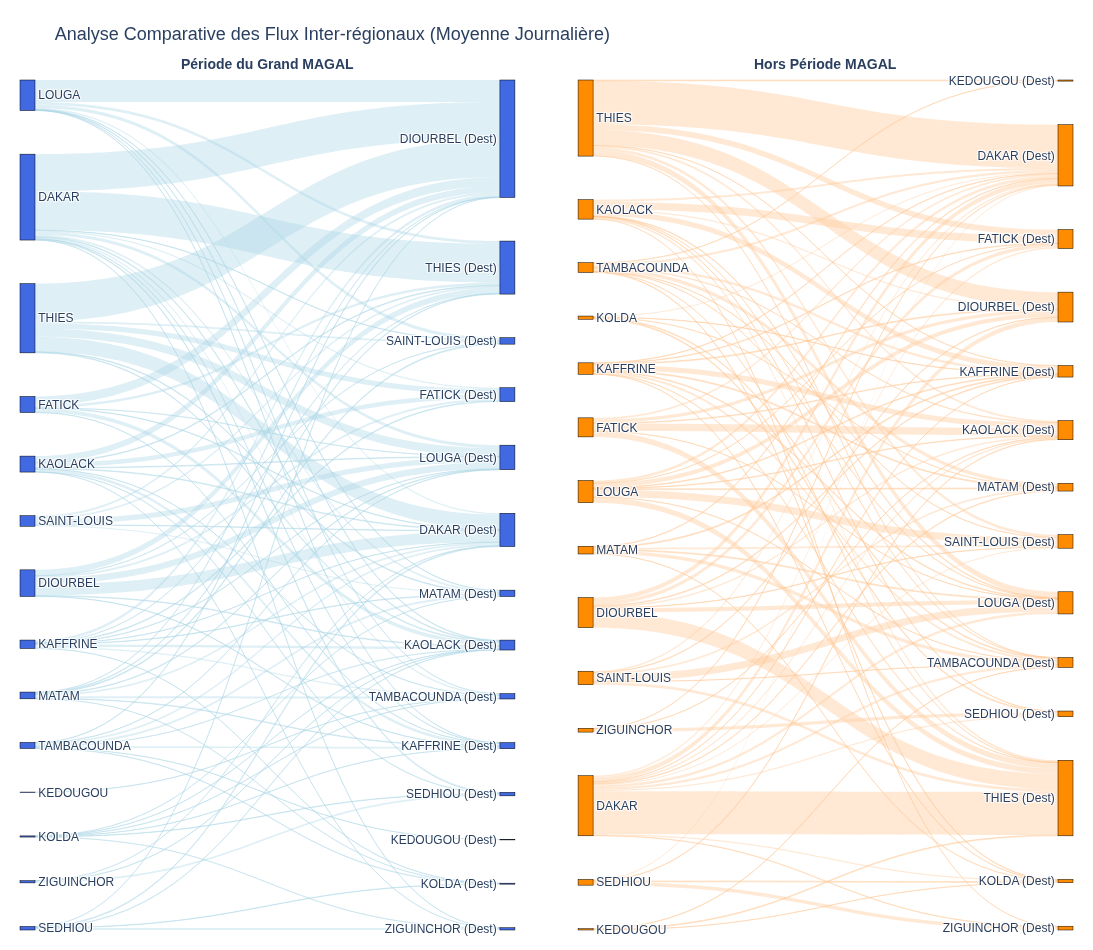

In [4]:
import plotly.graph_objects as go

def preparer_donnees_sankey(matrice_reg, nb_jours, quantile_filtre):
    """
    Fonction interne pour nettoyer la matrice, calculer la moyenne journalière
    et préparer la structure (noeuds/liens) requise par Plotly.
    """
    df_sankey = matrice_reg.copy()
    # Calcul de la moyenne journalière brute
    df_sankey = (df_sankey / nb_jours).round(0)
    # Suppression de la diagonale
    np.fill_diagonal(df_sankey.values, 0)

    # Aplatissement
    df_sankey_flat = df_sankey.stack().reset_index()
    df_sankey_flat.columns = ['Origine', 'Destination', 'Valeur']

    # Filtrage des flux mineurs
    if quantile_filtre > 0:
        seuil = df_sankey_flat['Valeur'].quantile(quantile_filtre)
        df_sankey_flat = df_sankey_flat[df_sankey_flat['Valeur'] > seuil]

    # Cartographie des index pour Plotly
    regions_liste = sorted(list(matrice_reg.index))
    nodes = regions_liste + [r + " (Dest)" for r in regions_liste]

    mapping_origine = {nom: idx for idx, nom in enumerate(regions_liste)}
    mapping_dest = {nom: idx + len(regions_liste) for idx, nom in enumerate(regions_liste)}

    sources = df_sankey_flat['Origine'].map(mapping_origine).tolist()
    targets = df_sankey_flat['Destination'].map(mapping_dest).tolist()
    values = df_sankey_flat['Valeur'].tolist()
    
    return nodes, sources, targets, values


def tracer_double_sankey_flux(
    matrice_magal, 
    matrice_simple, 
    nb_jours_magal=9, 
    nb_jours_simple=90, 
    quantile_filtre=0.5, 
    chemin_sauvegarde="./Deplacement_MAGAL/Comparaison_Sankey_Flux_Journaliers.html", 
    titre_general="Analyse Comparative des Flux Inter-régionaux (Moyenne Journalière)",
    hauteur=950
):
    """
    Génère une figure unique contenant deux diagrammes de Sankey côte à côte.
    """
    # 1. Préparation indépendante des données de chaque matrice
    nodes_m, sources_m, targets_m, values_m = preparer_donnees_sankey(matrice_magal, nb_jours_magal, quantile_filtre)
    nodes_s, sources_s, targets_s, values_s = preparer_donnees_sankey(matrice_simple, nb_jours_simple, quantile_filtre)
    
    # 2. Initialisation de la figure globale
    fig = go.Figure()
    
    # --- GRAPH 1 : PÉRIODE MAGAL (À GAUCHE) ---
    fig.add_trace(go.Sankey(
        domain=dict(x=[0, 0.47], y=[0, 1]), # Occupe de 0% à 47% de la largeur
        node=dict(
            pad=45, thickness=15, 
            line=dict(color="black", width=0.5),
            label=nodes_m, color="royalblue"
        ),
        link=dict(source=sources_m, target=targets_m, value=values_m, color="rgba(173, 216, 230, 0.4)")
    ))
    
    # --- GRAPH 2 : HORS PÉRIODE MAGAL (À DROITE) ---
    fig.add_trace(go.Sankey(
        domain=dict(x=[0.53, 1], y=[0, 1]), # Occupe de 53% à 100% de la largeur
        node=dict(
            pad=45, thickness=15, 
            line=dict(color="black", width=0.5),
            label=nodes_s, color="darkorange" # Couleur orange pour bien différencier les graphs
        ),
        link=dict(source=sources_s, target=targets_s, value=values_s, color="rgba(255, 200, 150, 0.4)")
    ))
    
    # 3. Mise en page globale et ajout des titres de sous-graphiques
    fig.update_layout(
        title=dict(text=titre_general, font=dict(size=18)),
        annotations=[
            # Titre au-dessus du graphique de gauche
            dict(text="<b>Période du Grand MAGAL</b>", x=0.235, y=1.03, showarrow=False, font=dict(size=14), xanchor="center"),
            # Titre au-dessus du graphique de droite
            dict(text="<b>Hors Période MAGAL</b>", x=0.765, y=1.03, showarrow=False, font=dict(size=14), xanchor="center")
        ],
        height=hauteur,       
        margin=dict(l=20, r=20, t=80, b=20) # Marge 't' (haut) augmentée pour laisser de la place aux titres
    )
    
    # 4. Sauvegarde physique du fichier HTML unique
    if chemin_sauvegarde:
        chemin = Path(chemin_sauvegarde)
        chemin.parent.mkdir(parents=True, exist_ok=True) 
        fig.write_html(str(chemin))
        print(f"🔗 Graphique comparatif unique sauvegardé sous : {chemin}")

    # 5. Affichage à l'écran
    fig.show()
    
    return fig



# Appel unique pour générer la vue côte à côte
fig_comparatif = tracer_double_sankey_flux(
    matrice_magal=matrice_reg_magal,       # Votre matrice de la période Magal
    matrice_simple=matrice_reg_simple,     # Votre matrice HORS période Magal
    nb_jours_magal=9,                  # 4 jours en Janvier + 5 jours en Décembre
    nb_jours_simple=90,                # 9 jours * 10 mois témoins
    quantile_filtre=0.5                # Seuil de visibilité des flux
)

🔗 Graphique comparatif unique sauvegardé sous : Deplacement_MAGAL/Sankey_Departements_Top_Regions.html


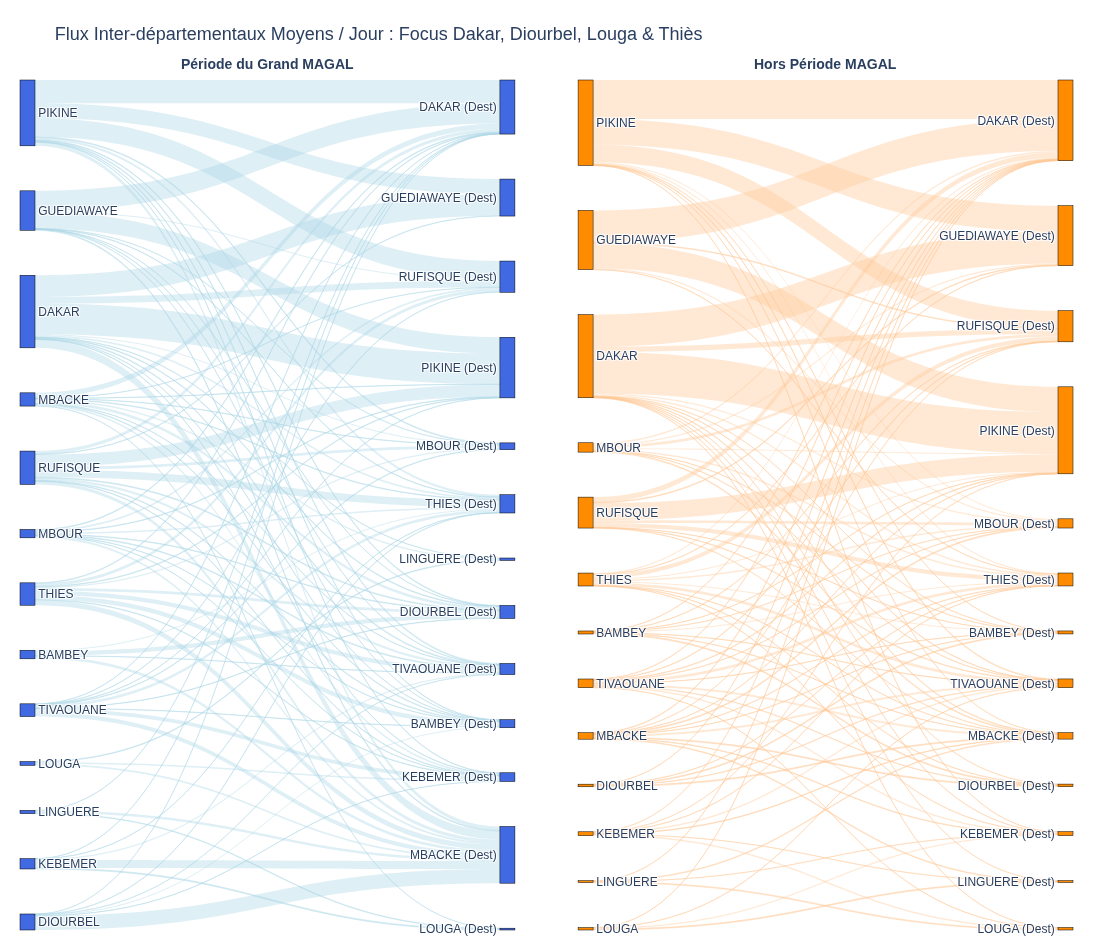

In [5]:
# 1. Définition des 4 régions cibles et de leurs départements
regions_magal = ['DAKAR', 'DIOURBEL', 'LOUGA', 'THIES']

df_regions_filtre  = df_regions[df_regions['REG'].isin(regions_magal)]

# 3. Application du filtre
matrice_magal_filtre = matrice_magal.loc[matrice_magal.index.isin(df_regions_filtre['ARR_ID'] -1), matrice_magal.columns.isin(df_regions_filtre['ARR_ID'] -1)]
matrice_simple_filtre = matrice_simple.loc[matrice_simple.index.isin(df_regions_filtre['ARR_ID'] -1), matrice_simple.columns.isin(df_regions_filtre['ARR_ID'] -1)]

# 1. Création du dictionnaire de correspondance : { id: "NOM" }
mapping_noms = df_regions.set_index(df_regions['ARR_ID'] - 1)['ARR'].to_dict()

# 2. Application du dictionnaire aux lignes (index) et aux colonnes
matrice_magal_filtre = matrice_magal_filtre.rename(index=mapping_noms, columns=mapping_noms)
matrice_simple_filtre = matrice_simple_filtre.rename(index=mapping_noms, columns=mapping_noms)



# ==============================================================================
# 1. CRÉATION DU MAPPING : ID AJUSTÉ (0-122) -> NOM DU DÉPARTEMENT
# ==============================================================================
# On applique le -1 sur 'ARR_ID' pour être parfaitement aligné avec vos matrices
mapping_nom_arr_to_dept = df_regions_filtre.set_index('ARR')['DEPT'].to_dict()


# ==============================================================================
# 2. FONCTION D'AGRÉGATION ET DE FILTRAGE
# ==============================================================================
def agreger_matrice_de_noms_au_departement(matrice_noms_arr, mapping, depts_a_conserver):
    """
    Prend une matrice indexée par les NOMS d'arrondissements,
    la convertit en départements, fusionne les flux et filtre.
    """
    df = matrice_noms_arr.copy()
    
    # Étape A : On remplace les noms d'arrondissements par les noms de départements
    df.index = df.index.map(mapping)
    df.columns = df.columns.map(mapping)
    
    # Étape B : On fusionne par somme les arrondissements appartenant au même département
    df = df.groupby(level=0).sum()
    df = df.T.groupby(level=0).sum().T
    
    # Étape C : Réduction aux départements des 4 régions cibles
    df_reduit = df.loc[df.index.isin(depts_a_conserver), df.columns.isin(depts_a_conserver)]
    
    return df_reduit


# ==============================================================================
# 3. EXTRACTION DES DÉPARTEMENTS CIBLES & APPLICATION
# ==============================================================================
# 1. Extraction des départements des 4 régions majeures
regions_magal = ['DAKAR', 'DIOURBEL', 'LOUGA', 'THIES']
depts_cibles = df_regions[df_regions['REG'].isin(regions_magal)]['DEPT'].unique()

# 2. Transformation de vos matrices (qui possèdent déjà les noms d'arrondissements)
matrice_dep_magal = agreger_matrice_de_noms_au_departement(matrice_magal_filtre, mapping_nom_arr_to_dept, depts_cibles)
matrice_dep_simple = agreger_matrice_de_noms_au_departement(matrice_simple_filtre, mapping_nom_arr_to_dept, depts_cibles)


# Appel de votre fonction inchangée avec les nouvelles matrices départementales
fig_comparatif_dept = tracer_double_sankey_flux(
    matrice_magal=matrice_dep_magal,       # La matrice départementale Magal
    matrice_simple=matrice_dep_simple,     # La matrice départementale Hors-Magal
    nb_jours_magal=9,                  
    nb_jours_simple=90,                
    quantile_filtre=0.4,                    # Filtre un peu plus bas pour voir plus de liens
    chemin_sauvegarde="./Deplacement_MAGAL/Sankey_Departements_Top_Regions.html",
    titre_general="Flux Inter-départementaux Moyens / Jour : Focus Dakar, Diourbel, Louga & Thiès"
)

## 1. Observations et Analyses

- Le premier diagramme de Sankey à l'echelle Regionale nous permet de verifier le fait que sur la période du 1er Janvier et du 22 Décembre une grande partie des populations du Sénégal ont concentré leurs deplacement vers la région de DIOURBEL pour célébrer le GRAND MAGAL de TOUBA.
- On constate une claire augmentation du flux journalier habituel de la region de Diourbel qui quitte de 3060 déplacements entrants à 6890.
- Aussi, les régions qui enregistrent le plus grand taux de déplacements vers DIOURBEL sont les regions de DAKAR, THIES et LOUGA. 
- En decendant pour plus de précision au niveau des départements, on constate que MBACKE (departement ou à lieu le pélérinage) qui avait un flux journalier d'environ 1900 deplacements entrants, comptabilise pendant cette période plus de 6190 déplacements entrants.

## 2. Nos propositions concrètes pour fluidifier la circulation

Au vue des differentes analyses et observations que nous avons faites, la solution cocrete que nous proposons est la suivante
- **Solution : Réseau de transport évènementiel et temporaire**
- **L'idée :** L'idée c'est de mettre a la disposition des populations des moyens de transport de masse (Bus, car, etc..) quelques jours avant et après l'évènement afin de faciliter l'accès a la region de Diourbel et à ses departements plus particulierement Mbacke. Aussi, etant donnée que les regions de **DAKAR, THIES ET LOUGA** constituent les regions qui enregistrent le plus grand taux de mobilité entrante dans **DIOURBEL (plus de 82% des déplacements entrants)**, on pourrait n'appliquer la présente solution qu'à ces regions car les déplacements n'étant pas très intenses dans les autres regions, les reseaux de transports existant pourrait déja couvrir les déplacements des populations dans ces zones.